# <center> <b> Reconstruction and curvature lines for a trifoild aberration surface</b> </center>

## <b> <center> Analysis of the sample image </center> </b>

### Reading and displaying the pattern from preprocessing results

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


from matplotlib import rc
rc('font',**{'family':'serif','serif':['Times New Roman']})
rc('text', usetex=True)

In [17]:
df = pd.read_csv("./../data/21-09-26-od-corregido.txt", sep=r"\s+", header=None)

In [18]:
df.head(10)

,0,1,2
0,1,204.433277,465.327879
1,2,234.881392,317.075633
2,3,237.822822,356.756919
3,4,238.284580,390.811440
4,5,239.800777,426.430250
5,6,239.928182,461.251535
6,7,239.354875,499.565846
7,8,240.826840,537.121170
8,9,242.927499,575.097732
9,10,238.752296,610.284711


In [19]:
df.rename(columns={0:'pos', 2:'y', 1:'x'}, inplace=True)

In [20]:
df.head(10)

,pos,x,y
0,1,204.433277,465.327879
1,2,234.881392,317.075633
2,3,237.822822,356.756919
3,4,238.284580,390.811440
4,5,239.800777,426.430250
5,6,239.928182,461.251535
6,7,239.354875,499.565846
7,8,240.826840,537.121170
8,9,242.927499,575.097732
9,10,238.752296,610.284711


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253 entries, 0 to 252
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pos     253 non-null    int64  
 1   x       253 non-null    float64
 2   y       253 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 6.1 KB


In [22]:
df.describe()

,pos,x,y
count,253.000000,253.000000,253.000000
mean,127.000000,548.635736,466.371612
std,73.179004,175.026183,166.189317
min,1.000000,204.433277,129.639486
25%,64.000000,396.123336,321.326725
50%,127.000000,547.559793,467.193333
75%,190.000000,697.261766,610.263711
max,253.000000,903.942099,801.632102


In [23]:
#  Tamano del lienzo de dibujo.  Estas imagenes son de 1024x1024; con el 480
#  heredado de los experimentos anteriores, matA[y][x] con y hasta 903 lanza
#  IndexError.  Solo se usa para VISUALIZAR: no entra en ningun calculo.
TAM = 1024
matA = np.zeros((TAM, TAM))

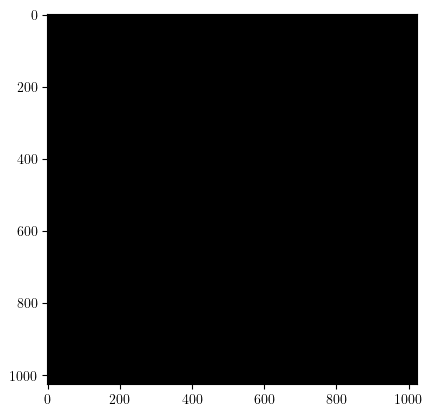

In [24]:
plt.imshow(matA, cmap="gray")

In [25]:
#  ESCALA px -> mm.  Es la UNICA constante que convierte pixeles en milimetros.
#  El 0.02 heredado venia de '0.4 mm cada 20 pixeles', pero en estas imagenes de
#  1024x1024 el paso medido de la rejilla es 37.923969 px, asi que:
#
#        delta = paso_fisico_de_la_rejilla [mm] / 37.923969 [px]
#
#  Se toma paso_fisico = 0.4 mm para ser coherente con el p = 0.4 que usan las
#  celdas de analisis mas abajo.  SI EL PASO REAL DEL PROYECTOR NO ES 0.4 mm,
#  hay que cambiar PASO_REJILLA_MM aqui y el p de las celdas de analisis: son el
#  mismo numero.  Con delta = 0.02 la apertura saldria de 14.3 mm, imposible.
PASO_REJILLA_MM = 0.4
PASO_REJILLA_PX = 37.923969
delta = PASO_REJILLA_MM / PASO_REJILLA_PX
print('delta = %.6f mm/px   ->  apertura = %.2f mm' % (delta, 18 * PASO_REJILLA_PX * delta))

#  X: eje de coordenadas en mm a lo ancho del lienzo.  Lo usa la celda siguiente.
X = np.linspace(0, TAM*delta + delta, TAM)

delta = 0.010547 mm/px   ->  apertura = 7.20 mm


In [26]:
np.max(X)

10.811104713222395

In [27]:
#The coordinates are in pixels, so they are integers and should be threated as that
#However, to be more exact, it will be better leave the x and y coordinates with decimals and then apply the 
#scale paratemer. So, this is only for give and idea, it is not correct to perform computations
df_img_pattern = np.floor(df).astype(int)

In [28]:
df_img_pattern.head(5)

,pos,x,y
0,1,204,465
1,2,234,317
2,3,237,356
3,4,238,390
4,5,239,426


In [29]:
df.head(5)

,pos,x,y
0,1,204.433277,465.327879
1,2,234.881392,317.075633
2,3,237.822822,356.756919
3,4,238.284580,390.811440
4,5,239.800777,426.430250


In [30]:
N = df.shape[0]   # numero de centroides del patron
matA = np.zeros((TAM, TAM))

#  OJO: aqui estaba el bug.  Esta celda indexaba matA[x][y] mientras que la
#  celda equivalente de la referencia usa matA_hpref[y][x].  Con convenciones
#  opuestas, la grafica de comparacion dibujaba el patron de prueba
#  transpuesto: mostraba 299 px de desplazamiento donde hay 7.5 px.
for ii in range(0, N):
    matA[df_img_pattern['y'][ii]][df_img_pattern['x'][ii]] = 1
print('%d puntos dibujados' % N)

253 puntos dibujados


Text(0, 0.5, 'Height [pixels]')

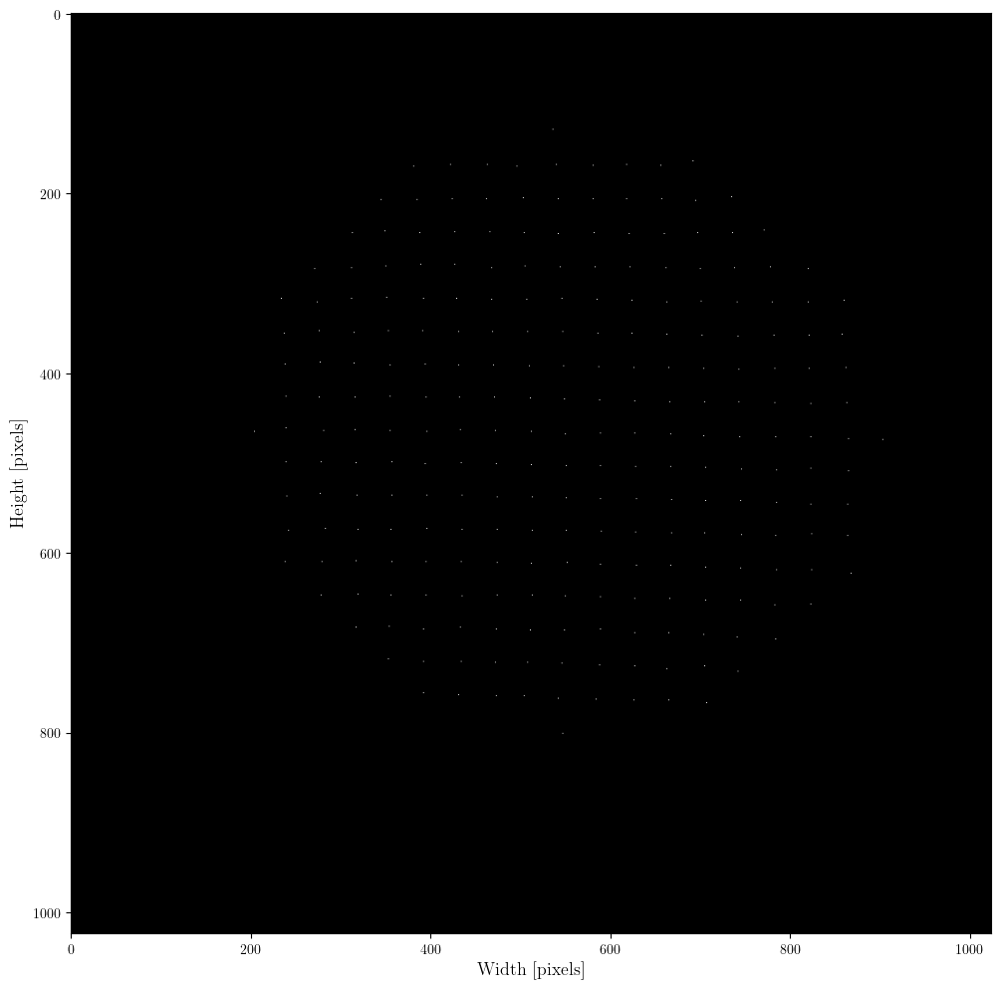

In [31]:
plt.figure(figsize=(12,12))
plt.imshow(matA, cmap="gray")
plt.xlabel('Width [pixels]', size=13)
plt.ylabel('Height [pixels]', size=13)

In [32]:
df["x_d"] = df["x"] * delta
df["y_d"] = df["y"] * delta

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253 entries, 0 to 252
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pos     253 non-null    int64  
 1   x       253 non-null    float64
 2   y       253 non-null    float64
 3   x_d     253 non-null    float64
 4   y_d     253 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 10.0 KB


In [34]:
df.head(10)

,pos,x,y,x_d,y_d
0,1,204.433277,465.327879,2.156243,4.908008
1,2,234.881392,317.075633,2.477393,3.344330
2,3,237.822822,356.756919,2.508417,3.762865
3,4,238.284580,390.811440,2.513287,4.122052
4,5,239.800777,426.430250,2.529279,4.497739
5,6,239.928182,461.251535,2.530623,4.865013
6,7,239.354875,499.565846,2.524576,5.269130
7,8,240.826840,537.121170,2.540102,5.665242
8,9,242.927499,575.097732,2.562258,6.065797
9,10,238.752296,610.284711,2.518221,6.436929


### Building the matrix (17x17) of x positions

In [35]:
mat_R_X = np.zeros((19,19))

In [36]:
mat_R_X[9][0] = df["x_d"][0]

mat_R_X[5][1] = df["x_d"][1]
mat_R_X[6][1] = df["x_d"][2]
mat_R_X[7][1] = df["x_d"][3]
mat_R_X[8][1] = df["x_d"][4]
mat_R_X[9][1] = df["x_d"][5]
mat_R_X[10][1] = df["x_d"][6]
mat_R_X[11][1] = df["x_d"][7]
mat_R_X[12][1] = df["x_d"][8]
mat_R_X[13][1] = df["x_d"][9]

mat_R_X[4][2] = df["x_d"][10]
mat_R_X[5][2] = df["x_d"][11]
mat_R_X[6][2] = df["x_d"][12]
mat_R_X[7][2] = df["x_d"][13]
mat_R_X[8][2] = df["x_d"][14]
mat_R_X[9][2] = df["x_d"][15]
mat_R_X[10][2] = df["x_d"][16]
mat_R_X[11][2] = df["x_d"][17]
mat_R_X[12][2] = df["x_d"][18]
mat_R_X[13][2] = df["x_d"][19]
mat_R_X[14][2] = df["x_d"][20]

mat_R_X[3][3] = df["x_d"][21]
mat_R_X[4][3] = df["x_d"][22]
mat_R_X[5][3] = df["x_d"][23]
mat_R_X[6][3] = df["x_d"][24]
mat_R_X[7][3] = df["x_d"][25]
mat_R_X[8][3] = df["x_d"][26]
mat_R_X[9][3] = df["x_d"][27]
mat_R_X[10][3] = df["x_d"][28]
mat_R_X[11][3] = df["x_d"][29]
mat_R_X[12][3] = df["x_d"][30]
mat_R_X[13][3] = df["x_d"][31]
mat_R_X[14][3] = df["x_d"][32]
mat_R_X[15][3] = df["x_d"][33]

mat_R_X[2][4] = df["x_d"][34]
mat_R_X[3][4] = df["x_d"][35]
mat_R_X[4][4] = df["x_d"][36]
mat_R_X[5][4] = df["x_d"][37]
mat_R_X[6][4] = df["x_d"][38]
mat_R_X[7][4] = df["x_d"][39]
mat_R_X[8][4] = df["x_d"][40]
mat_R_X[9][4] = df["x_d"][41]
mat_R_X[10][4] = df["x_d"][42]
mat_R_X[11][4] = df["x_d"][43]
mat_R_X[12][4] = df["x_d"][44]
mat_R_X[13][4] = df["x_d"][45]
mat_R_X[14][4] = df["x_d"][46]
mat_R_X[15][4] = df["x_d"][47]
mat_R_X[16][4] = df["x_d"][48]

In [37]:
counter = 49
for ii in range(5,14):
    if (ii == 9 ):
        for jj in range(0, 19):
            mat_R_X[jj][ii] = df["x_d"][counter]      
            counter+=1        
    else:
        for jj in range(1,18):
            mat_R_X[jj][ii] = df["x_d"][counter] 
            counter+=1

In [38]:
mat_R_X[2][14] = df["x_d"][204]
mat_R_X[3][14] = df["x_d"][205]
mat_R_X[4][14] = df["x_d"][206]
mat_R_X[5][14] = df["x_d"][207]
mat_R_X[6][14] = df["x_d"][208]
mat_R_X[7][14] = df["x_d"][209]
mat_R_X[8][14] = df["x_d"][210]
mat_R_X[9][14] = df["x_d"][211]
mat_R_X[10][14] = df["x_d"][212]
mat_R_X[11][14] = df["x_d"][213]
mat_R_X[12][14] = df["x_d"][214]
mat_R_X[13][14] = df["x_d"][215]
mat_R_X[14][14] = df["x_d"][216]
mat_R_X[15][14] = df["x_d"][217]
mat_R_X[16][14] = df["x_d"][218]

mat_R_X[3][15] = df["x_d"][219]
mat_R_X[4][15] = df["x_d"][220]
mat_R_X[5][15] = df["x_d"][221]
mat_R_X[6][15] = df["x_d"][222]
mat_R_X[7][15] = df["x_d"][223]
mat_R_X[8][15] = df["x_d"][224]
mat_R_X[9][15] = df["x_d"][225]
mat_R_X[10][15] = df["x_d"][226]
mat_R_X[11][15] = df["x_d"][227]
mat_R_X[12][15] = df["x_d"][228]
mat_R_X[13][15] = df["x_d"][229]
mat_R_X[14][15] = df["x_d"][230]
mat_R_X[15][15] = df["x_d"][231]

mat_R_X[4][16] = df["x_d"][232]
mat_R_X[5][16] = df["x_d"][233]
mat_R_X[6][16] = df["x_d"][234]
mat_R_X[7][16] = df["x_d"][235]
mat_R_X[8][16] = df["x_d"][236]
mat_R_X[9][16] = df["x_d"][237]
mat_R_X[10][16] = df["x_d"][238]
mat_R_X[11][16] = df["x_d"][239]
mat_R_X[12][16] = df["x_d"][240]
mat_R_X[13][16] = df["x_d"][241]
mat_R_X[14][16] = df["x_d"][242]

mat_R_X[5][17] = df["x_d"][243]
mat_R_X[6][17] = df["x_d"][244]
mat_R_X[7][17] = df["x_d"][245]
mat_R_X[8][17] = df["x_d"][246]
mat_R_X[9][17] = df["x_d"][247]
mat_R_X[10][17] = df["x_d"][248]
mat_R_X[11][17] = df["x_d"][249]
mat_R_X[12][17] = df["x_d"][250]
mat_R_X[13][17] = df["x_d"][251]

mat_R_X[9][18] = df["x_d"][252]

Text(0.5, 1.0, 'X positions')

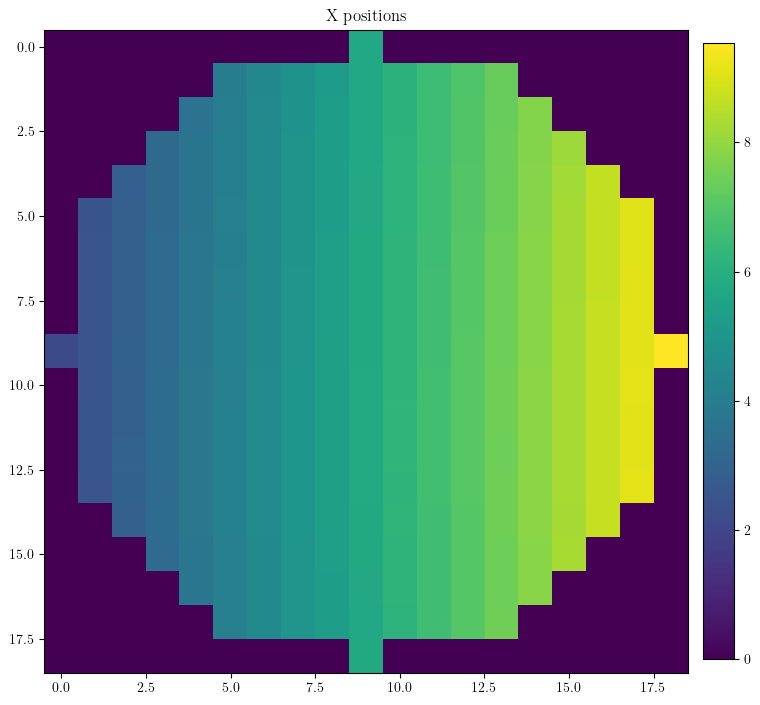

In [39]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_R_X) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("X positions")

In [40]:
npmat_R_X = np.array(mat_R_X)

### Building the matrix (17x17) for the y positions

In [41]:
mat_R_Y = np.zeros((19,19))

In [42]:
mat_R_Y[9][0] = df["y_d"][0]

mat_R_Y[5][1] = df["y_d"][1]
mat_R_Y[6][1] = df["y_d"][2]
mat_R_Y[7][1] = df["y_d"][3]
mat_R_Y[8][1] = df["y_d"][4]
mat_R_Y[9][1] = df["y_d"][5]
mat_R_Y[10][1] = df["y_d"][6]
mat_R_Y[11][1] = df["y_d"][7]
mat_R_Y[12][1] = df["y_d"][8]
mat_R_Y[13][1] = df["y_d"][9]

mat_R_Y[4][2] = df["y_d"][10]
mat_R_Y[5][2] = df["y_d"][11]
mat_R_Y[6][2] = df["y_d"][12]
mat_R_Y[7][2] = df["y_d"][13]
mat_R_Y[8][2] = df["y_d"][14]
mat_R_Y[9][2] = df["y_d"][15]
mat_R_Y[10][2] = df["y_d"][16]
mat_R_Y[11][2] = df["y_d"][17]
mat_R_Y[12][2] = df["y_d"][18]
mat_R_Y[13][2] = df["y_d"][19]
mat_R_Y[14][2] = df["y_d"][20]

mat_R_Y[3][3] = df["y_d"][21]
mat_R_Y[4][3] = df["y_d"][22]
mat_R_Y[5][3] = df["y_d"][23]
mat_R_Y[6][3] = df["y_d"][24]
mat_R_Y[7][3] = df["y_d"][25]
mat_R_Y[8][3] = df["y_d"][26]
mat_R_Y[9][3] = df["y_d"][27]
mat_R_Y[10][3] = df["y_d"][28]
mat_R_Y[11][3] = df["y_d"][29]
mat_R_Y[12][3] = df["y_d"][30]
mat_R_Y[13][3] = df["y_d"][31]
mat_R_Y[14][3] = df["y_d"][32]
mat_R_Y[15][3] = df["y_d"][33]

mat_R_Y[2][4] = df["y_d"][34]
mat_R_Y[3][4] = df["y_d"][35]
mat_R_Y[4][4] = df["y_d"][36]
mat_R_Y[5][4] = df["y_d"][37]
mat_R_Y[6][4] = df["y_d"][38]
mat_R_Y[7][4] = df["y_d"][39]
mat_R_Y[8][4] = df["y_d"][40]
mat_R_Y[9][4] = df["y_d"][41]
mat_R_Y[10][4] = df["y_d"][42]
mat_R_Y[11][4] = df["y_d"][43]
mat_R_Y[12][4] = df["y_d"][44]
mat_R_Y[13][4] = df["y_d"][45]
mat_R_Y[14][4] = df["y_d"][46]
mat_R_Y[15][4] = df["y_d"][47]
mat_R_Y[16][4] = df["y_d"][48]

In [43]:
counter = 49
for ii in range(5,14):
    if (ii == 9 ):
        for jj in range(0, 19):
            mat_R_Y[jj][ii] = df["y_d"][counter]      
            counter+=1        
    else:
        for jj in range(1,18):
            mat_R_Y[jj][ii] = df["y_d"][counter] 
            counter+=1

In [44]:
mat_R_Y[2][14] = df["y_d"][204]
mat_R_Y[3][14] = df["y_d"][205]
mat_R_Y[4][14] = df["y_d"][206]
mat_R_Y[5][14] = df["y_d"][207]
mat_R_Y[6][14] = df["y_d"][208]
mat_R_Y[7][14] = df["y_d"][209]
mat_R_Y[8][14] = df["y_d"][210]
mat_R_Y[9][14] = df["y_d"][211]
mat_R_Y[10][14] = df["y_d"][212]
mat_R_Y[11][14] = df["y_d"][213]
mat_R_Y[12][14] = df["y_d"][214]
mat_R_Y[13][14] = df["y_d"][215]
mat_R_Y[14][14] = df["y_d"][216]
mat_R_Y[15][14] = df["y_d"][217]
mat_R_Y[16][14] = df["y_d"][218]

mat_R_Y[3][15] = df["y_d"][219]
mat_R_Y[4][15] = df["y_d"][220]
mat_R_Y[5][15] = df["y_d"][221]
mat_R_Y[6][15] = df["y_d"][222]
mat_R_Y[7][15] = df["y_d"][223]
mat_R_Y[8][15] = df["y_d"][224]
mat_R_Y[9][15] = df["y_d"][225]
mat_R_Y[10][15] = df["y_d"][226]
mat_R_Y[11][15] = df["y_d"][227]
mat_R_Y[12][15] = df["y_d"][228]
mat_R_Y[13][15] = df["y_d"][229]
mat_R_Y[14][15] = df["y_d"][230]
mat_R_Y[15][15] = df["y_d"][231]

mat_R_Y[4][16] = df["y_d"][232]
mat_R_Y[5][16] = df["y_d"][233]
mat_R_Y[6][16] = df["y_d"][234]
mat_R_Y[7][16] = df["y_d"][235]
mat_R_Y[8][16] = df["y_d"][236]
mat_R_Y[9][16] = df["y_d"][237]
mat_R_Y[10][16] = df["y_d"][238]
mat_R_Y[11][16] = df["y_d"][239]
mat_R_Y[12][16] = df["y_d"][240]
mat_R_Y[13][16] = df["y_d"][241]
mat_R_Y[14][16] = df["y_d"][242]

mat_R_Y[5][17] = df["y_d"][243]
mat_R_Y[6][17] = df["y_d"][244]
mat_R_Y[7][17] = df["y_d"][245]
mat_R_Y[8][17] = df["y_d"][246]
mat_R_Y[9][17] = df["y_d"][247]
mat_R_Y[10][17] = df["y_d"][248]
mat_R_Y[11][17] = df["y_d"][249]
mat_R_Y[12][17] = df["y_d"][250]
mat_R_Y[13][17] = df["y_d"][251]

mat_R_Y[9][18] = df["y_d"][252]

Text(0.5, 1.0, 'Y positions')

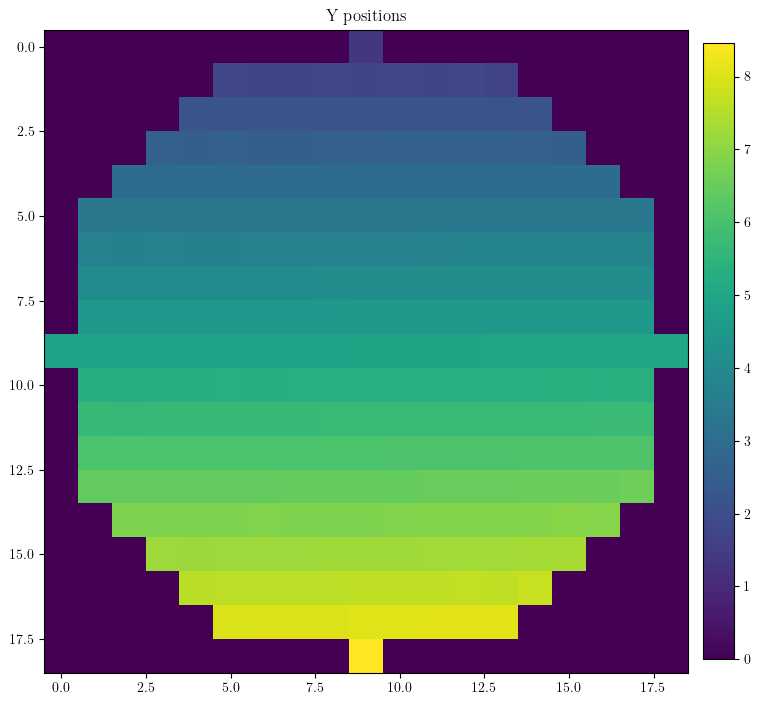

In [45]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_R_Y) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("Y positions")

## <center> <b>Analysis of the reference image</b> </center>

### Reading and displaying the pattern from preprocessing results

In [46]:
df_hpref = pd.read_csv("./../data/21-09-26-ref-sintetica.txt", sep=r"\s+", header=None)

In [47]:
df_hpref.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253 entries, 0 to 252
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       253 non-null    int64  
 1   1       253 non-null    float64
 2   2       253 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 6.1 KB


In [48]:
df_hpref.rename(columns={0:'pos', 2:'y', 1:'x'}, inplace=True)

In [49]:
df_hpref.head(3)

,pos,x,y
0,1,208.684328,468.189570
1,2,246.524038,316.472652
2,3,246.545101,354.396616


In [50]:
matA_hpref = np.zeros((TAM, TAM))

In [51]:
delta = PASO_REJILLA_MM / PASO_REJILLA_PX   # misma escala que el patron de prueba
X = np.linspace(0, TAM*delta + delta, TAM)

In [52]:
df_img_ref = np.floor(df_hpref).astype(int)

In [53]:
df_img_ref.head(5)

,pos,x,y
0,1,208,468
1,2,246,316
2,3,246,354
3,4,246,392
4,5,246,430


In [54]:
N = df_hpref.shape[0] #Number of centroids in the pattern

counter = 0 #Just to verify
for ii in range(0,N):
    matA_hpref[df_img_ref["y"][ii]][df_img_ref["x"][ii]] = 1
    counter += 1
counter 

253

Text(0, 0.5, 'Height [pixels]')

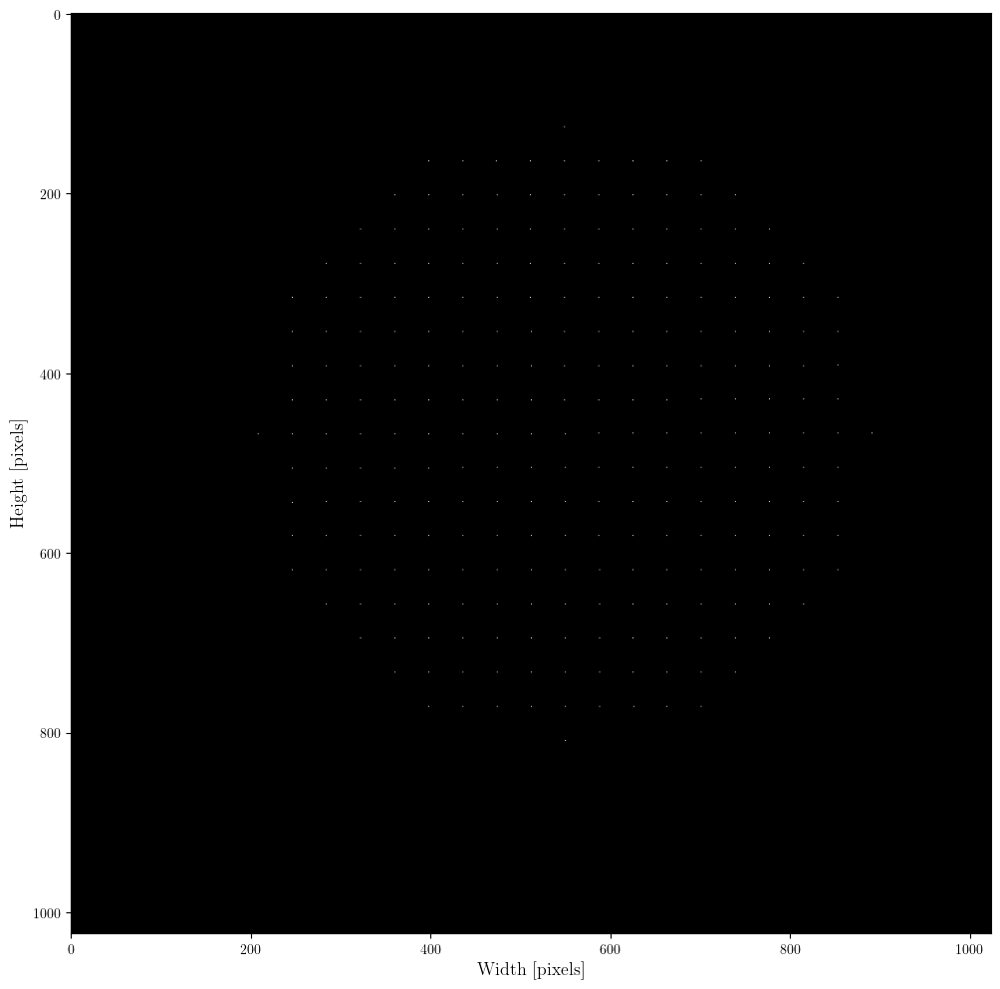

In [55]:
plt.figure(figsize=(12,12))
plt.imshow(matA_hpref, cmap="grey")
plt.xlabel('Width [pixels]', size=13)
plt.ylabel('Height [pixels]', size=13)

### <b> Comparison </b> between the pattern of points generated by reference surface and right eye 

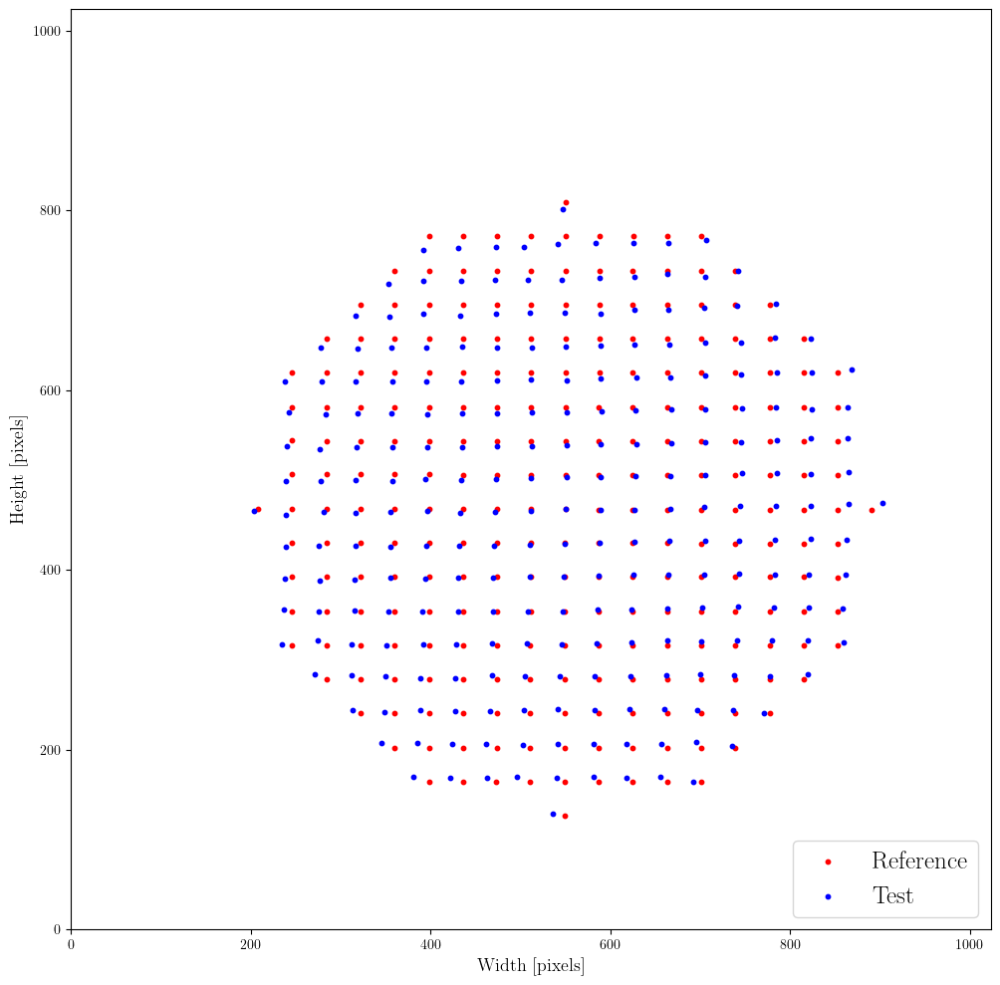

In [56]:
plt.figure(figsize=(12, 12))

#  Ambas matrices se rellenan ya como mat[y][x] (ver celdas 17 y 45), asi que
#  np.nonzero devuelve (filas, columnas) = (y, x) en las dos y se dibujan igual.
#  Antes la celda 17 usaba matA[x][y] y aqui se dibujaba scatter(y, x): el test
#  salia transpuesto y aparentaba 299 px de desviacion donde hay 7.5 px.
y1, x1 = np.nonzero(matA_hpref)
y2, x2 = np.nonzero(matA)

plt.imshow(np.ones_like(matA), cmap='gray', vmin=0, vmax=1)

plt.scatter(x1, y1, c='red',  s=10, label='Reference')
plt.scatter(x2, y2, c='blue', s=10, label='Test')

plt.xlabel('Width [pixels]', size=13)
plt.ylabel('Height [pixels]', size=13)
plt.legend(fontsize=18, loc='lower right')
plt.gca().invert_yaxis()
plt.show()

### Building the matrix (17x17) of X positions

In [57]:
df_hpref["x_d"] = df_hpref["x"] * delta
df_hpref["y_d"] = df_hpref["y"] * delta

In [58]:
df_hpref.head(10)

,pos,x,y,x_d,y_d
0,1,208.684328,468.189570,2.201081,4.938192
1,2,246.524038,316.472652,2.600192,3.337970
2,3,246.545101,354.396616,2.600415,3.737970
3,4,246.566164,392.320579,2.600637,4.137970
4,5,246.587228,430.244543,2.600859,4.537970
5,6,246.608291,468.168507,2.601081,4.937970
6,7,246.629354,506.092470,2.601303,5.337969
7,8,246.650418,544.016434,2.601525,5.737969
8,9,246.671481,581.940398,2.601748,6.137969
9,10,246.692544,619.864361,2.601970,6.537969


In [59]:
mat_R_X_hpref = np.zeros((19,19))

In [60]:
dasd = df_hpref[df_hpref["pos"]==1]["x_d"].values[0]
dasd

2.201081089903855

In [61]:
mat_R_X_hpref[9][0] = df_hpref[df_hpref["pos"]==1]["x_d"].values[0]

mat_R_X_hpref[5][1] = df_hpref[df_hpref["pos"]==2]["x_d"].values[0]
mat_R_X_hpref[6][1] = df_hpref[df_hpref["pos"]==3]["x_d"].values[0]
mat_R_X_hpref[7][1] = df_hpref[df_hpref["pos"]==4]["x_d"].values[0]
mat_R_X_hpref[8][1] = df_hpref[df_hpref["pos"]==5]["x_d"].values[0]
mat_R_X_hpref[9][1] = df_hpref[df_hpref["pos"]==6]["x_d"].values[0]
mat_R_X_hpref[10][1] = df_hpref[df_hpref["pos"]==7]["x_d"].values[0]
mat_R_X_hpref[11][1] = df_hpref[df_hpref["pos"]==8]["x_d"].values[0]
mat_R_X_hpref[12][1] = df_hpref[df_hpref["pos"]==9]["x_d"].values[0]
mat_R_X_hpref[13][1] = df_hpref[df_hpref["pos"]==10]["x_d"].values[0]

mat_R_X_hpref[4][2] = df_hpref[df_hpref["pos"]==11]["x_d"].values[0]
mat_R_X_hpref[5][2] = df_hpref[df_hpref["pos"]==12]["x_d"].values[0]
mat_R_X_hpref[6][2] = df_hpref[df_hpref["pos"]==13]["x_d"].values[0]
mat_R_X_hpref[7][2] = df_hpref[df_hpref["pos"]==14]["x_d"].values[0]
mat_R_X_hpref[8][2] = df_hpref[df_hpref["pos"]==15]["x_d"].values[0]
mat_R_X_hpref[9][2] = df_hpref[df_hpref["pos"]==16]["x_d"].values[0]
mat_R_X_hpref[10][2] = df_hpref[df_hpref["pos"]==17]["x_d"].values[0]
mat_R_X_hpref[11][2] = df_hpref[df_hpref["pos"]==18]["x_d"].values[0]
mat_R_X_hpref[12][2] = df_hpref[df_hpref["pos"]==19]["x_d"].values[0]
mat_R_X_hpref[13][2] = df_hpref[df_hpref["pos"]==20]["x_d"].values[0]
mat_R_X_hpref[14][2] = df_hpref[df_hpref["pos"]==21]["x_d"].values[0]

mat_R_X_hpref[3][3] = df_hpref[df_hpref["pos"]==22]["x_d"].values[0]
mat_R_X_hpref[4][3] = df_hpref[df_hpref["pos"]==23]["x_d"].values[0]
mat_R_X_hpref[5][3] = df_hpref[df_hpref["pos"]==24]["x_d"].values[0]
mat_R_X_hpref[6][3] = df_hpref[df_hpref["pos"]==25]["x_d"].values[0]
mat_R_X_hpref[7][3] = df_hpref[df_hpref["pos"]==26]["x_d"].values[0]
mat_R_X_hpref[8][3] = df_hpref[df_hpref["pos"]==27]["x_d"].values[0]
mat_R_X_hpref[9][3] = df_hpref[df_hpref["pos"]==28]["x_d"].values[0]
mat_R_X_hpref[10][3] = df_hpref[df_hpref["pos"]==29]["x_d"].values[0]
mat_R_X_hpref[11][3] = df_hpref[df_hpref["pos"]==30]["x_d"].values[0]
mat_R_X_hpref[12][3] = df_hpref[df_hpref["pos"]==31]["x_d"].values[0]
mat_R_X_hpref[13][3] = df_hpref[df_hpref["pos"]==32]["x_d"].values[0]
mat_R_X_hpref[14][3] = df_hpref[df_hpref["pos"]==33]["x_d"].values[0]
mat_R_X_hpref[15][3] = df_hpref[df_hpref["pos"]==34]["x_d"].values[0]

mat_R_X_hpref[2][4] = df_hpref[df_hpref["pos"]==35]["x_d"].values[0]
mat_R_X_hpref[3][4] = df_hpref[df_hpref["pos"]==36]["x_d"].values[0]
mat_R_X_hpref[4][4] = df_hpref[df_hpref["pos"]==37]["x_d"].values[0]
mat_R_X_hpref[5][4] = df_hpref[df_hpref["pos"]==38]["x_d"].values[0]
mat_R_X_hpref[6][4] = df_hpref[df_hpref["pos"]==39]["x_d"].values[0]
mat_R_X_hpref[7][4] = df_hpref[df_hpref["pos"]==40]["x_d"].values[0]
mat_R_X_hpref[8][4] = df_hpref[df_hpref["pos"]==41]["x_d"].values[0]
mat_R_X_hpref[9][4] = df_hpref[df_hpref["pos"]==42]["x_d"].values[0]
mat_R_X_hpref[10][4] = df_hpref[df_hpref["pos"]==43]["x_d"].values[0]
mat_R_X_hpref[11][4] = df_hpref[df_hpref["pos"]==44]["x_d"].values[0]
mat_R_X_hpref[12][4] = df_hpref[df_hpref["pos"]==45]["x_d"].values[0]
mat_R_X_hpref[13][4] = df_hpref[df_hpref["pos"]==46]["x_d"].values[0]
mat_R_X_hpref[14][4] = df_hpref[df_hpref["pos"]==47]["x_d"].values[0]
mat_R_X_hpref[15][4] = df_hpref[df_hpref["pos"]==48]["x_d"].values[0]
mat_R_X_hpref[16][4] = df_hpref[df_hpref["pos"]==49]["x_d"].values[0]

In [62]:
counter = 50  # Starting from position 50 (since we ended at 49 previously)

for ii in range(5,14):
    if (ii == 9 ):
        for jj in range(0, 19):
            mat_R_X_hpref[jj][ii] = df_hpref[df_hpref["pos"]==counter]["x_d"].values[0]
            counter += 1        
    else:
        for jj in range(1,18):
            mat_R_X_hpref[jj][ii] = df_hpref[df_hpref["pos"]==counter]["x_d"].values[0]
            counter += 1

In [63]:
mat_R_X_hpref[2][14] = df_hpref[df_hpref["pos"]==205]["x_d"].values[0]
mat_R_X_hpref[3][14] = df_hpref[df_hpref["pos"]==206]["x_d"].values[0]
mat_R_X_hpref[4][14] = df_hpref[df_hpref["pos"]==207]["x_d"].values[0]
mat_R_X_hpref[5][14] = df_hpref[df_hpref["pos"]==208]["x_d"].values[0]
mat_R_X_hpref[6][14] = df_hpref[df_hpref["pos"]==209]["x_d"].values[0]
mat_R_X_hpref[7][14] = df_hpref[df_hpref["pos"]==210]["x_d"].values[0]
mat_R_X_hpref[8][14] = df_hpref[df_hpref["pos"]==211]["x_d"].values[0]
mat_R_X_hpref[9][14] = df_hpref[df_hpref["pos"]==212]["x_d"].values[0]
mat_R_X_hpref[10][14] = df_hpref[df_hpref["pos"]==213]["x_d"].values[0]
mat_R_X_hpref[11][14] = df_hpref[df_hpref["pos"]==214]["x_d"].values[0]
mat_R_X_hpref[12][14] = df_hpref[df_hpref["pos"]==215]["x_d"].values[0]
mat_R_X_hpref[13][14] = df_hpref[df_hpref["pos"]==216]["x_d"].values[0]
mat_R_X_hpref[14][14] = df_hpref[df_hpref["pos"]==217]["x_d"].values[0]
mat_R_X_hpref[15][14] = df_hpref[df_hpref["pos"]==218]["x_d"].values[0]
mat_R_X_hpref[16][14] = df_hpref[df_hpref["pos"]==219]["x_d"].values[0]

mat_R_X_hpref[3][15] = df_hpref[df_hpref["pos"]==220]["x_d"].values[0]
mat_R_X_hpref[4][15] = df_hpref[df_hpref["pos"]==221]["x_d"].values[0]
mat_R_X_hpref[5][15] = df_hpref[df_hpref["pos"]==222]["x_d"].values[0]
mat_R_X_hpref[6][15] = df_hpref[df_hpref["pos"]==223]["x_d"].values[0]
mat_R_X_hpref[7][15] = df_hpref[df_hpref["pos"]==224]["x_d"].values[0]
mat_R_X_hpref[8][15] = df_hpref[df_hpref["pos"]==225]["x_d"].values[0]
mat_R_X_hpref[9][15] = df_hpref[df_hpref["pos"]==226]["x_d"].values[0]
mat_R_X_hpref[10][15] = df_hpref[df_hpref["pos"]==227]["x_d"].values[0]
mat_R_X_hpref[11][15] = df_hpref[df_hpref["pos"]==228]["x_d"].values[0]
mat_R_X_hpref[12][15] = df_hpref[df_hpref["pos"]==229]["x_d"].values[0]
mat_R_X_hpref[13][15] = df_hpref[df_hpref["pos"]==230]["x_d"].values[0]
mat_R_X_hpref[14][15] = df_hpref[df_hpref["pos"]==231]["x_d"].values[0]
mat_R_X_hpref[15][15] = df_hpref[df_hpref["pos"]==232]["x_d"].values[0]

mat_R_X_hpref[4][16] = df_hpref[df_hpref["pos"]==233]["x_d"].values[0]
mat_R_X_hpref[5][16] = df_hpref[df_hpref["pos"]==234]["x_d"].values[0]
mat_R_X_hpref[6][16] = df_hpref[df_hpref["pos"]==235]["x_d"].values[0]
mat_R_X_hpref[7][16] = df_hpref[df_hpref["pos"]==236]["x_d"].values[0]
mat_R_X_hpref[8][16] = df_hpref[df_hpref["pos"]==237]["x_d"].values[0]
mat_R_X_hpref[9][16] = df_hpref[df_hpref["pos"]==238]["x_d"].values[0]
mat_R_X_hpref[10][16] = df_hpref[df_hpref["pos"]==239]["x_d"].values[0]
mat_R_X_hpref[11][16] = df_hpref[df_hpref["pos"]==240]["x_d"].values[0]
mat_R_X_hpref[12][16] = df_hpref[df_hpref["pos"]==241]["x_d"].values[0]
mat_R_X_hpref[13][16] = df_hpref[df_hpref["pos"]==242]["x_d"].values[0]
mat_R_X_hpref[14][16] = df_hpref[df_hpref["pos"]==243]["x_d"].values[0]

mat_R_X_hpref[5][17] = df_hpref[df_hpref["pos"]==244]["x_d"].values[0]
mat_R_X_hpref[6][17] = df_hpref[df_hpref["pos"]==245]["x_d"].values[0]
mat_R_X_hpref[7][17] = df_hpref[df_hpref["pos"]==246]["x_d"].values[0]
mat_R_X_hpref[8][17] = df_hpref[df_hpref["pos"]==247]["x_d"].values[0]
mat_R_X_hpref[9][17] = df_hpref[df_hpref["pos"]==248]["x_d"].values[0]
mat_R_X_hpref[10][17] = df_hpref[df_hpref["pos"]==249]["x_d"].values[0]
mat_R_X_hpref[11][17] = df_hpref[df_hpref["pos"]==250]["x_d"].values[0]
mat_R_X_hpref[12][17] = df_hpref[df_hpref["pos"]==251]["x_d"].values[0]
mat_R_X_hpref[13][17] = df_hpref[df_hpref["pos"]==252]["x_d"].values[0]

mat_R_X_hpref[9][18] = df_hpref[df_hpref["pos"]==253]["x_d"].values[0]

Text(0.5, 1.0, 'Y positions')

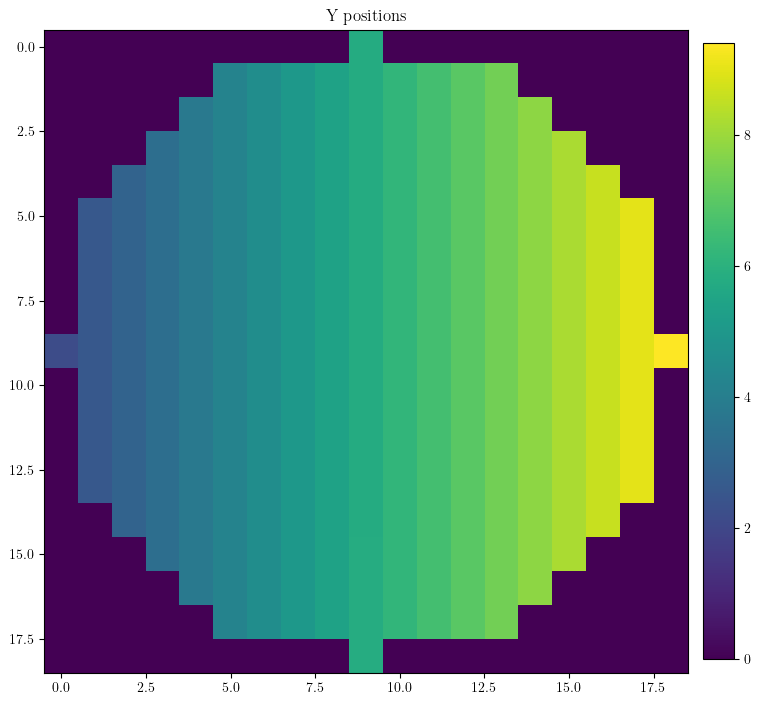

In [64]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_R_X_hpref)
cbar = plt.colorbar(im, shrink=0.8, pad=0.02)
plt.title("Y positions")

### Building the matrix (17x17) of Y positions

In [65]:
mat_R_Y_hpref = np.zeros((19,19))

In [66]:
mat_R_Y_hpref[9][0] = df_hpref[df_hpref["pos"]==1]["y_d"].values[0]

mat_R_Y_hpref[5][1] = df_hpref[df_hpref["pos"]==2]["y_d"].values[0]
mat_R_Y_hpref[6][1] = df_hpref[df_hpref["pos"]==3]["y_d"].values[0]
mat_R_Y_hpref[7][1] = df_hpref[df_hpref["pos"]==4]["y_d"].values[0]
mat_R_Y_hpref[8][1] = df_hpref[df_hpref["pos"]==5]["y_d"].values[0]
mat_R_Y_hpref[9][1] = df_hpref[df_hpref["pos"]==6]["y_d"].values[0]
mat_R_Y_hpref[10][1] = df_hpref[df_hpref["pos"]==7]["y_d"].values[0]
mat_R_Y_hpref[11][1] = df_hpref[df_hpref["pos"]==8]["y_d"].values[0]
mat_R_Y_hpref[12][1] = df_hpref[df_hpref["pos"]==9]["y_d"].values[0]
mat_R_Y_hpref[13][1] = df_hpref[df_hpref["pos"]==10]["y_d"].values[0]

mat_R_Y_hpref[4][2] = df_hpref[df_hpref["pos"]==11]["y_d"].values[0]
mat_R_Y_hpref[5][2] = df_hpref[df_hpref["pos"]==12]["y_d"].values[0]
mat_R_Y_hpref[6][2] = df_hpref[df_hpref["pos"]==13]["y_d"].values[0]
mat_R_Y_hpref[7][2] = df_hpref[df_hpref["pos"]==14]["y_d"].values[0]
mat_R_Y_hpref[8][2] = df_hpref[df_hpref["pos"]==15]["y_d"].values[0]
mat_R_Y_hpref[9][2] = df_hpref[df_hpref["pos"]==16]["y_d"].values[0]
mat_R_Y_hpref[10][2] = df_hpref[df_hpref["pos"]==17]["y_d"].values[0]
mat_R_Y_hpref[11][2] = df_hpref[df_hpref["pos"]==18]["y_d"].values[0]
mat_R_Y_hpref[12][2] = df_hpref[df_hpref["pos"]==19]["y_d"].values[0]
mat_R_Y_hpref[13][2] = df_hpref[df_hpref["pos"]==20]["y_d"].values[0]
mat_R_Y_hpref[14][2] = df_hpref[df_hpref["pos"]==21]["y_d"].values[0]

mat_R_Y_hpref[3][3] = df_hpref[df_hpref["pos"]==22]["y_d"].values[0]
mat_R_Y_hpref[4][3] = df_hpref[df_hpref["pos"]==23]["y_d"].values[0]
mat_R_Y_hpref[5][3] = df_hpref[df_hpref["pos"]==24]["y_d"].values[0]
mat_R_Y_hpref[6][3] = df_hpref[df_hpref["pos"]==25]["y_d"].values[0]
mat_R_Y_hpref[7][3] = df_hpref[df_hpref["pos"]==26]["y_d"].values[0]
mat_R_Y_hpref[8][3] = df_hpref[df_hpref["pos"]==27]["y_d"].values[0]
mat_R_Y_hpref[9][3] = df_hpref[df_hpref["pos"]==28]["y_d"].values[0]
mat_R_Y_hpref[10][3] = df_hpref[df_hpref["pos"]==29]["y_d"].values[0]
mat_R_Y_hpref[11][3] = df_hpref[df_hpref["pos"]==30]["y_d"].values[0]
mat_R_Y_hpref[12][3] = df_hpref[df_hpref["pos"]==31]["y_d"].values[0]
mat_R_Y_hpref[13][3] = df_hpref[df_hpref["pos"]==32]["y_d"].values[0]
mat_R_Y_hpref[14][3] = df_hpref[df_hpref["pos"]==33]["y_d"].values[0]
mat_R_Y_hpref[15][3] = df_hpref[df_hpref["pos"]==34]["y_d"].values[0]

mat_R_Y_hpref[2][4] = df_hpref[df_hpref["pos"]==35]["y_d"].values[0]
mat_R_Y_hpref[3][4] = df_hpref[df_hpref["pos"]==36]["y_d"].values[0]
mat_R_Y_hpref[4][4] = df_hpref[df_hpref["pos"]==37]["y_d"].values[0]
mat_R_Y_hpref[5][4] = df_hpref[df_hpref["pos"]==38]["y_d"].values[0]
mat_R_Y_hpref[6][4] = df_hpref[df_hpref["pos"]==39]["y_d"].values[0]
mat_R_Y_hpref[7][4] = df_hpref[df_hpref["pos"]==40]["y_d"].values[0]
mat_R_Y_hpref[8][4] = df_hpref[df_hpref["pos"]==41]["y_d"].values[0]
mat_R_Y_hpref[9][4] = df_hpref[df_hpref["pos"]==42]["y_d"].values[0]
mat_R_Y_hpref[10][4] = df_hpref[df_hpref["pos"]==43]["y_d"].values[0]
mat_R_Y_hpref[11][4] = df_hpref[df_hpref["pos"]==44]["y_d"].values[0]
mat_R_Y_hpref[12][4] = df_hpref[df_hpref["pos"]==45]["y_d"].values[0]
mat_R_Y_hpref[13][4] = df_hpref[df_hpref["pos"]==46]["y_d"].values[0]
mat_R_Y_hpref[14][4] = df_hpref[df_hpref["pos"]==47]["y_d"].values[0]
mat_R_Y_hpref[15][4] = df_hpref[df_hpref["pos"]==48]["y_d"].values[0]
mat_R_Y_hpref[16][4] = df_hpref[df_hpref["pos"]==49]["y_d"].values[0]

In [67]:
counter = 50  # Starting from position 50 (since we ended at 49 previously)

for ii in range(5,14):
    if (ii == 9 ):
        for jj in range(0, 19):
            mat_R_Y_hpref[jj][ii] = df_hpref[df_hpref["pos"]==counter]["y_d"].values[0]
            counter += 1        
    else:
        for jj in range(1,18):
            mat_R_Y_hpref[jj][ii] = df_hpref[df_hpref["pos"]==counter]["y_d"].values[0]
            counter += 1

In [68]:
mat_R_Y_hpref[2][14] = df_hpref[df_hpref["pos"]==205]["y_d"].values[0]
mat_R_Y_hpref[3][14] = df_hpref[df_hpref["pos"]==206]["y_d"].values[0]
mat_R_Y_hpref[4][14] = df_hpref[df_hpref["pos"]==207]["y_d"].values[0]
mat_R_Y_hpref[5][14] = df_hpref[df_hpref["pos"]==208]["y_d"].values[0]
mat_R_Y_hpref[6][14] = df_hpref[df_hpref["pos"]==209]["y_d"].values[0]
mat_R_Y_hpref[7][14] = df_hpref[df_hpref["pos"]==210]["y_d"].values[0]
mat_R_Y_hpref[8][14] = df_hpref[df_hpref["pos"]==211]["y_d"].values[0]
mat_R_Y_hpref[9][14] = df_hpref[df_hpref["pos"]==212]["y_d"].values[0]
mat_R_Y_hpref[10][14] = df_hpref[df_hpref["pos"]==213]["y_d"].values[0]
mat_R_Y_hpref[11][14] = df_hpref[df_hpref["pos"]==214]["y_d"].values[0]
mat_R_Y_hpref[12][14] = df_hpref[df_hpref["pos"]==215]["y_d"].values[0]
mat_R_Y_hpref[13][14] = df_hpref[df_hpref["pos"]==216]["y_d"].values[0]
mat_R_Y_hpref[14][14] = df_hpref[df_hpref["pos"]==217]["y_d"].values[0]
mat_R_Y_hpref[15][14] = df_hpref[df_hpref["pos"]==218]["y_d"].values[0]
mat_R_Y_hpref[16][14] = df_hpref[df_hpref["pos"]==219]["y_d"].values[0]

mat_R_Y_hpref[3][15] = df_hpref[df_hpref["pos"]==220]["y_d"].values[0]
mat_R_Y_hpref[4][15] = df_hpref[df_hpref["pos"]==221]["y_d"].values[0]
mat_R_Y_hpref[5][15] = df_hpref[df_hpref["pos"]==222]["y_d"].values[0]
mat_R_Y_hpref[6][15] = df_hpref[df_hpref["pos"]==223]["y_d"].values[0]
mat_R_Y_hpref[7][15] = df_hpref[df_hpref["pos"]==224]["y_d"].values[0]
mat_R_Y_hpref[8][15] = df_hpref[df_hpref["pos"]==225]["y_d"].values[0]
mat_R_Y_hpref[9][15] = df_hpref[df_hpref["pos"]==226]["y_d"].values[0]
mat_R_Y_hpref[10][15] = df_hpref[df_hpref["pos"]==227]["y_d"].values[0]
mat_R_Y_hpref[11][15] = df_hpref[df_hpref["pos"]==228]["y_d"].values[0]
mat_R_Y_hpref[12][15] = df_hpref[df_hpref["pos"]==229]["y_d"].values[0]
mat_R_Y_hpref[13][15] = df_hpref[df_hpref["pos"]==230]["y_d"].values[0]
mat_R_Y_hpref[14][15] = df_hpref[df_hpref["pos"]==231]["y_d"].values[0]
mat_R_Y_hpref[15][15] = df_hpref[df_hpref["pos"]==232]["y_d"].values[0]

mat_R_Y_hpref[4][16] = df_hpref[df_hpref["pos"]==233]["y_d"].values[0]
mat_R_Y_hpref[5][16] = df_hpref[df_hpref["pos"]==234]["y_d"].values[0]
mat_R_Y_hpref[6][16] = df_hpref[df_hpref["pos"]==235]["y_d"].values[0]
mat_R_Y_hpref[7][16] = df_hpref[df_hpref["pos"]==236]["y_d"].values[0]
mat_R_Y_hpref[8][16] = df_hpref[df_hpref["pos"]==237]["y_d"].values[0]
mat_R_Y_hpref[9][16] = df_hpref[df_hpref["pos"]==238]["y_d"].values[0]
mat_R_Y_hpref[10][16] = df_hpref[df_hpref["pos"]==239]["y_d"].values[0]
mat_R_Y_hpref[11][16] = df_hpref[df_hpref["pos"]==240]["y_d"].values[0]
mat_R_Y_hpref[12][16] = df_hpref[df_hpref["pos"]==241]["y_d"].values[0]
mat_R_Y_hpref[13][16] = df_hpref[df_hpref["pos"]==242]["y_d"].values[0]
mat_R_Y_hpref[14][16] = df_hpref[df_hpref["pos"]==243]["y_d"].values[0]

mat_R_Y_hpref[5][17] = df_hpref[df_hpref["pos"]==244]["y_d"].values[0]
mat_R_Y_hpref[6][17] = df_hpref[df_hpref["pos"]==245]["y_d"].values[0]
mat_R_Y_hpref[7][17] = df_hpref[df_hpref["pos"]==246]["y_d"].values[0]
mat_R_Y_hpref[8][17] = df_hpref[df_hpref["pos"]==247]["y_d"].values[0]
mat_R_Y_hpref[9][17] = df_hpref[df_hpref["pos"]==248]["y_d"].values[0]
mat_R_Y_hpref[10][17] = df_hpref[df_hpref["pos"]==249]["y_d"].values[0]
mat_R_Y_hpref[11][17] = df_hpref[df_hpref["pos"]==250]["y_d"].values[0]
mat_R_Y_hpref[12][17] = df_hpref[df_hpref["pos"]==251]["y_d"].values[0]
mat_R_Y_hpref[13][17] = df_hpref[df_hpref["pos"]==252]["y_d"].values[0]

mat_R_Y_hpref[9][18] = df_hpref[df_hpref["pos"]==253]["y_d"].values[0]

Text(0.5, 1.0, 'Y positions')

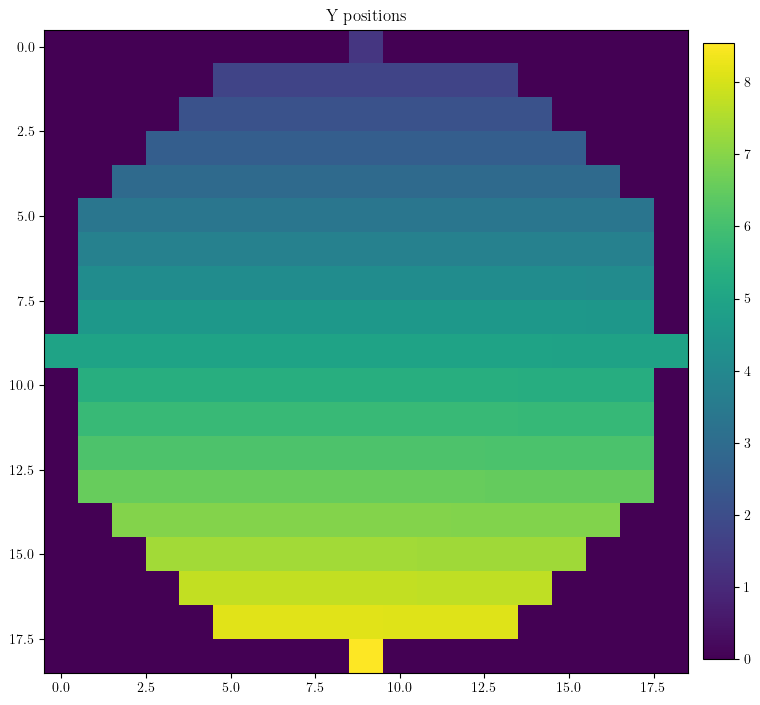

In [69]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_R_Y_hpref)
cbar = plt.colorbar(im, shrink=0.8, pad=0.02)
plt.title("Y positions")

##  <b><center> Results </center> </b>

### <center> <b> Astigmatism </b></center>

Now, we are going to iterate across the whole matrix and implement the algorithm to find the **astigmatism** in each point (those one that are meaningfull for us and the algorithm works)

In [70]:
mat_C = np.zeros((19,19))

In [71]:
# =========================================================================
#  TENSOR DE DESPLAZAMIENTO  ->  base comun de TODOS los mapas de curvatura
# =========================================================================
#  Convencion de indices de este notebook (celdas In[21]-In[29]):
#        mat[ii][jj]      ii = FILA    = coordenada y
#                         jj = COLUMNA = coordenada x
#  => la derivada respecto a x recorre jj (columnas)
#     la derivada respecto a y recorre ii (filas)
#
#  Tensor:   d_xx = (1/R) dDx/dx      d_xy = (1/R) dDx/dy
#            d_yx = (1/R) dDy/dx      d_yy = (1/R) dDy/dy
#  con Dx, Dy el desplazamiento transversal (test - referencia) en mm.
#  El campo de desplazamiento es el gradiente de una superficie, asi que
#  d_xy y d_yx deben coincidir; se promedian para simetrizar el tensor.
#
#  Este bloque reemplaza las tres copias con etiquetas a/b/c/d distintas que
#  habia en las celdas de astigmatismo, angulos, foco y curvaturas.
# =========================================================================

ro = 0.4    # espaciado de la rejilla de referencia [mm]
            # (medido en estos datos: 0.409 +- 0.014 mm)
R  = 7.78   # radio de referencia [mm]

Dx = mat_R_X - mat_R_X_hpref      # desplazamiento en x [mm]
Dy = mat_R_Y - mat_R_Y_hpref      # desplazamiento en y [mm]

#  Un nodo solo sirve si hay punto en las DOS mallas (test y referencia).
#  Si solo se comprueba mat_R_X, un hueco en la referencia mete la coordenada
#  entera (~4 mm) donde deberia haber un desplazamiento (~0.01 mm).
have = ((mat_R_X != 0) & (mat_R_Y != 0) &
        (mat_R_X_hpref != 0) & (mat_R_Y_hpref != 0))

mat_d_xx  = np.zeros((19, 19))
mat_d_yy  = np.zeros((19, 19))
mat_d_xy  = np.zeros((19, 19))
mat_valid = np.zeros((19, 19), dtype=bool)

for ii in range(1, 18):
    for jj in range(1, 18):
        # hacen falta el nodo y sus 4 vecinos para las diferencias centradas
        if not (have[ii, jj] and have[ii-1, jj] and have[ii+1, jj]
                and have[ii, jj-1] and have[ii, jj+1]):
            continue
        mat_valid[ii, jj] = True

        # dDx/dx  ->  se avanza en COLUMNAS (jj)
        mat_d_xx[ii, jj] = (Dx[ii, jj+1] - Dx[ii, jj-1]) / (2 * ro * R)

        # dDy/dy  ->  se avanza en FILAS (ii)
        #   Aqui estaba el bug: la version anterior usaba (y-1) - (y+1),
        #   es decir -dDy/dy, con el signo invertido respecto a d_xx.
        mat_d_yy[ii, jj] = (Dy[ii+1, jj] - Dy[ii-1, jj]) / (2 * ro * R)

        # termino cruzado simetrizado: 1/2 [ dDx/dy + dDy/dx ]
        mat_d_xy[ii, jj] = ((Dx[ii+1, jj] - Dx[ii-1, jj]) +
                            (Dy[ii, jj+1] - Dy[ii, jj-1])) / (4 * ro * R)

# --- Astigmatismo:  C = sqrt( (d_xx - d_yy)^2 + (2 d_xy)^2 ) ---
mat_C = np.where(mat_valid,
                 np.sqrt((mat_d_xx - mat_d_yy)**2 + (2 * mat_d_xy)**2),
                 0.0)

print("Nodos validos: %d de %d con dato." % (mat_valid.sum(), have.sum()))
print("Astigmatismo C: media = %.5f   max = %.5f   [1/mm]"
      % (mat_C[mat_valid].mean(), mat_C[mat_valid].max()))

Nodos validos: 205 de 253 con dato.
Astigmatismo C: media = 0.00853   max = 0.01833   [1/mm]


(-0.5, 18.5, 18.5, -0.5)

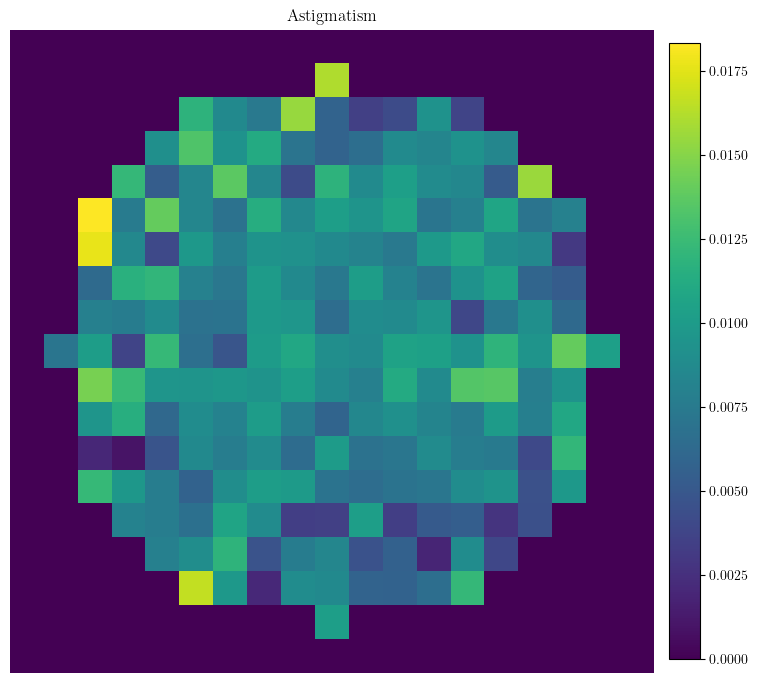

In [72]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_C, cmap="viridis") 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("Astigmatism")
plt.axis('off')

### <center> <b> Maximum and minimum curvature directions </b></center>

In [73]:
mat_Angles = np.zeros((19, 19))

In [74]:
# --- Direccion principal:  tan(2*theta) = 2 d_xy / (d_xx - d_yy) ---
#
#  Dos correcciones respecto a la version anterior:
#   1) se usa el tensor simetrizado de la celda anterior, no una combinacion
#      de vecinos distintos (antes aparecia delta_y_a - delta_y_b, que resta
#      el desplazamiento en (y+1) menos el de (x+1): dos vecinos distintos);
#   2) arctan2 en vez de arctan, para no plegar el angulo al rango +-45 grados.
#
#  theta apunta al autovalor MAYOR del tensor de desplazamiento, que es la
#  direccion de curvatura MINIMA; theta + 90 grados da la de curvatura maxima.

mat_Angles = np.where(mat_valid,
                      0.5 * np.arctan2(2 * mat_d_xy, mat_d_xx - mat_d_yy),
                      0.0)

print("Angulos principales [grados]: de %.1f a %.1f"
      % (np.degrees(mat_Angles[mat_valid]).min(),
         np.degrees(mat_Angles[mat_valid]).max()))

Angulos principales [grados]: de -88.1 a 60.4


(-0.5, 18.5, 18.5, -0.5)

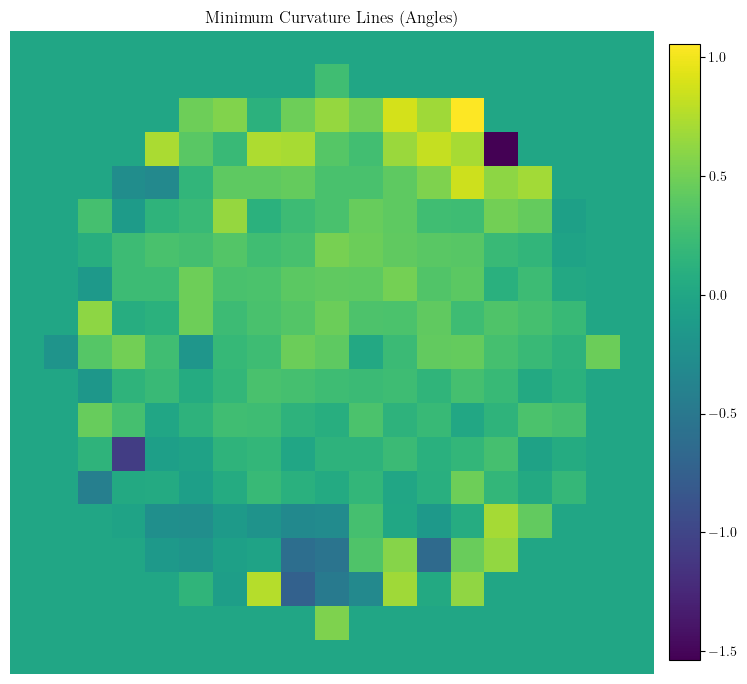

In [75]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_Angles, cmap='viridis') 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("Minimum Curvature Lines (Angles)")
plt.axis('off')

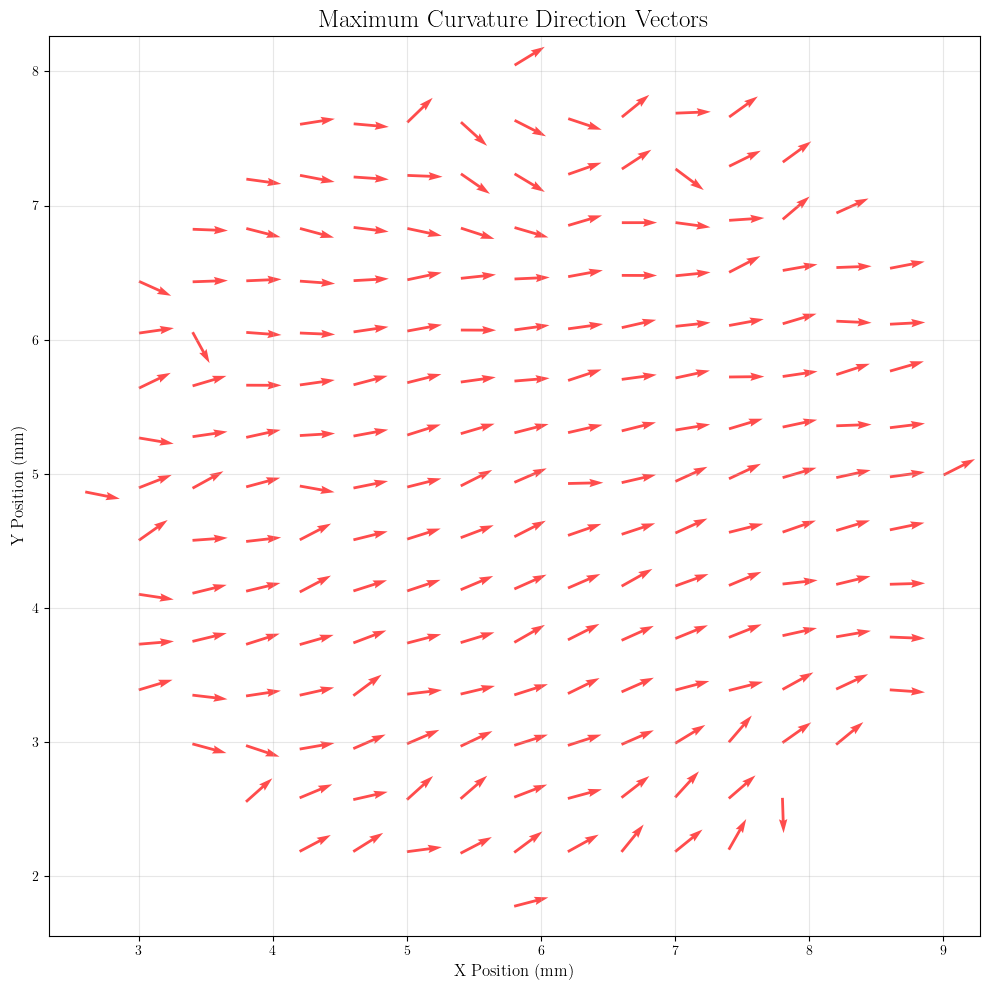

In [76]:
# --- Assume mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref are 19x19 arrays ---

# Your existing setup
ro = 0.4 #mm
R = 7.78

# Initialize arrays to store positions and vector components
x_positions = []
y_positions = []
u_components = []  # x-component of vectors
v_components = []  # y-component of vectors

# Initialize the matrix to store angles (assuming 19x19)
mat_Angles = np.zeros((19, 19))

for ii in range(1, 18):
    for jj in range(1, 18):
        x_looking = (mat_R_X[ii-1][jj] != 0 and mat_R_X[ii+1][jj] != 0 and 
                     mat_R_X[ii][jj+1] != 0 and mat_R_X[ii][jj-1] != 0)
        y_looking = (mat_R_Y[ii-1][jj] != 0 and mat_R_Y[ii+1][jj] != 0 and 
                     mat_R_Y[ii][jj+1] != 0 and mat_R_Y[ii][jj-1] != 0)
        
        if ((mat_R_X[ii][jj] != 0 and mat_R_Y[ii][jj] != 0) and x_looking and y_looking):
            center_x_coord = mat_R_X_hpref[ii][jj]
            
            # X-gradient deltas
            delta_x_a = mat_R_X[ii+1][jj] - mat_R_X_hpref[ii+1][jj]  # (y+1)
            delta_x_b = mat_R_X[ii][jj+1] - mat_R_X_hpref[ii][jj+1]  # (x+1)
            delta_x_c = mat_R_X[ii-1][jj] - mat_R_X_hpref[ii-1][jj]  # (y-1)
            delta_x_d = mat_R_X[ii][jj-1] - mat_R_X_hpref[ii][jj-1]  # (x-1)

            center_y_coord = mat_R_Y[ii][jj]
            
            # Y-gradient deltas
            delta_y_a = mat_R_Y[ii+1][jj] - mat_R_Y_hpref[ii+1][jj]  # (y+1)
            delta_y_b = mat_R_Y[ii][jj+1] - mat_R_Y_hpref[ii][jj+1]  # (x+1)
            delta_y_c = mat_R_Y[ii-1][jj] - mat_R_Y_hpref[ii-1][jj]  # (y-1) 
            delta_y_d = mat_R_Y[ii][jj-1] - mat_R_Y_hpref[ii][jj-1]  # (x-1)

            # --- *** START: CORRECTED ANGLE CALCULATION *** ---
            
            # 1. Calculate the second derivative terms
            S_xx_term = delta_x_b - delta_x_d 
            S_yy_term = delta_y_a - delta_y_c
            
            S_xy_term = delta_x_a - delta_x_c
            S_yx_term = delta_y_b - delta_y_d
            S_xy_avg_term = (S_xy_term + S_yx_term) / 2.0 

            # 2. Build the formula: tan(2*theta) = 2*S_xy / (S_xx - S_yy)
            numerator = 2.0 * S_xy_avg_term
            denominator = S_xx_term - S_yy_term

            # 3. Calculate angle using np.arctan2
            # This is the corrected line. It replaces the entire if/else block.
            # It correctly finds the angle 2*theta in the full -pi to +pi range,
            # so the final 'angle' is in the -pi/2 to +pi/2 range.
            angle = 0.5 * np.arctan2(numerator, denominator)
            
            # --- *** END: CORRECTED ANGLE CALCULATION *** ---
            
            mat_Angles[ii][jj] = angle
            
            # Store positions and vector components for plotting
            x_positions.append(center_x_coord)
            y_positions.append(center_y_coord)
            u_components.append(np.cos(angle))  # x-component of unit vector
            v_components.append(np.sin(angle))  # y-component of unit vector

# --- (Rest of your plotting code is correct) ---

# Convert to numpy arrays for plotting
x_positions = np.array(x_positions)
y_positions = np.array(y_positions)
u_components = np.array(u_components)
v_components = np.array(v_components)

# Create the vector plot
plt.figure(figsize=(10, 10))
plt.quiver(x_positions, y_positions, u_components, v_components, 
           angles='xy', scale_units='xy', scale=3.8, 
           color='red', alpha=0.7, width=0.003)

# Customize the plot
plt.xlabel('X Position (mm)', fontsize=12)
plt.ylabel('Y Position (mm)', fontsize=12)
plt.title('Maximum Curvature Direction Vectors', fontsize=18)
plt.grid(True, alpha=0.3)
plt.axis('equal') 

plt.tight_layout()
plt.show()


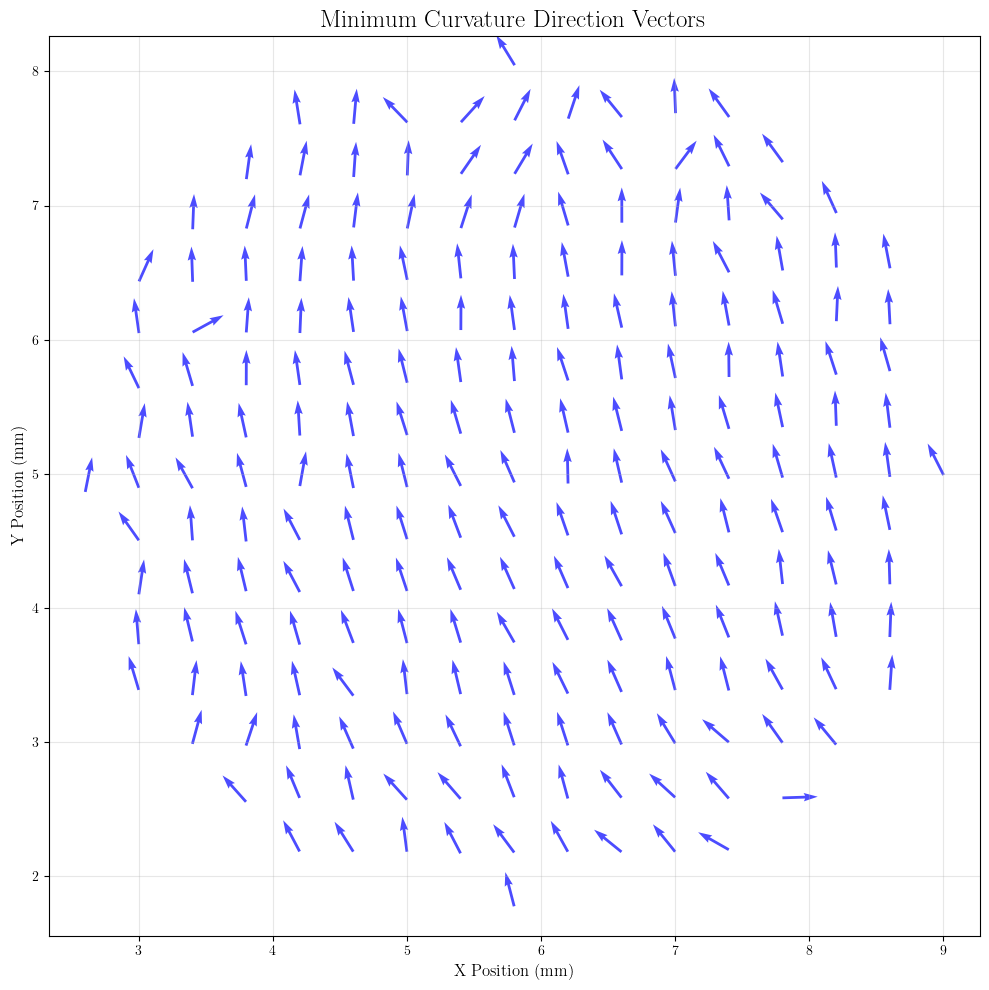

In [77]:
# --- Assume mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref are 19x19 arrays ---

# Your existing setup
ro = 0.4 #mm
R = 7.78

ncols=19

# Initialize arrays to store positions and vector components
x_positions = []
y_positions = []
# Renaming for clarity: we will use max components
u_components_max = [] 
v_components_max = [] 

# Initialize the matrix to store angles (assuming 19x19)
mat_Angles = np.zeros((ncols, ncols))

for ii in range(1, ncols-1):
    for jj in range(1, ncols-1):
        x_looking = (mat_R_X[ii-1][jj] != 0 and mat_R_X[ii+1][jj] != 0 and 
                     mat_R_X[ii][jj+1] != 0 and mat_R_X[ii][jj-1] != 0)
        y_looking = (mat_R_Y[ii-1][jj] != 0 and mat_R_Y[ii+1][jj] != 0 and 
                     mat_R_Y[ii][jj+1] != 0 and mat_R_Y[ii][jj-1] != 0)
        
        if ((mat_R_X[ii][jj] != 0 and mat_R_Y[ii][jj] != 0) and x_looking and y_looking):
            center_x_coord = mat_R_X_hpref[ii][jj]
            
            # X-gradient deltas
            delta_x_a = mat_R_X[ii+1][jj] - mat_R_X_hpref[ii+1][jj] # (y+1)
            delta_x_b = mat_R_X[ii][jj+1] - mat_R_X_hpref[ii][jj+1] # (x+1)
            delta_x_c = mat_R_X[ii-1][jj] - mat_R_X_hpref[ii-1][jj] # (y-1)
            delta_x_d = mat_R_X[ii][jj-1] - mat_R_X_hpref[ii][jj-1] # (x-1)

            center_y_coord = mat_R_Y[ii][jj]
            
            # Y-gradient deltas
            delta_y_a = mat_R_Y[ii+1][jj] - mat_R_Y_hpref[ii+1][jj] # (y+1)
            delta_y_b = mat_R_Y[ii][jj+1] - mat_R_Y_hpref[ii][jj+1] # (x+1)
            delta_y_c = mat_R_Y[ii-1][jj] - mat_R_Y_hpref[ii-1][jj] # (y-1) 
            delta_y_d = mat_R_Y[ii][jj-1] - mat_R_Y_hpref[ii][jj-1] # (x-1)

            # --- *** START: MAX CURVATURE CALCULATION *** ---
            
            # 1. Calculate the second derivative terms (S_xx, S_yy, S_xy)
            S_xx_term = delta_x_b - delta_x_d 
            S_yy_term = delta_y_a - delta_y_c
            S_xy_term = delta_x_a - delta_x_c
            S_yx_term = delta_y_b - delta_y_d
            S_xy_avg_term = (S_xy_term + S_yx_term) / 2.0 

            # 2. Build the formula: tan(2*theta)
            numerator = 2.0 * S_xy_avg_term
            denominator = S_xx_term - S_yy_term

            # 3. Calculate MINIMUM principal angle (angle_min)
            angle_min = 0.5 * np.arctan2(numerator, denominator)
            
            # 4. Calculate MAXIMUM principal angle
            # The maximum direction is orthogonal (90 degrees or pi/2) to the minimum direction.
            angle_max = angle_min + np.pi / 2.0
            
            # --- *** END: MAX CURVATURE CALCULATION *** ---
            
            mat_Angles[ii][jj] = angle_max # Store the MAX angle
            
            # Store positions and vector components for plotting
            x_positions.append(center_x_coord)
            y_positions.append(center_y_coord)
            
            # Use the MAXIMUM angle for components
            u_components_max.append(np.cos(angle_max)) 
            v_components_max.append(np.sin(angle_max)) 

# Convert to numpy arrays for plotting
x_positions = np.array(x_positions)
y_positions = np.array(y_positions)
u_components_max = np.array(u_components_max)
v_components_max = np.array(v_components_max)

# Create the vector plot
plt.figure(figsize=(10, 10))
plt.quiver(x_positions, y_positions, u_components_max, v_components_max, 
           angles='xy', scale_units='xy', scale=3.8, 
           color='blue', alpha=0.7, width=0.003)

# Customize the plot
plt.xlabel('X Position (mm)', fontsize=12)
plt.ylabel('Y Position (mm)',fontsize=12)
plt.title('Minimum Curvature Direction Vectors', fontsize=18)
plt.grid(True, alpha=0.3)
plt.axis('equal') 

plt.tight_layout()
plt.show()

### <center> <b> Focus error </b></center>

In [78]:
mat_S = np.zeros((19,19))

In [79]:
# --- Error de foco:  S = -1/2 ( d_xx + d_yy + C ) ---
#
#  Es la misma definicion que ya usaba la celda de curvaturas principales, de
#  modo que ambas quedan consistentes:
#        c_min = 1/R + S            c_max = 1/R + S + C
#  S es, por tanto, el cambio de curvatura del meridiano MENOS curvo.
#
#  La version anterior calculaba otra cosa: mezclaba d_xx con -d_yy, sumaba
#  mat_C sin el factor que le corresponde y escalaba por 1e-3 sin motivo.
#  Unidades: 1/mm.

mat_S = np.where(mat_valid, -0.5 * (mat_d_xx + mat_d_yy + mat_C), 0.0)

print("Error de foco S: media = %.5f 1/mm   (%.2f D)"
      % (mat_S[mat_valid].mean(), 337.5 * mat_S[mat_valid].mean()))

Error de foco S: media = -0.00449 1/mm   (-1.51 D)


(-0.5, 18.5, 18.5, -0.5)

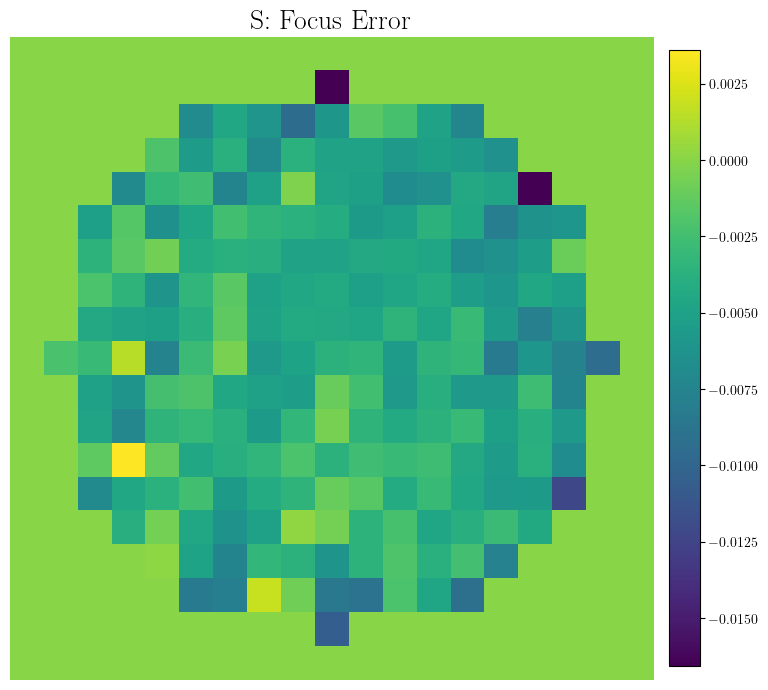

In [80]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_S) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("S: Focus Error", fontsize=20)
plt.axis('off')

### <center> <b> Maps Maximum and minimum curvatures </b></center>

In [81]:
mat_C_max = np.zeros((19,19))
mat_C_min = np.zeros((19,19))

In [82]:
# --- Curvaturas principales ---
#        c_max = 1/R + S + C     (meridiano mas curvo)
#        c_min = 1/R + S         (meridiano menos curvo)
#  S y C salen del tensor simetrizado calculado mas arriba, asi que este
#  bloque ya no repite las diferencias finitas (era la tercera copia, y la
#  que tenia el signo de d_yy invertido).
#
#  Los nodos sin dato quedan en NaN y no en 0: asi 1/mat_C_max no produce
#  infinitos que arruinen la escala de color de los mapas.

mat_C_max = np.where(mat_valid, 1/R + mat_S + mat_C, np.nan)
mat_C_min = np.where(mat_valid, 1/R + mat_S,         np.nan)

print("K_max = 1/c_max : %.3f a %.3f mm   (media %.3f)   %.2f a %.2f D"
      % (np.nanmin(1/mat_C_max), np.nanmax(1/mat_C_max), np.nanmean(1/mat_C_max),
         337.5*np.nanmin(mat_C_max), 337.5*np.nanmax(mat_C_max)))
print("K_min = 1/c_min : %.3f a %.3f mm   (media %.3f)   %.2f a %.2f D"
      % (np.nanmin(1/mat_C_min), np.nanmax(1/mat_C_min), np.nanmean(1/mat_C_min),
         337.5*np.nanmin(mat_C_min), 337.5*np.nanmax(mat_C_min)))

K_max = 1/c_max : 7.009 a 8.014 mm   (media 7.545)   42.11 a 48.15 D
K_min = 1/c_min : 7.569 a 8.932 mm   (media 8.065)   37.79 a 44.59 D


(-0.5, 18.5, 18.5, -0.5)

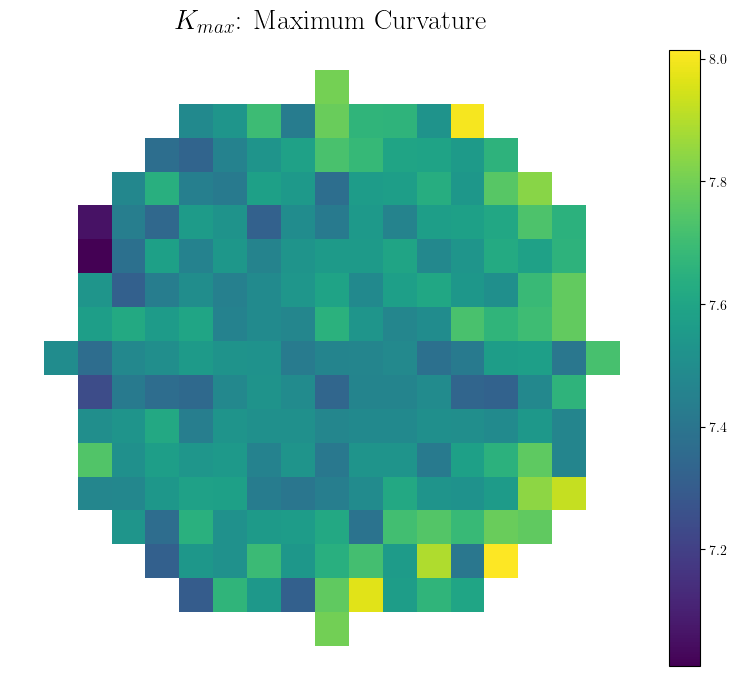

In [83]:
plt.figure(figsize=(10, 10))
im = plt.imshow(1/mat_C_max) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title(r"$K_{max}$: Maximum Curvature", fontsize=20)
plt.axis('off')

(-0.5, 18.5, 18.5, -0.5)

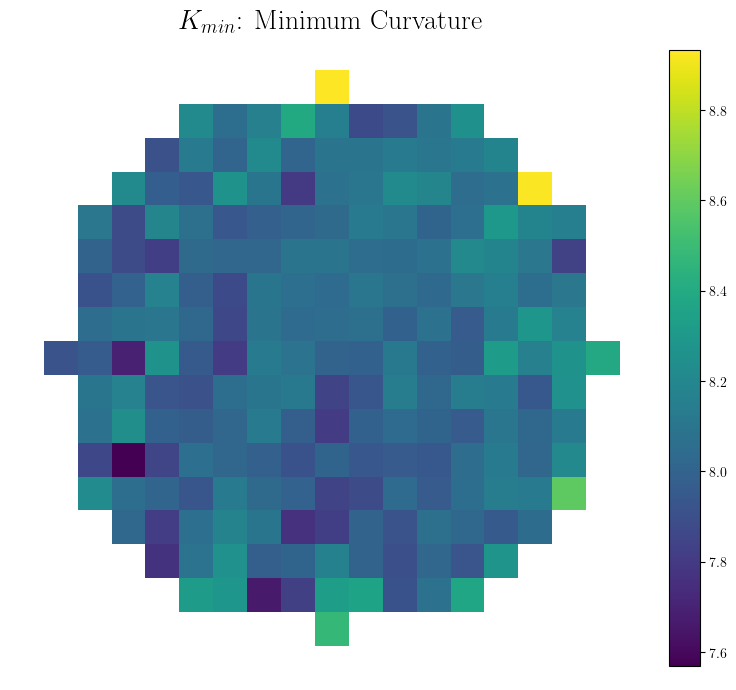

In [84]:
plt.figure(figsize=(10, 10))
im = plt.imshow(1/mat_C_min) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title(r"$K_{min}$: Minimum Curvature", fontsize=20)
plt.axis('off')

### <center> <b> Elevation </b></center>

In [85]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Disable LaTeX to avoid errors
plt.rcParams['text.usetex'] = False

def compute_elevation_discrete(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref, R, ρ=0.4):
    """
    Compute elevation for each discrete point in the 19x19 grid
    """
    N = 19
    Δh = np.zeros((N, N))
    
    # Convert to numpy arrays
    R_X = np.array(mat_R_X)
    R_Y = np.array(mat_R_Y)
    R_X_hpref = np.array(mat_R_X_hpref)
    R_Y_hpref = np.array(mat_R_Y_hpref)
    
    # Calculate displacements
    delta_x_mat = R_X - R_X_hpref
    delta_y_mat = R_Y - R_Y_hpref
    
    # Simple integration from center outward
    center_i, center_j = N//2, N//2
    Δh[center_i, center_j] = 0
    
    # For each point, compute elevation relative to neighbors
    for i in range(N):
        for j in range(N):
            if (i, j) == (center_i, center_j):
                continue
                
            # Use available neighbors for integration
            valid_neighbors = []
            
            # Check left neighbor
            if j > 0 and delta_x_mat[i, j-1] != 0 and delta_x_mat[i, j] != 0:
                Δh_left = Δh[i, j-1] + (1/R) * (
                    4 * (delta_x_mat[i, j-1] + delta_x_mat[i, j]) * ρ +
                    (1/3) * (delta_y_mat[i, j-1] + delta_y_mat[i, j]) * ρ
                )
                valid_neighbors.append(Δh_left)
            
            # Check right neighbor  
            if j < N-1 and delta_x_mat[i, j+1] != 0 and delta_x_mat[i, j] != 0:
                Δh_right = Δh[i, j+1] + (1/R) * (
                    4 * (delta_x_mat[i, j+1] + delta_x_mat[i, j]) * ρ +
                    (1/3) * (delta_y_mat[i, j+1] + delta_y_mat[i, j]) * ρ
                )
                valid_neighbors.append(Δh_right)
            
            # Check bottom neighbor
            if i > 0 and delta_x_mat[i-1, j] != 0 and delta_x_mat[i, j] != 0:
                Δh_bottom = Δh[i-1, j] + (1/R) * (
                    4 * (delta_x_mat[i-1, j] + delta_x_mat[i, j]) * ρ +
                    (1/3) * (delta_y_mat[i-1, j] + delta_y_mat[i, j]) * ρ
                )
                valid_neighbors.append(Δh_bottom)
            
            # Check top neighbor
            if i < N-1 and delta_x_mat[i+1, j] != 0 and delta_x_mat[i, j] != 0:
                Δh_top = Δh[i+1, j] + (1/R) * (
                    4 * (delta_x_mat[i+1, j] + delta_x_mat[i, j]) * ρ +
                    (1/3) * (delta_y_mat[i+1, j] + delta_y_mat[i, j]) * ρ
                )
                valid_neighbors.append(Δh_top)
            
            # Use average of available neighbors
            if valid_neighbors:
                Δh[i, j] = np.mean(valid_neighbors)
    
    return Δh

# Compute elevation
ρ = 0.4
R = 7.78
Δh = compute_elevation_discrete(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref, R, ρ)

# Get the coordinates for each point
X_points = np.array(mat_R_X_hpref)
Y_points = np.array(mat_R_Y_hpref)


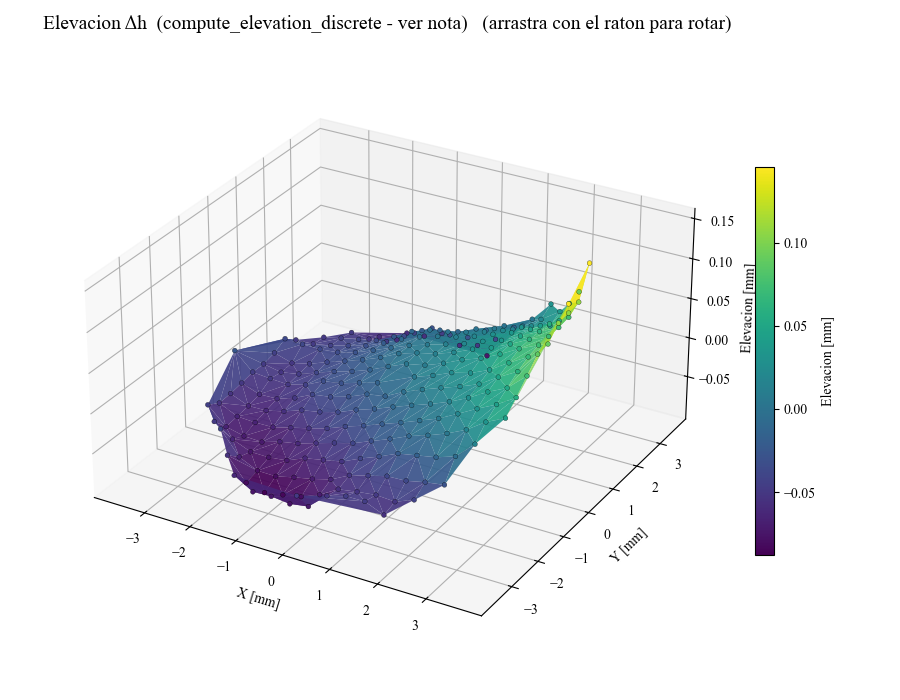

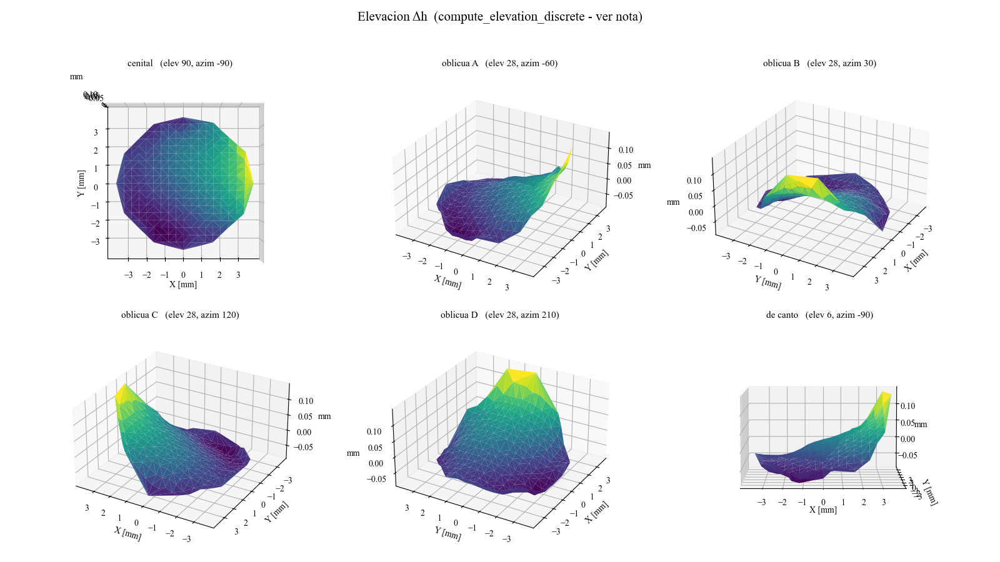

In [86]:
# =========================================================================
#  UTILIDADES DE VISUALIZACION DE ELEVACION
#  Definidas una sola vez aqui; las usan las celdas de Southwell, Campbell,
#  Malacara y la comparativa final.
# =========================================================================
import importlib
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D          # noqa: F401  (registra proj 3d)

plt.rcParams['text.usetex'] = False               # evita depender de LaTeX

# --- backend interactivo: permite rotar arrastrando con el raton ----------
#     En VS Code / Jupyter Lab hace falta ipympl.  Si no esta, se cae a
#     'inline' y quedan solo las vistas fijas.
try:
    _ip = get_ipython()
except NameError:
    _ip = None

INTERACTIVO = False
if _ip is not None:
    if importlib.util.find_spec("ipympl") is not None:
        _ip.run_line_magic('matplotlib', 'widget')
        INTERACTIVO = True
    else:
        _ip.run_line_magic('matplotlib', 'inline')
        print("ipympl no esta instalado: las figuras no se podran rotar con el raton.")
        print("Para activarlo:  pip install ipympl   y reejecutar el notebook.")


def ver_elevacion(Z, mascara, X_pts, Y_pts, titulo, micras=False, panel=False):
    """Dibuja un mapa de elevacion en 3D.

    Z        : matriz 19x19 de elevacion
    mascara  : booleana, que nodos dibujar
    X_pts,
    Y_pts    : coordenadas fisicas de cada nodo [mm] (p.ej. mat_R_*_hpref)
    micras   : True -> el eje z se muestra en micras en vez de mm
    panel    : True -> anade un panel con seis puntos de vista fijos
    """
    m = np.asarray(mascara, dtype=bool)
    x = np.asarray(X_pts, dtype=float)[m]
    y = np.asarray(Y_pts, dtype=float)[m]
    z = np.asarray(Z,     dtype=float)[m]
    x = x - x.mean()                       # centrar en la apertura
    y = y - y.mean()
    if micras:
        z = z * 1000.0
    unidad = 'um' if micras else 'mm'

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_trisurf(x, y, z, cmap='viridis', linewidth=0,
                    antialiased=True, alpha=0.92)
    sc = ax.scatter(x, y, z, c=z, cmap='viridis', s=12,
                    edgecolors='black', linewidth=0.2, depthshade=False)
    ax.set_xlabel('X [mm]'); ax.set_ylabel('Y [mm]')
    ax.set_zlabel('Elevacion [%s]' % unidad)
    ax.set_title(titulo + ('   (arrastra con el raton para rotar)'
                           if INTERACTIVO else ''), fontsize=14)
    ax.view_init(elev=28, azim=-60)
    ax.set_box_aspect([1, 1, 0.55])
    fig.colorbar(sc, ax=ax, shrink=0.6, aspect=20,
                 label='Elevacion [%s]' % unidad)
    plt.tight_layout()
    plt.show()

    if not panel:
        return
    vistas = [(90, -90, 'cenital'),   (28, -60, 'oblicua A'), (28,  30, 'oblicua B'),
              (28, 120, 'oblicua C'), (28, 210, 'oblicua D'), (6, -90, 'de canto')]
    fig2 = plt.figure(figsize=(16, 9))
    for k, (el, az, etq) in enumerate(vistas, 1):
        a = fig2.add_subplot(2, 3, k, projection='3d')
        a.plot_trisurf(x, y, z, cmap='viridis', linewidth=0, antialiased=True)
        a.view_init(elev=el, azim=az)
        a.set_box_aspect([1, 1, 0.55])
        a.set_title('%s   (elev %d, azim %d)' % (etq, el, az), fontsize=11)
        a.set_xlabel('X [mm]'); a.set_ylabel('Y [mm]'); a.set_zlabel(unidad)
    fig2.suptitle(titulo, fontsize=15)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


def mascara_interior(mascara):
    """Nodos con los 4 vecinos dentro de la apertura.

    Los nodos del anillo exterior solo tienen 2 vecinos, asi que su elevacion
    se apoya en muy pocas ecuaciones y son con diferencia los mas ruidosos:
    en estos datos llegan a -44 um frente a los ~12 um del rasgo real.  Si se
    dejan dentro, ellos solos fijan la escala de color y aplastan todo lo demas.
    """
    m = np.asarray(mascara, dtype=bool)
    nr_p, nc_p = m.shape
    out = np.zeros_like(m)
    for i in range(1, nr_p - 1):
        for j in range(1, nc_p - 1):
            if m[i, j] and m[i-1, j] and m[i+1, j] and m[i, j-1] and m[i, j+1]:
                out[i, j] = True
    return out


def quitar_mejor_ajuste(Z, mascara, X_pts, Y_pts, modelo='esfera'):
    """Resta la superficie de mejor ajuste y devuelve el residuo en MICRAS.

    modelo='esfera' :  z = a(x^2+y^2) + d*x + e*y + f
        Esfera + inclinacion + piston.  Es la convencion clinica (Pentacam,
        Orbscan): el astigmatismo NO se resta porque en un queratocono es
        irregular y forma parte de la patologia.  Deja el doble de señal.
    modelo='toro'   :  añade b(x^2-y^2) + c*xy
        Resta tambien el astigmatismo regular.  Util para aislar los ordenes
        altos (coma, trefoil), pero se lleva por delante parte del defecto.

    La inclinacion se resta siempre: en estos datos vale 85 um rms y es
    descentramiento lateral entre la captura de referencia y la del paciente,
    no forma corneal.
    """
    m = np.asarray(mascara, dtype=bool)
    x = np.asarray(X_pts, dtype=float)[m]; x = x - x.mean()
    y = np.asarray(Y_pts, dtype=float)[m]; y = y - y.mean()
    z = np.asarray(Z,     dtype=float)[m]
    cols = [x**2 + y**2]
    if modelo == 'toro':
        cols += [x**2 - y**2, x*y]
    cols += [x, y, np.ones_like(x)]
    A = np.column_stack(cols)
    coef, *_ = np.linalg.lstsq(A, z, rcond=None)
    out = np.full(np.shape(Z), np.nan)
    out[m] = (z - A @ coef) * 1000.0               # mm -> um
    return out


def escala_robusta(residuo, mascara, pct=98):
    """Limite simetrico de color calculado SIN el anillo exterior."""
    interior = mascara_interior(mascara)
    v = residuo[interior & np.isfinite(residuo)]
    if v.size == 0:
        v = residuo[np.isfinite(residuo)]
    return float(np.percentile(np.abs(v), pct))


def zernike(n, m, rho, theta):
    """Polinomio de Zernike Z(n,m) con normalizacion de Noll (rms unitario)."""
    import math
    Rad = np.zeros_like(rho); am = abs(m)
    for k in range((n - am)//2 + 1):
        Rad += ((-1)**k * math.factorial(n - k) /
                (math.factorial(k) * math.factorial((n + am)//2 - k) *
                 math.factorial((n - am)//2 - k))) * rho**(n - 2*k)
    norm = np.sqrt((2*(n + 1)) / (1 + (m == 0)))
    return norm * Rad * (np.cos(am*theta) if m >= 0 else np.sin(am*theta))


def descomponer_zernike(Z, mascara, X_pts, Y_pts, n_max=6):
    """Ajusta Zernike hasta orden n_max. Devuelve (modos, coeficientes [um], residuo [um])."""
    m = np.asarray(mascara, dtype=bool)
    x = np.asarray(X_pts, float)[m]; x = x - x.mean()
    y = np.asarray(Y_pts, float)[m]; y = y - y.mean()
    z = np.asarray(Z, float)[m] * 1000.0            # um
    r = np.hypot(x, y); rho = r / r.max(); th = np.arctan2(y, x)
    modos = [(n, mm) for n in range(n_max + 1) for mm in range(-n, n + 1, 2)]
    A = np.column_stack([zernike(n, mm, rho, th) for n, mm in modos])
    coef, *_ = np.linalg.lstsq(A, z, rcond=None)
    return modos, coef, z - A @ coef


def apice_cono(residuo, mascara):
    """Devuelve (i, j) del apice del defecto, o None si no se puede determinar.

    Busca el maximo de un promedio local 3x3 sobre los nodos interiores.  El
    rasgo mide ~2 mm, o sea varios nodos: buscar el maximo nodo a nodo
    devolveria cualquier punto ruidoso del anillo exterior.
    """
    interior = mascara_interior(mascara)
    suave = np.full_like(residuo, np.nan)
    nr_p, nc_p = residuo.shape
    for i in range(1, nr_p - 1):
        for j in range(1, nc_p - 1):
            if not interior[i, j]:
                continue
            bloque = residuo[i-1:i+2, j-1:j+2]
            if np.isfinite(bloque).sum() >= 6:
                suave[i, j] = np.nanmean(bloque)
    if not np.isfinite(suave).any():
        return None
    return np.unravel_index(np.nanargmax(suave), suave.shape)


def ver_cono(Z, mascara, X_pts, Y_pts, titulo, panel=False, modelo='toro'):
    """Quita el mejor ajuste y dibuja el residuo en 3D. Devuelve el residuo [um].

    Por defecto modelo='toro': resta tambien el astigmatismo regular, que en
    estos datos (7.5 y 4.7 um) es MAYOR que la coma (5.8 um) y forma una silla
    de montar que tapa el cono.  Con modelo='esfera' se obtiene el mapa de
    elevacion en convencion clinica, donde el astigmatismo sigue dentro.
    """
    m = np.asarray(mascara, dtype=bool)
    res = quitar_mejor_ajuste(Z, m, X_pts, Y_pts, modelo=modelo)
    ap = apice_cono(res, m)
    interior = mascara_interior(m)
    print("%-42s [%s]  rms %5.1f um   pico-valle %5.1f um   (sin borde: rms %4.1f, p-v %4.1f)"
          % (titulo, modelo, np.nanstd(res), np.nanmax(res) - np.nanmin(res),
             np.nanstd(res[interior]), np.ptp(res[interior])))
    if ap is not None:
        i_ap, j_ap = ap
        Xc = np.asarray(X_pts, float); Yc = np.asarray(Y_pts, float)
        xa = Xc[i_ap, j_ap] - Xc[m].mean()
        ya = Yc[i_ap, j_ap] - Yc[m].mean()
        print("%-42s apice: %+5.1f um en x=%+.2f y=%+.2f mm  (descentrado %.2f mm)"
              % ("", res[i_ap, j_ap], xa, ya, np.hypot(xa, ya)))
    ver_elevacion(np.nan_to_num(res) / 1000.0, m, X_pts, Y_pts,
                  titulo, micras=True, panel=panel)
    return res


# =========================================================================
#  OJO con la superficie que se dibuja aqui.
#  Delta_h viene de compute_elevation_discrete (celda anterior), que NO es una
#  integracion valida: hace un solo barrido en orden raster promediando
#  vecinos que todavia valen cero, y sus coeficientes (4 y 1/3) no son los de
#  ninguna regla de integracion -el trapecio lleva 1/2-.  Comparado con los
#  tres metodos zonales da correlacion -0.09, y su rasgo mas llamativo es un
#  pico de ~200 um clavado justo en el centro de la matriz, que es un
#  artefacto de fijar Delta_h[centro]=0, no el cono del paciente.
#  Se deja dibujado para poder compararlo con los mapas buenos de mas abajo.
# =========================================================================
ver_elevacion(Δh, Δh != 0, X_points, Y_points,
              'Elevacion Δh  (compute_elevation_discrete - ver nota)', panel=True)

#  x_vals / y_vals / z_vals: los consume el panel resumen de mas abajo.
#  Reproducen lo que construia la version anterior de esta celda: los nodos
#  con dato de Delta_h, con sus coordenadas fisicas.
_m = (Δh != 0)
x_vals = np.asarray(X_points)[_m]
y_vals = np.asarray(Y_points)[_m]
z_vals = np.asarray(Δh)[_m]

### <center> <b> Summarize </b></center>

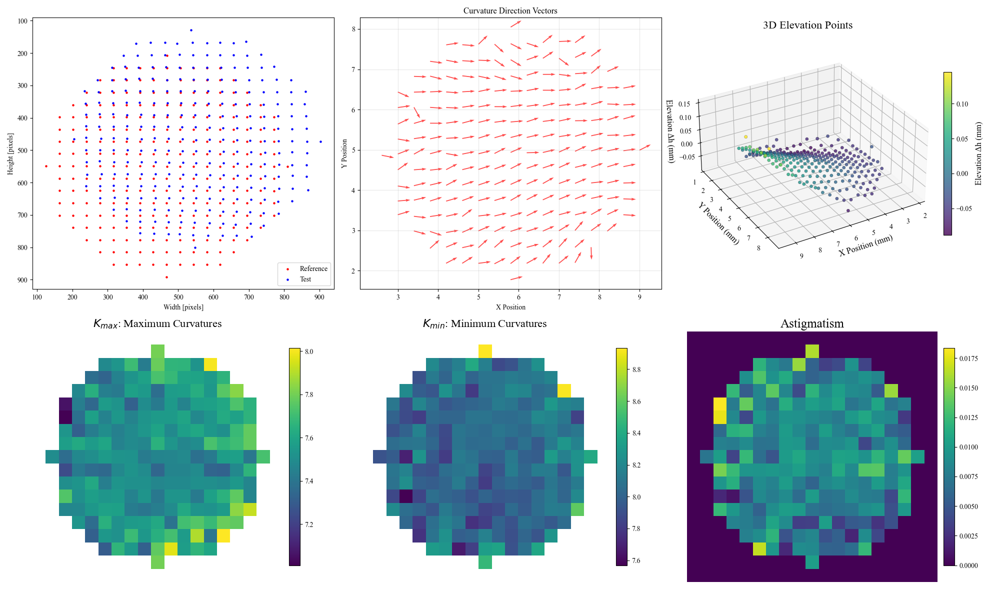

In [87]:
fig = plt.figure(figsize=(20, 12))

# === (1,1) Scatter Comparison ===
ax1 = fig.add_subplot(2, 3, 1)
ax1.scatter(y1, x1, c="red", s=5, label="Reference")
ax1.scatter(x2, y2, c="blue", s=5, label="Test")
ax1.set_xlabel('Width [pixels]')
ax1.set_ylabel('Height [pixels]')
ax1.legend(fontsize=10, loc="lower right")
ax1.invert_yaxis()

# === (1,2) Quiver (Vector Field) ===
ax2 = fig.add_subplot(2, 3, 2)
ax2.quiver(x_positions, y_positions, u_components, v_components,
           angles='xy', scale_units='xy', scale=3.2,
           color='red', alpha=0.7, width=0.003)
ax2.set_xlabel('X Position')
ax2.set_ylabel('Y Position')
ax2.set_title('Curvature Direction Vectors')
ax2.grid(True, alpha=0.3)
ax2.axis('equal')

# === (1,3) 3D Scatter ===
ax3 = fig.add_subplot(2, 3, 3, projection='3d')
scatter = ax3.scatter(x_vals, y_vals, z_vals,
                      c=z_vals, cmap='viridis', s=20,
                      alpha=0.8, edgecolors='black', linewidth=0.2)
ax3.set_title('3D Elevation Points', fontsize=16)
ax3.set_xlabel('X Position (mm)', fontsize=12)
ax3.set_ylabel('Y Position (mm)', fontsize=12)
ax3.set_zlabel('Elevation Δh (mm)', fontsize=12)
ax3.grid(True, alpha=0.3)
ax3.view_init(elev=30, azim=60)
ax3.set_box_aspect([1, 1, 0.5])

# Colorbar for 3D scatter
cbar3 = fig.colorbar(scatter, ax=ax3, shrink=0.6, aspect=20)
cbar3.set_label('Elevation Δh (mm)', fontsize=12)

# === (2,1) Kmax ===
ax4 = fig.add_subplot(2, 3, 4)
im4 = ax4.imshow(1 / mat_C_max)
cbar4 = fig.colorbar(im4, ax=ax4, shrink=0.8, pad=0.02)
ax4.set_title(r"$K_{max}$: Maximum Curvatures", fontsize=16)
ax4.axis('off')

# === (2,2) Kmin ===
ax5 = fig.add_subplot(2, 3, 5)
im5 = ax5.imshow(1 / mat_C_min)
cbar5 = fig.colorbar(im5, ax=ax5, shrink=0.8, pad=0.02)
ax5.set_title(r"$K_{min}$: Minimum Curvatures", fontsize=16)
ax5.axis('off')

# === (2,3) Astigmatism ===
ax6 = fig.add_subplot(2, 3, 6)
im6 = ax6.imshow(mat_C, cmap="viridis")
cbar6 = fig.colorbar(im6, ax=ax6, shrink=0.8, pad=0.02)
ax6.set_title("Astigmatism", fontsize=18)
ax6.axis('off')

# Adjust layout
plt.tight_layout()
plt.show()

## <center> <b> Campbell </b></center>

### <center> <b> Elevation Map </b></center>

In [88]:
nr, nc = 19,19
R = 7.78   # radio de referencia [mm]: convierte desplazamiento -> pendiente
p = 0.4 #mm
SbarX = np.zeros((nr,nc))
SbarY = np.zeros((nr,nc))
valid = np.zeros((19, 19))
Cx = np.zeros((nr,nc))

In [89]:
for ii in range(1,18): #This limits were stablished in order to avoid violating the range in which the matrix is defined
    for jj in range(1,18):
        x_looking = mat_R_X[ii][jj] != 0 and mat_R_X[ii+1][jj]!=0 and mat_R_X[ii][jj+1]!=0 and mat_R_X[ii+1][jj+1]!=0
        y_looking = mat_R_Y[ii][jj] != 0 and mat_R_Y[ii+1][jj]!=0 and mat_R_Y[ii][jj+1]!=0 and mat_R_Y[ii+1][jj+1]!=0
        if ((mat_R_X[ii][jj]!=0 and mat_R_Y[ii][jj]!= 0) and x_looking and y_looking):

            valid[ii][jj] = 1

            center_x_coord = mat_R_X_hpref[ii][jj]
            delta_x_a = mat_R_X[ii][jj+1] - mat_R_X_hpref[ii][jj+1]
            delta_x_b = mat_R_X[ii+1][jj] - mat_R_X_hpref[ii+1][jj]
            delta_x_c = mat_R_X[ii][jj-1] - mat_R_X_hpref[ii][jj-1]
            delta_x_d = mat_R_X[ii-1][jj] - mat_R_X_hpref[ii-1][jj]

            center_y_coord = mat_R_Y[ii][jj]
            delta_y_a = mat_R_Y[ii][jj+1] - mat_R_Y_hpref[ii][jj+1]
            delta_y_b = mat_R_Y[ii-1][jj] - mat_R_Y_hpref[ii-1][jj]
            delta_y_c = mat_R_Y[ii][jj-1] - mat_R_Y_hpref[ii][jj-1]
            delta_y_d = mat_R_Y[ii+1][jj] - mat_R_Y_hpref[ii+1][jj]

            #  los delta_* estan en mm; /R los convierte en pendientes
            SbarX[ii][jj] = 0.25 * (delta_x_a + delta_x_b + delta_x_c + delta_x_d) / R
            SbarY[ii][jj] = 0.25 * (delta_y_a + delta_y_b + delta_y_c + delta_y_d) / R

            Cx[ii][jj] = (1/4*p)*((-delta_x_a - delta_x_b + delta_x_d + delta_x_c ) + ( -1*delta_y_a + delta_y_b + delta_y_d - delta_y_c)) / R
            

In [90]:
Z = np.zeros((nr,nc))
f = np.zeros((nr,nc)) #This track the number of points that each point is computed

#Center
nrc = round(nr/2)
ncc = round(nr/2)

f[nrc,ncc] = 1 #Center point is filled

# Right upper cuadrant

for r in range(nrc, nr - 1):
    for c in range(ncc, nc - 1):
        if valid[r, c] == 1:
            z_ref = Z[r, c]
            s_x = SbarX[r, c]
            s_y = SbarY[r, c]
            c_x_term = (p**2 * Cx[r, c]) / 2.0

            # Calculate elevations for the other 3 corners. Eq ( 19-21 )
            z_new_1 = z_ref + (p * s_x) - c_x_term         # Z(r, c+1)
            z_new_2 = z_ref + (p * s_y) - c_x_term         # Z(r+1, c)
            z_new_3 = z_ref + p * (s_x + s_y)             # Z(r+1, c+1)

            # Update surface Z with running average (Eq. 22) [cite: 282]
            Z[r, c+1] = (f[r, c+1] * Z[r, c+1] + z_new_1) / (f[r, c+1] + 1.0)
            Z[r+1, c] = (f[r+1, c] * Z[r+1, c] + z_new_2) / (f[r+1, c] + 1.0)
            Z[r+1,c+1] = (f[r+1,c+1] * Z[r+1,c+1] + z_new_3) / (f[r+1,c+1] + 1.0)

            # Increment counters
            f[r, c+1] += 1
            f[r+1, c] += 1
            f[r+1, c+1] += 1

# Left upper quadrant

for r in range(nrc, nr - 1):
    for c in range(ncc, 0, -1): # Iterate c from ncc down to 1
        if valid[r, c-1] == 1:
            z_ref = Z[r, c] # Reference corner is (r, c)
            s_x = SbarX[r, c-1]
            s_y = SbarY[r, c-1]
            c_x_term = (p**2 * Cx[r, c-1]) / 2.0

            # Calculate elevations
            z_new_1 = z_ref - (p * s_x) + c_x_term         # Z(r, c-1)
            z_new_2 = z_ref + (p * s_y) + c_x_term         # Z(r+1, c)
            z_new_3 = z_ref - p * (s_x - s_y)             # Z(r+1, c-1)

            # Update surface Z with running average
            Z[r, c-1]   = (f[r, c-1] * Z[r, c-1] + z_new_1) / (f[r, c-1] + 1.0)
            Z[r+1, c]   = (f[r+1, c] * Z[r+1, c] + z_new_2) / (f[r+1, c] + 1.0)
            Z[r+1, c-1] = (f[r+1,c-1] * Z[r+1,c-1] + z_new_3) / (f[r+1,c-1] + 1.0)

            # Increment counters
            f[r, c-1] += 1
            f[r+1, c] += 1
            f[r+1, c-1] += 1

# Left lower quadrant
for r in range(nrc, 0, -1): # Iterate r from nrc down to 1
    for c in range(ncc, 0, -1): # Iterate c from ncc down to 1
        if valid[r-1, c-1] == 1:
            z_ref = Z[r, c] # Reference corner is (r, c)
            s_x = SbarX[r-1, c-1]
            s_y = SbarY[r-1, c-1]
            c_x_term = (p**2 * Cx[r-1, c-1]) / 2.0

            # Calculate elevations
            z_new_1 = z_ref - (p * s_x) - c_x_term         # Z(r, c-1)
            z_new_2 = z_ref - (p * s_y) - c_x_term         # Z(r-1, c)
            z_new_3 = z_ref - p * (s_x + s_y)             # Z(r-1, c-1)

            # Update surface Z with running average
            Z[r, c-1]   = (f[r, c-1] * Z[r, c-1] + z_new_1) / (f[r, c-1] + 1.0)
            Z[r-1, c]   = (f[r-1, c] * Z[r-1, c] + z_new_2) / (f[r-1, c] + 1.0)
            Z[r-1, c-1] = (f[r-1,c-1] * Z[r-1,c-1] + z_new_3) / (f[r-1,c-1] + 1.0)

            # Increment counters
            f[r, c-1] += 1
            f[r-1, c] += 1
            f[r-1, c-1] += 1

# Right lower quadrant
for r in range(nrc, 0, -1): # Iterate r from nrc down to 1
    for c in range(ncc, nc - 1): # Iterate c from ncc to 17
        if valid[r-1, c] == 1:
            z_ref = Z[r, c] # Reference corner is (r, c)
            s_x = SbarX[r-1, c]
            s_y = SbarY[r-1, c]
            c_x_term = (p**2 * Cx[r-1, c]) / 2.0

            # Calculate elevations
            z_new_1 = z_ref + (p * s_x) + c_x_term         # Z(r, c+1)
            z_new_2 = z_ref - (p * s_y) + c_x_term         # Z(r-1, c)
            z_new_3 = z_ref + p * (s_x - s_y)             # Z(r-1, c+1)

            # Update surface Z with running average
            Z[r, c+1]   = (f[r, c+1] * Z[r, c+1] + z_new_1) / (f[r, c+1] + 1.0)
            Z[r-1, c]   = (f[r-1, c] * Z[r-1, c] + z_new_2) / (f[r-1, c] + 1.0)
            Z[r-1, c+1] = (f[r-1,c+1] * Z[r-1,c+1] + z_new_3) / (f[r-1,c+1] + 1.0)
            
            # Increment counters
            f[r, c+1] += 1
            f[r-1, c] += 1
            f[r-1, c+1] += 1


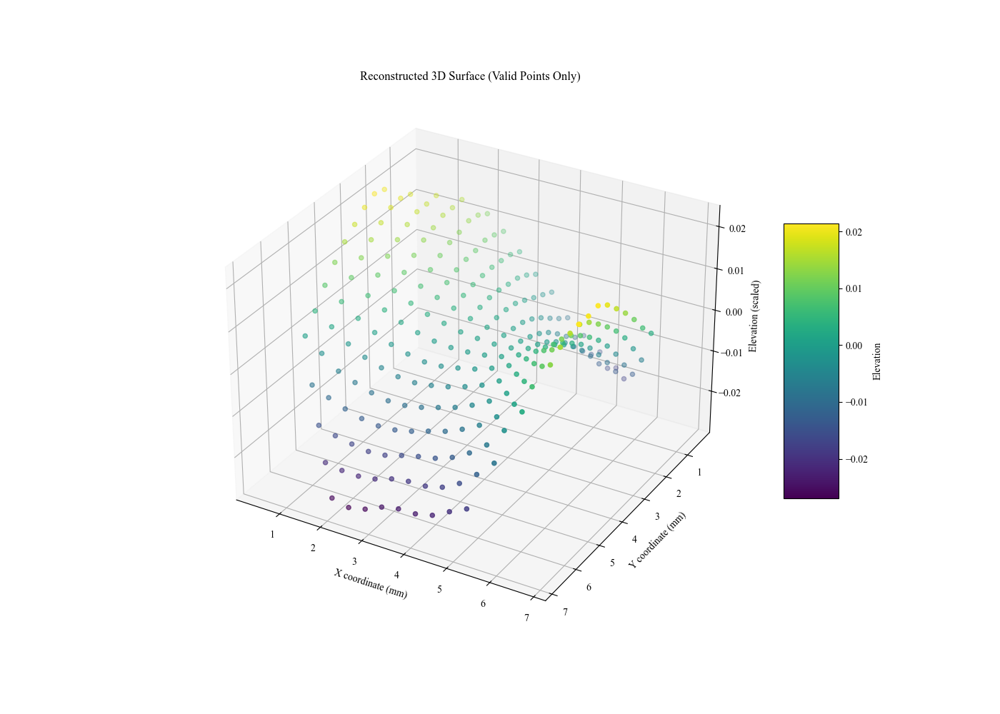

In [91]:
x_axis = np.arange(0, nc) * p
y_axis = np.arange(0, nr) * p

X, Y = np.meshgrid(x_axis, y_axis)

# --- 2. Flatten ALL Data ---
x_flat = X.flatten()
y_flat = Y.flatten()
z_flat = Z.flatten()
f_flat = f.flatten() # Flatten the 'f' (filled) matrix

mask = f_flat > 0


x_valid = x_flat[mask]
y_valid = y_flat[mask]
z_valid = z_flat[mask]

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

#  el /10 empirico ya no hace falta: con el /R la elevacion sale en mm
surf = ax.scatter(x_valid, y_valid, z_valid, c= z_valid, cmap='viridis')


ax.invert_xaxis() 

current_xlim = ax.get_xlim()
current_ylim = ax.get_ylim()

# Set the limits in reverse order
ax.set_xlim(current_xlim[1], current_xlim[0])
ax.set_ylim(current_ylim[1], current_ylim[0])

ax.set_xlabel('X coordinate (mm)')
ax.set_ylabel('Y coordinate (mm)')
ax.set_zlabel('Elevation (scaled)') # Added 'scaled'
ax.set_title('Reconstructed 3D Surface (Valid Points Only)')
fig.colorbar(surf, shrink=0.5, aspect=5, label='Elevation')

## <center> <b> Southwell method </b></center>

### <center> <b> Elevation Map </b></center>

Reconstrucción Southwell (SOR) completa. omega = 1.7295, iteraciones = 2000


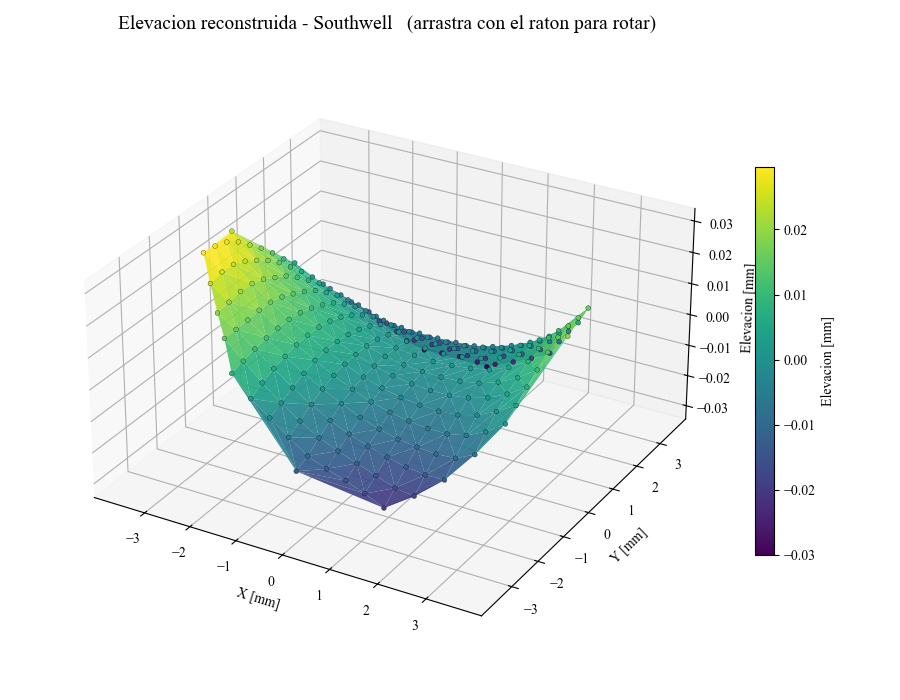

Cono sobre el mejor ajuste - Southwell     [toro]  rms   1.2 um   pico-valle   9.7 um   (sin borde: rms  0.9, p-v  4.8)
                                           apice:  +2.4 um en x=+3.20 y=-0.00 mm  (descentrado 3.20 mm)


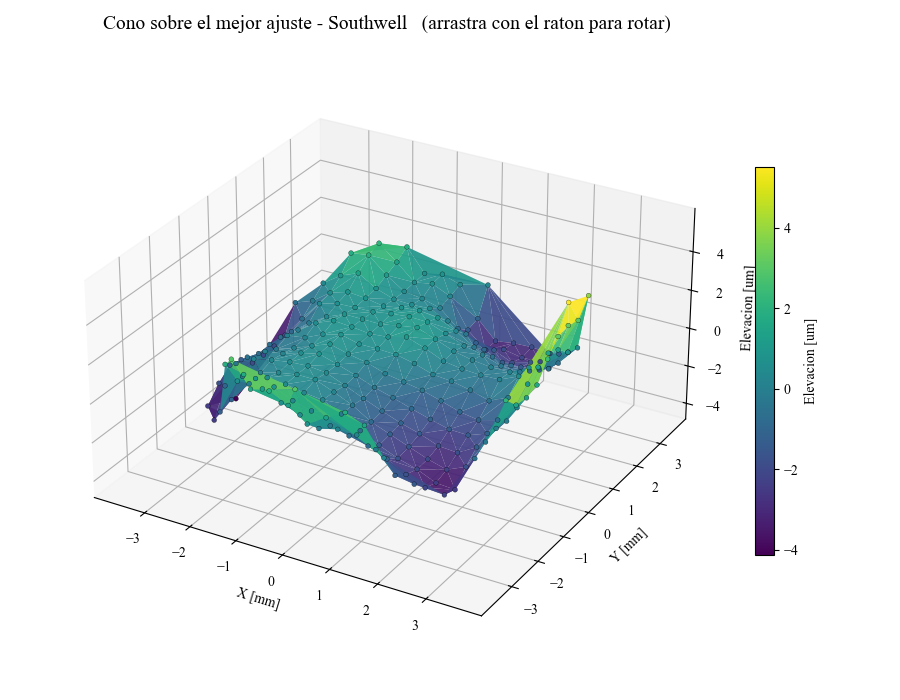

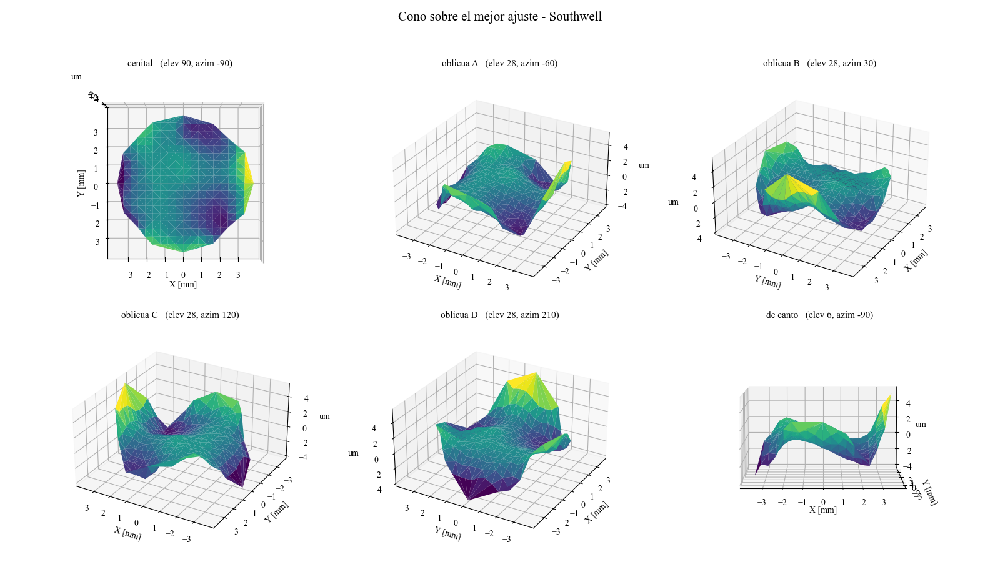

In [92]:
# ============================================================
#  MÉTODO DE SOUTHWELL  (reconstrucción zonal correcta)
# ============================================================

# --- 0. Parámetros de malla ---
nr, nc = mat_R_X.shape        # 19 x 19
p = 0.4                       # espaciado de malla [mm]  (h en el paper)

# --- 1. Campo de pendientes = desplazamiento (test - referencia) ---
R = 7.78                      # radio de referencia [mm] = distancia al plano de deteccion

#  OJO: (test - referencia) es un DESPLAZAMIENTO en mm, y la pendiente es
#  adimensional -> hay que dividir por R.  Es la misma relacion que usa la
#  celda de Malacara:  dW/dx = delta_x / R.
grad_x = (mat_R_X - mat_R_X_hpref) / R   # S^x  pendiente en x [adimensional]
grad_y = (mat_R_Y - mat_R_Y_hpref) / R   # S^y  pendiente en y [adimensional]

# --- 2. Apertura: puntos con dato válido en test Y referencia ---
mask = (mat_R_X != 0) & (mat_R_Y != 0) & (mat_R_X_hpref != 0) & (mat_R_Y_hpref != 0)
valid_points = mask.astype(float)     # (lo usan las celdas de graficación siguientes)

def present(r, c):
    """1 si (r,c) está dentro de la malla y pertenece a la apertura, 0 si no."""
    return 1 if (0 <= r < nr and 0 <= c < nc and mask[r, c]) else 0

# --- 3. Ecuaciones normales de Southwell (Ec. 25):  g·Z - Σ(vecinos) = b ---

g = np.zeros((nr, nc))
b = np.zeros((nr, nc))
for r in range(nr):
    for c in range(nc):
        if not mask[r, c]:
            continue
        g[r, c] = present(r+1, c) + present(r-1, c) + present(r, c+1) + present(r, c-1)
        acc = 0.0
        if present(r, c+1): acc += -0.5 * p * (grad_x[r, c+1] + grad_x[r, c])   # arista +x
        if present(r, c-1): acc += +0.5 * p * (grad_x[r, c-1] + grad_x[r, c])   # arista -x
        if present(r+1, c): acc += -0.5 * p * (grad_y[r+1, c] + grad_y[r, c])   # arista +y
        if present(r-1, c): acc += +0.5 * p * (grad_y[r-1, c] + grad_y[r, c])   # arista -y
        b[r, c] = acc

# --- 4. Solución iterativa por SOR (Ecs. 20-22) ---
#   Gauss-Seidel con sobre-relajación; ω óptimo del paper: ω = 2/(1+sin(π/(N+1)))
N_eff = max(nr, nc)
omega = 2.0 / (1.0 + np.sin(np.pi / (N_eff + 1)))
num_iterations = 2000     # SOR converge en ~2N barridos; 2000 es holgado

Z = np.zeros((nr, nc))
for iteration in range(num_iterations):
    for r in range(nr):
        for c in range(nc):
            if not mask[r, c] or g[r, c] == 0:
                continue
            s = 0.0
            if present(r+1, c): s += Z[r+1, c]
            if present(r-1, c): s += Z[r-1, c]
            if present(r, c+1): s += Z[r, c+1]
            if present(r, c-1): s += Z[r, c-1]
            gs = (s + b[r, c]) / g[r, c]          # paso Gauss-Seidel
            Z[r, c] += omega * (gs - Z[r, c])     # sobre-relajación
    # la solución es única salvo una constante aditiva -> se resta la media (Herrmann)
    Z[mask] -= Z[mask].mean()

print(f"Reconstrucción Southwell (SOR) completa. omega = {omega:.4f}, iteraciones = {num_iterations}")

# --- 5. Vistas 3D rotables ------------------------------------------------
#  ver_elevacion / ver_cono se definen en la celda "UTILIDADES DE
#  VISUALIZACION DE ELEVACION" (mas arriba, la del visor de Delta_h).
mask_sw = valid_points == 1

#  (a) mapa crudo: dominado por la diferencia de curvatura base (~360 um).
#      El cono NO se ve aqui por mucho que se gire la figura.
ver_elevacion(Z, mask_sw, mat_R_X_hpref, mat_R_Y_hpref,
              'Elevacion reconstruida - Southwell')

#  (b) mismo mapa quitando la superficie de mejor ajuste: aqui si aparece
#      el cono, como un abultamiento local de ~12 um descentrado del vertice.
res_southwell = ver_cono(Z, mask_sw, mat_R_X_hpref, mat_R_Y_hpref,
                         'Cono sobre el mejor ajuste - Southwell', panel=True)

(7.5600000000000005, -0.36000000000000004)

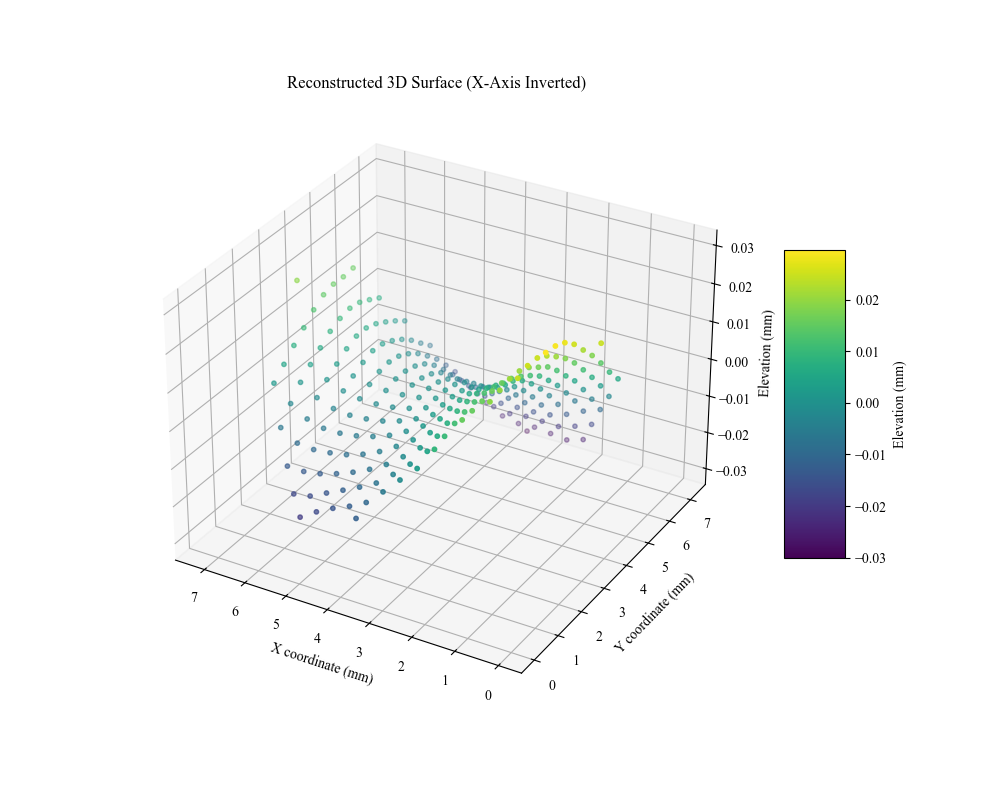

In [93]:

x_axis = np.arange(0, nc) * p
y_axis = np.arange(0, nr) * p
X, Y = np.meshgrid(x_axis, y_axis)

# --- 2. Flatten ALL Data for Masking ---
x_flat = X.flatten()
y_flat = Y.flatten()
z_flat = Z.flatten()
valid_flat = valid_points.flatten()

# --- 3. Create the Boolean Mask ---
mask = (valid_flat == 1)

# --- 4. Apply the Mask to Your Data ---
x_valid = x_flat[mask]
y_valid = y_flat[mask]
z_valid = z_flat[mask]

# --- 5. Set up the 3D Plot ---
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# --- 6. Plot the VALID Points ---
scatter_plot = ax.scatter(x_valid, y_valid, z_valid, c=z_valid, cmap='viridis', s=10)

# --- 7. Add Labels and a Color Bar ---
ax.set_xlabel('X coordinate (mm)')
ax.set_ylabel('Y coordinate (mm)')
ax.set_zlabel('Elevation (mm)')
ax.set_title('Reconstructed 3D Surface (X-Axis Inverted)')
fig.colorbar(scatter_plot, shrink=0.5, aspect=5, label='Elevation (mm)')

# --- 8. Manually Invert X-Axis (THE CHANGE IS HERE) ---
# Get the current x-axis limits
current_xlim = ax.get_xlim()
# Set the x-axis limits in reverse order
ax.set_xlim(current_xlim[1], current_xlim[0])
# The y-axis will remain in its default orientation

## <center> <b> Campbell method </b></center>

Reconstrucción Campbell (una sola pasada) completa.


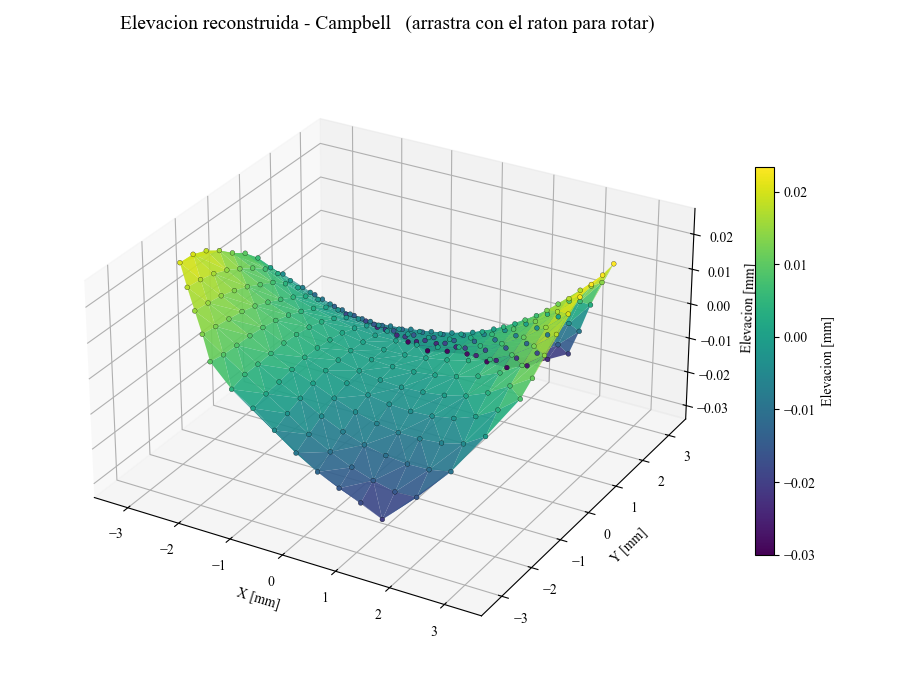

Cono sobre el mejor ajuste - Campbell      [toro]  rms   2.1 um   pico-valle  13.4 um   (sin borde: rms  1.6, p-v  9.3)
                                           apice:  +4.0 um en x=-1.20 y=-2.80 mm  (descentrado 3.05 mm)


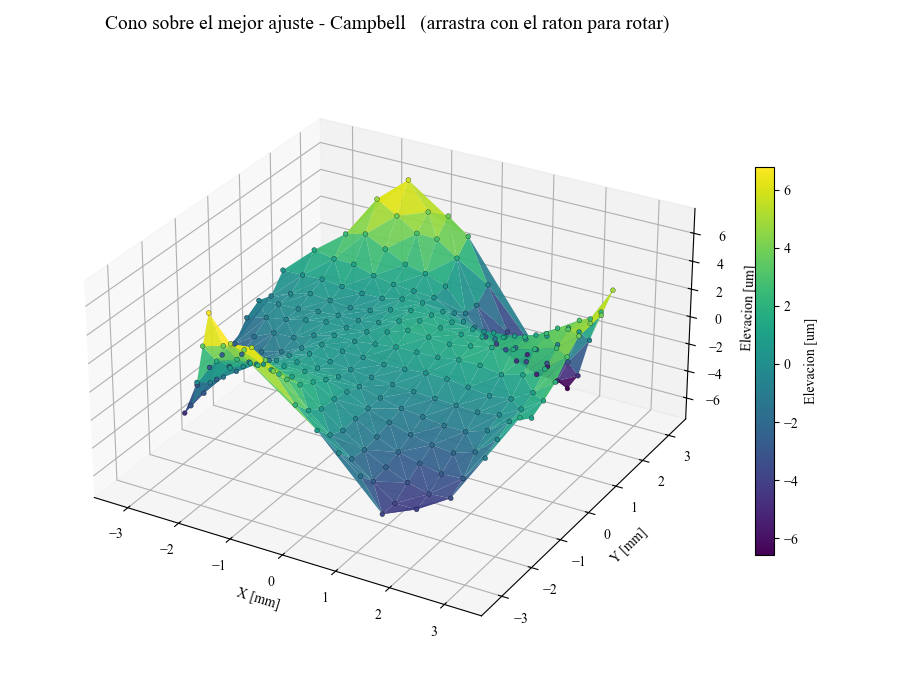

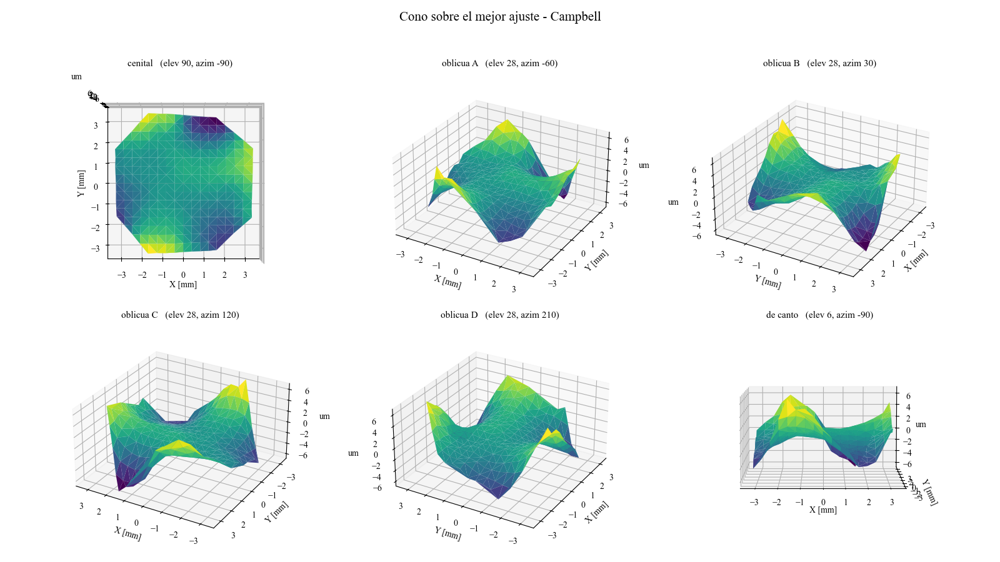

In [94]:
# ============================================================
#  MÉTODO DE CAMPBELL  (reconstrucción zonal, una sola pasada)
#  C. E. Campbell, "Zonal reconstruction of surfaces from gradient
#  fields", Opt. Eng. 61(12), 121802 (2022).
#  Port fiel del código MATLAB del Apéndice.
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# --- 0. Malla y campos de gradiente ---
nr, nc = mat_R_X.shape
p = 0.4                                   # periodo de malla [mm]
R = 7.78                                  # radio de referencia [mm]

#  (test - referencia) esta en mm; la pendiente es adimensional -> dividir por R
dZx = (mat_R_X - mat_R_X_hpref) / R       # gradiente x  (∂S/∂x) [adimensional]
dZy = (mat_R_Y - mat_R_Y_hpref) / R       # gradiente y  (∂S/∂y) [adimensional]

# --- 1. Máscara de apertura (dato válido en test y referencia) ---
mask = ((mat_R_X != 0) & (mat_R_Y != 0) &
        (mat_R_X_hpref != 0) & (mat_R_Y_hpref != 0))

# --- 2. Primer barrido: gradiente medio y curvatura cruzada oblicua C× por cuadro ---
#   Cuadro válido = sus 4 esquinas tienen dato (esquina de referencia = inf-izq (r,c)).
#   sx, sy = gradiente medio (promedio de las 4 esquinas);  C× según Ec. (9).
sx    = np.zeros((nr, nc))
sy    = np.zeros((nr, nc))
cx    = np.zeros((nr, nc))
valid = np.zeros((nr, nc))
for r in range(nr - 1):
    for c in range(nc - 1):
        if mask[r, c] and mask[r, c+1] and mask[r+1, c+1] and mask[r+1, c]:
            sx[r, c] = 0.25 * (dZx[r, c] + dZx[r, c+1] + dZx[r+1, c+1] + dZx[r+1, c])
            sy[r, c] = 0.25 * (dZy[r, c] + dZy[r, c+1] + dZy[r+1, c+1] + dZy[r+1, c])
            cx[r, c] = (-dZx[r, c] - dZx[r, c+1] + dZx[r+1, c+1] + dZx[r+1, c]
                        - dZy[r, c] + dZy[r, c+1] + dZy[r+1, c+1] - dZy[r+1, c]) / p / 4.0
            valid[r, c] = 1

# --- 3. Segundo barrido: reconstrucción por cuadrantes desde el centro ---
#   Media móvil Ec. (22): cada esquina recalculada promedia sus valores previos.
Z = np.zeros((nr, nc))
f = np.zeros((nr, nc))            # nº de veces evaluado cada punto
rc = nr // 2                      # fila central
cc = nc // 2                      # columna central
f[rc, cc] = 1                     # el centro es la referencia (elevación 0)

# Cuadrante SUPERIOR DERECHO: esquina de referencia = inferior-izquierda (Ecs. 10-12)
for r in range(rc, nr - 1):
    for c in range(cc, nc - 1):
        if valid[r, c]:
            Z[r, c+1]   = (f[r, c+1]   * Z[r, c+1]   + Z[r, c] + p*sx[r, c] - p**2*cx[r, c]/2) / (f[r, c+1]   + 1)
            Z[r+1, c+1] = (f[r+1, c+1] * Z[r+1, c+1] + Z[r, c] + p*(sx[r, c] + sy[r, c]))       / (f[r+1, c+1] + 1)
            Z[r+1, c]   = (f[r+1, c]   * Z[r+1, c]   + Z[r, c] + p*sy[r, c] - p**2*cx[r, c]/2) / (f[r+1, c]   + 1)
            f[r, c+1] += 1; f[r+1, c+1] += 1; f[r+1, c] += 1

# Cuadrante SUPERIOR IZQUIERDO: esquina de referencia = inferior-derecha (Ecs. 13-15)
for r in range(rc, nr - 1):
    for c in range(cc, 0, -1):
        if valid[r, c-1]:
            Z[r, c-1]   = (f[r, c-1]   * Z[r, c-1]   + Z[r, c] - p*sx[r, c-1] + p**2*cx[r, c-1]/2) / (f[r, c-1]   + 1)
            Z[r+1, c-1] = (f[r+1, c-1] * Z[r+1, c-1] + Z[r, c] + p*(-sx[r, c-1] + sy[r, c-1]))       / (f[r+1, c-1] + 1)
            Z[r+1, c]   = (f[r+1, c]   * Z[r+1, c]   + Z[r, c] + p*sy[r, c-1] + p**2*cx[r, c-1]/2) / (f[r+1, c]   + 1)
            f[r, c-1] += 1; f[r+1, c-1] += 1; f[r+1, c] += 1

# Cuadrante INFERIOR DERECHO: esquina de referencia = superior-izquierda (Ecs. 16-18)
for r in range(rc, 0, -1):
    for c in range(cc, nc - 1):
        if valid[r-1, c]:
            Z[r, c+1]   = (f[r, c+1]   * Z[r, c+1]   + Z[r, c] + p*sx[r-1, c] + p**2*cx[r-1, c]/2) / (f[r, c+1]   + 1)
            Z[r-1, c+1] = (f[r-1, c+1] * Z[r-1, c+1] + Z[r, c] + p*(sx[r-1, c] - sy[r-1, c]))       / (f[r-1, c+1] + 1)
            Z[r-1, c]   = (f[r-1, c]   * Z[r-1, c]   + Z[r, c] - p*sy[r-1, c] + p**2*cx[r-1, c]/2) / (f[r-1, c]   + 1)
            f[r, c+1] += 1; f[r-1, c+1] += 1; f[r-1, c] += 1

# Cuadrante INFERIOR IZQUIERDO: esquina de referencia = superior-derecha (Ecs. 19-21)
for r in range(rc, 0, -1):
    for c in range(cc, 0, -1):
        if valid[r-1, c-1]:
            Z[r, c-1]   = (f[r, c-1]   * Z[r, c-1]   + Z[r, c] - p*sx[r-1, c-1] - p**2*cx[r-1, c-1]/2) / (f[r, c-1]   + 1)
            Z[r-1, c-1] = (f[r-1, c-1] * Z[r-1, c-1] + Z[r, c] - p*(sx[r-1, c-1] + sy[r-1, c-1]))       / (f[r-1, c-1] + 1)
            Z[r-1, c]   = (f[r-1, c]   * Z[r-1, c]   + Z[r, c] - p*sy[r-1, c-1] - p**2*cx[r-1, c-1]/2) / (f[r-1, c]   + 1)
            f[r, c-1] += 1; f[r-1, c-1] += 1; f[r-1, c] += 1

Z = Z * mask                              # limitar a la apertura
valid_points = (f > 0).astype(float)      # puntos efectivamente reconstruidos

print("Reconstrucción Campbell (una sola pasada) completa.")

# --- 4. Vistas 3D rotables ------------------------------------------------
mask_cb = valid_points == 1

#  (a) mapa crudo
ver_elevacion(Z, mask_cb, mat_R_X_hpref, mat_R_Y_hpref,
              'Elevacion reconstruida - Campbell')

#  (b) quitando la superficie de mejor ajuste: el cono
res_campbell = ver_cono(Z, mask_cb, mat_R_X_hpref, mat_R_Y_hpref,
                        'Cono sobre el mejor ajuste - Campbell', panel=True)

## <center> <b> Malacara's method </b></center>

Elevation (Malacara) corregido: integración de camino completa.


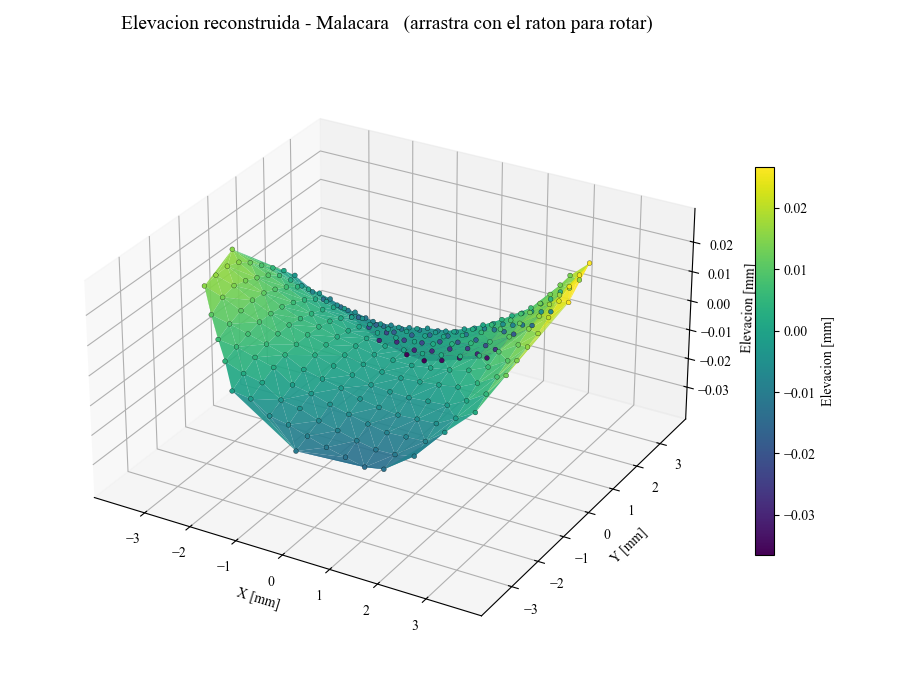

Cono sobre el mejor ajuste - Malacara      [toro]  rms   1.7 um   pico-valle  13.3 um   (sin borde: rms  1.3, p-v  7.5)
                                           apice:  +2.9 um en x=-0.00 y=-3.20 mm  (descentrado 3.20 mm)


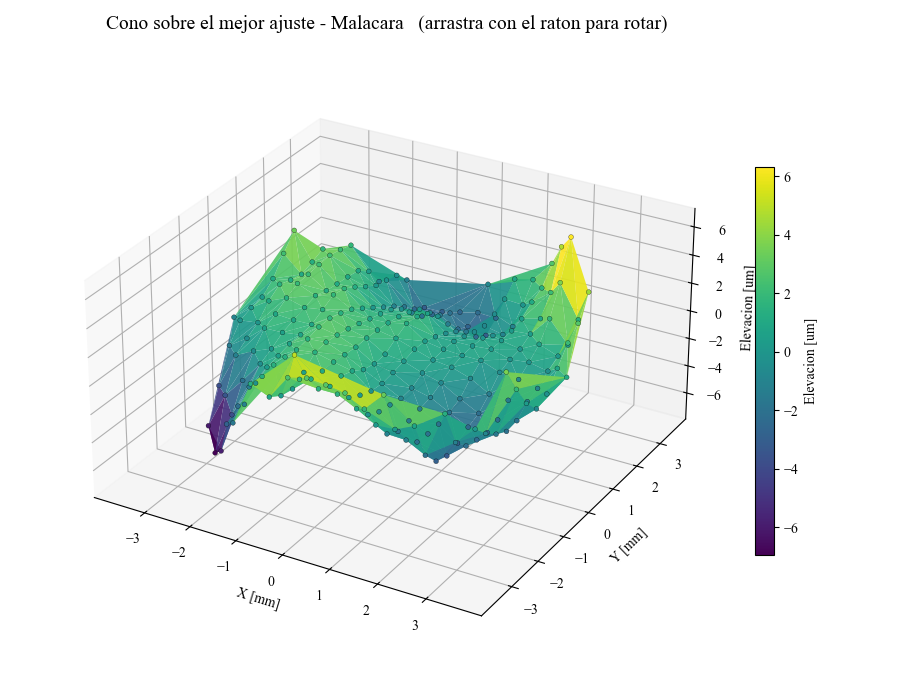

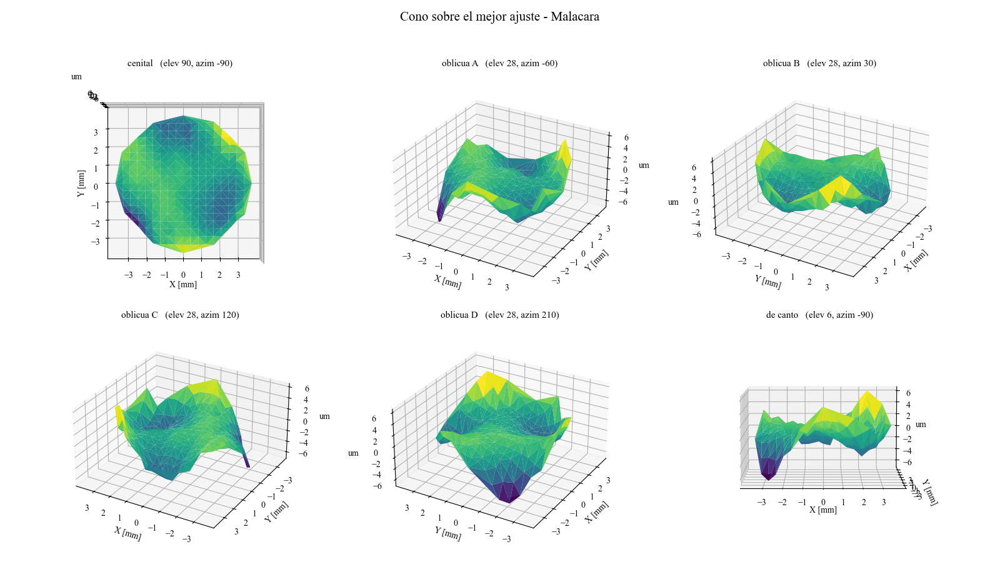

In [95]:
# ============================================================
#  ELEVATION (método de Malacara) — CORREGIDO
# ============================================================

nr, nc = mat_R_X.shape
rho = 0.4          # espaciado de malla [mm]
R   = 7.78         # radio de referencia [mm]

dX = mat_R_X - mat_R_X_hpref      # δx : pendiente x (proxy)
dY = mat_R_Y - mat_R_Y_hpref      # δy : pendiente y (proxy)

mask = ((mat_R_X != 0) & (mat_R_Y != 0) &
        (mat_R_X_hpref != 0) & (mat_R_Y_hpref != 0))

Z = np.zeros((nr, nc))
filled = np.zeros((nr, nc), dtype=bool)
ci, cj = nr // 2, nc // 2
filled[ci, cj] = bool(mask[ci, cj])      # el centro es la referencia (Z=0)

def step_x(i, ja, jb):   # incremento de W al pasar de (i,ja) a (i,jb), |ja-jb|=1
    return (1.0 / R) * rho * (dX[i, ja] + dX[i, jb]) / 2.0
def step_y(ia, ib, j):   # incremento de W al pasar de (ia,j) a (ib,j), |ia-ib|=1
    return (1.0 / R) * rho * (dY[ia, j] + dY[ib, j]) / 2.0

# 1) FILA CENTRAL: integrar en x desde el centro hacia ambos lados
for j in range(cj + 1, nc):
    if mask[ci, j] and filled[ci, j-1]:
        Z[ci, j] = Z[ci, j-1] + step_x(ci, j-1, j)
        filled[ci, j] = True
    else:
        break
for j in range(cj - 1, -1, -1):
    if mask[ci, j] and filled[ci, j+1]:
        Z[ci, j] = Z[ci, j+1] - step_x(ci, j+1, j)
        filled[ci, j] = True
    else:
        break

# 2) CADA COLUMNA: integrar en y desde la fila central hacia arriba y abajo
for j in range(nc):
    if not filled[ci, j]:
        continue
    for i in range(ci + 1, nr):
        if mask[i, j] and filled[i-1, j]:
            Z[i, j] = Z[i-1, j] + step_y(i-1, i, j)
            filled[i, j] = True
        else:
            break
    for i in range(ci - 1, -1, -1):
        if mask[i, j] and filled[i+1, j]:
            Z[i, j] = Z[i+1, j] - step_y(i+1, i, j)
            filled[i, j] = True
        else:
            break

valid_points = filled.astype(float)
print("Elevation (Malacara) corregido: integración de camino completa.")

# --- Vistas 3D rotables ---------------------------------------------------
mask_ml = filled

#  (a) mapa crudo
ver_elevacion(Z, mask_ml, mat_R_X_hpref, mat_R_Y_hpref,
              'Elevacion reconstruida - Malacara')

#  (b) quitando la superficie de mejor ajuste: el cono
res_malacara = ver_cono(Z, mask_ml, mat_R_X_hpref, mat_R_Y_hpref,
                        'Cono sobre el mejor ajuste - Malacara', panel=True)

## <center> <b> Curvatura sagital y tangencial: comparativa de los tres metodos </b></center>

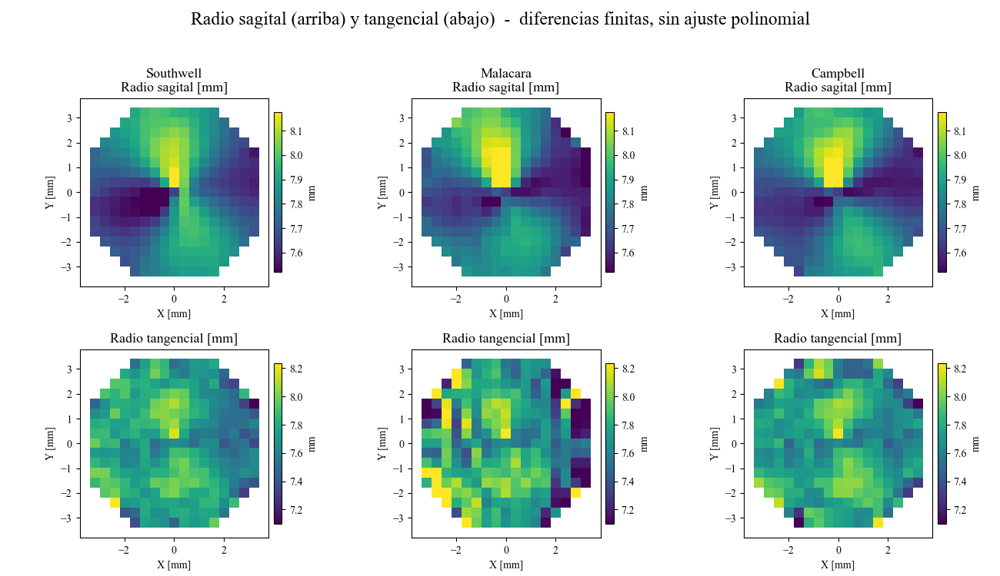

In [96]:
# =========================================================================
#  COMPARATIVA: curvatura SAGITAL y TANGENCIAL de los tres metodos
#  Southwell / Malacara / Campbell  ->  reconstruyen la elevacion
#  Curvatura por DIFERENCIAS FINITAS puras (sin ajuste polinomial)
# =========================================================================
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['text.usetex'] = False

p, R = 0.4, 7.78

# =========================================================================
#  0. CAMPO DE PENDIENTES  (ya adimensional: el /R es el fix de unidades)
# =========================================================================
def campo_pendientes(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref, R):
    Sx = (mat_R_X - mat_R_X_hpref) / R
    Sy = (mat_R_Y - mat_R_Y_hpref) / R
    M = ((mat_R_X != 0) & (mat_R_Y != 0) &
         (mat_R_X_hpref != 0) & (mat_R_Y_hpref != 0))
    return Sx, Sy, M


# =========================================================================
#  1. LAS TRES RECONSTRUCCIONES DE ELEVACION
# =========================================================================
def recon_southwell(Sx, Sy, M, p, iters=2000):
    """Southwell 1980: ecuaciones normales + SOR."""
    nr, nc = Sx.shape
    pres = lambda r, c: 1 if (0 <= r < nr and 0 <= c < nc and M[r, c]) else 0
    g = np.zeros((nr, nc)); b = np.zeros((nr, nc))
    for r in range(nr):
        for c in range(nc):
            if not M[r, c]:
                continue
            g[r, c] = pres(r+1, c) + pres(r-1, c) + pres(r, c+1) + pres(r, c-1)
            acc = 0.0
            if pres(r, c+1): acc += -0.5*p*(Sx[r, c+1] + Sx[r, c])
            if pres(r, c-1): acc += +0.5*p*(Sx[r, c-1] + Sx[r, c])
            if pres(r+1, c): acc += -0.5*p*(Sy[r+1, c] + Sy[r, c])
            if pres(r-1, c): acc += +0.5*p*(Sy[r-1, c] + Sy[r, c])
            b[r, c] = acc
    omega = 2.0 / (1.0 + np.sin(np.pi / (max(nr, nc) + 1)))
    Z = np.zeros((nr, nc))
    for _ in range(iters):
        for r in range(nr):
            for c in range(nc):
                if not M[r, c] or g[r, c] == 0:
                    continue
                s = 0.0
                if pres(r+1, c): s += Z[r+1, c]
                if pres(r-1, c): s += Z[r-1, c]
                if pres(r, c+1): s += Z[r, c+1]
                if pres(r, c-1): s += Z[r, c-1]
                Z[r, c] += omega * ((s + b[r, c]) / g[r, c] - Z[r, c])
        Z[M] -= Z[M].mean()
    return Z, M.copy()


def recon_campbell(Sx, Sy, M, p):
    """Campbell 2022: una sola pasada por cuadrantes con media movil."""
    nr, nc = Sx.shape
    sx = np.zeros((nr, nc)); sy = np.zeros((nr, nc))
    cx = np.zeros((nr, nc)); val = np.zeros((nr, nc), bool)
    for r in range(nr-1):
        for c in range(nc-1):
            if M[r, c] and M[r, c+1] and M[r+1, c+1] and M[r+1, c]:
                sx[r, c] = 0.25*(Sx[r, c] + Sx[r, c+1] + Sx[r+1, c+1] + Sx[r+1, c])
                sy[r, c] = 0.25*(Sy[r, c] + Sy[r, c+1] + Sy[r+1, c+1] + Sy[r+1, c])
                cx[r, c] = (-Sx[r, c] - Sx[r, c+1] + Sx[r+1, c+1] + Sx[r+1, c]
                            - Sy[r, c] + Sy[r, c+1] + Sy[r+1, c+1] - Sy[r+1, c]) / p / 4.0
                val[r, c] = True
    Z = np.zeros((nr, nc)); f = np.zeros((nr, nc))
    rc, cc = nr//2, nc//2
    f[rc, cc] = 1
    for r in range(rc, nr-1):                      # superior derecho
        for c in range(cc, nc-1):
            if val[r, c]:
                Z[r, c+1]   = (f[r, c+1]*Z[r, c+1]     + Z[r, c] + p*sx[r, c] - p**2*cx[r, c]/2) / (f[r, c+1]+1)
                Z[r+1, c+1] = (f[r+1, c+1]*Z[r+1, c+1] + Z[r, c] + p*(sx[r, c]+sy[r, c]))        / (f[r+1, c+1]+1)
                Z[r+1, c]   = (f[r+1, c]*Z[r+1, c]     + Z[r, c] + p*sy[r, c] - p**2*cx[r, c]/2) / (f[r+1, c]+1)
                f[r, c+1] += 1; f[r+1, c+1] += 1; f[r+1, c] += 1
    for r in range(rc, nr-1):                      # superior izquierdo
        for c in range(cc, 0, -1):
            if val[r, c-1]:
                Z[r, c-1]   = (f[r, c-1]*Z[r, c-1]     + Z[r, c] - p*sx[r, c-1] + p**2*cx[r, c-1]/2) / (f[r, c-1]+1)
                Z[r+1, c-1] = (f[r+1, c-1]*Z[r+1, c-1] + Z[r, c] + p*(-sx[r, c-1]+sy[r, c-1]))       / (f[r+1, c-1]+1)
                Z[r+1, c]   = (f[r+1, c]*Z[r+1, c]     + Z[r, c] + p*sy[r, c-1] + p**2*cx[r, c-1]/2) / (f[r+1, c]+1)
                f[r, c-1] += 1; f[r+1, c-1] += 1; f[r+1, c] += 1
    for r in range(rc, 0, -1):                     # inferior derecho
        for c in range(cc, nc-1):
            if val[r-1, c]:
                Z[r, c+1]   = (f[r, c+1]*Z[r, c+1]     + Z[r, c] + p*sx[r-1, c] + p**2*cx[r-1, c]/2) / (f[r, c+1]+1)
                Z[r-1, c+1] = (f[r-1, c+1]*Z[r-1, c+1] + Z[r, c] + p*(sx[r-1, c]-sy[r-1, c]))        / (f[r-1, c+1]+1)
                Z[r-1, c]   = (f[r-1, c]*Z[r-1, c]     + Z[r, c] - p*sy[r-1, c] + p**2*cx[r-1, c]/2) / (f[r-1, c]+1)
                f[r, c+1] += 1; f[r-1, c+1] += 1; f[r-1, c] += 1
    for r in range(rc, 0, -1):                     # inferior izquierdo
        for c in range(cc, 0, -1):
            if val[r-1, c-1]:
                Z[r, c-1]   = (f[r, c-1]*Z[r, c-1]     + Z[r, c] - p*sx[r-1, c-1] - p**2*cx[r-1, c-1]/2) / (f[r, c-1]+1)
                Z[r-1, c-1] = (f[r-1, c-1]*Z[r-1, c-1] + Z[r, c] - p*(sx[r-1, c-1]+sy[r-1, c-1]))        / (f[r-1, c-1]+1)
                Z[r-1, c]   = (f[r-1, c]*Z[r-1, c]     + Z[r, c] - p*sy[r-1, c-1] - p**2*cx[r-1, c-1]/2) / (f[r-1, c]+1)
                f[r, c-1] += 1; f[r-1, c-1] += 1; f[r-1, c] += 1
    return Z*M, (f > 0) & M


def recon_malacara(Sx, Sy, M, p):
    """Integracion de camino (trapecio) desde el centro: fila central en x,
       luego cada columna en y."""
    nr, nc = Sx.shape
    Z = np.zeros((nr, nc)); fill = np.zeros((nr, nc), bool)
    ci, cj = nr//2, nc//2
    fill[ci, cj] = bool(M[ci, cj])
    sx_step = lambda i, ja, jb: p*(Sx[i, ja] + Sx[i, jb])/2.0
    sy_step = lambda ia, ib, j: p*(Sy[ia, j] + Sy[ib, j])/2.0
    for j in range(cj+1, nc):
        if M[ci, j] and fill[ci, j-1]:
            Z[ci, j] = Z[ci, j-1] + sx_step(ci, j-1, j); fill[ci, j] = True
        else: break
    for j in range(cj-1, -1, -1):
        if M[ci, j] and fill[ci, j+1]:
            Z[ci, j] = Z[ci, j+1] - sx_step(ci, j+1, j); fill[ci, j] = True
        else: break
    for j in range(nc):
        if not fill[ci, j]:
            continue
        for i in range(ci+1, nr):
            if M[i, j] and fill[i-1, j]:
                Z[i, j] = Z[i-1, j] + sy_step(i-1, i, j); fill[i, j] = True
            else: break
        for i in range(ci-1, -1, -1):
            if M[i, j] and fill[i+1, j]:
                Z[i, j] = Z[i+1, j] - sy_step(i+1, i, j); fill[i, j] = True
            else: break
    return Z, fill


# =========================================================================
#  2. CURVATURA POR DIFERENCIAS FINITAS PURAS
# =========================================================================
def _fd(z, m, p):
    nr, nc = z.shape
    nan = lambda: np.full((nr, nc), np.nan)
    zx, zy, zxx, zyy, zxy = nan(), nan(), nan(), nan(), nan()
    ok = lambda i, j: 0 <= i < nr and 0 <= j < nc and m[i, j]
    for i in range(nr):
        for j in range(nc):
            if not m[i, j]:
                continue
            if ok(i, j-1) and ok(i, j+1):
                zx[i, j]  = (z[i, j+1] - z[i, j-1]) / (2*p)
                zxx[i, j] = (z[i, j+1] - 2*z[i, j] + z[i, j-1]) / p**2
            elif ok(i, j+1) and ok(i, j+2):
                zx[i, j]  = (-3*z[i, j] + 4*z[i, j+1] - z[i, j+2]) / (2*p)
                zxx[i, j] = (z[i, j] - 2*z[i, j+1] + z[i, j+2]) / p**2
            elif ok(i, j-1) and ok(i, j-2):
                zx[i, j]  = ( 3*z[i, j] - 4*z[i, j-1] + z[i, j-2]) / (2*p)
                zxx[i, j] = (z[i, j] - 2*z[i, j-1] + z[i, j-2]) / p**2
            if ok(i-1, j) and ok(i+1, j):
                zy[i, j]  = (z[i+1, j] - z[i-1, j]) / (2*p)
                zyy[i, j] = (z[i+1, j] - 2*z[i, j] + z[i-1, j]) / p**2
            elif ok(i+1, j) and ok(i+2, j):
                zy[i, j]  = (-3*z[i, j] + 4*z[i+1, j] - z[i+2, j]) / (2*p)
                zyy[i, j] = (z[i, j] - 2*z[i+1, j] + z[i+2, j]) / p**2
            elif ok(i-1, j) and ok(i-2, j):
                zy[i, j]  = ( 3*z[i, j] - 4*z[i-1, j] + z[i-2, j]) / (2*p)
                zyy[i, j] = (z[i, j] - 2*z[i-1, j] + z[i-2, j]) / p**2
    for i in range(nr):
        for j in range(nc):
            if not m[i, j]:
                continue
            if ok(i-1, j-1) and ok(i-1, j+1) and ok(i+1, j-1) and ok(i+1, j+1):
                zxy[i, j] = (z[i+1, j+1] - z[i+1, j-1]
                             - z[i-1, j+1] + z[i-1, j-1]) / (4*p**2)
            else:
                up = i+1 < nr and m[i+1, j] and np.isfinite(zx[i+1, j])
                dn = i-1 >= 0 and m[i-1, j] and np.isfinite(zx[i-1, j])
                if   up and dn: zxy[i, j] = (zx[i+1, j] - zx[i-1, j]) / (2*p)
                elif up:        zxy[i, j] = (zx[i+1, j] - zx[i, j]) / p
                elif dn:        zxy[i, j] = (zx[i, j] - zx[i-1, j]) / p
                else:           zxy[i, j] = 0.0
    return zx, zy, zxx, zyy, zxy


def sag_tan_fd(dh, mask, p=0.4, R_ref=7.78, center=None):
    """Curvaturas sagital (axial) y tangencial. dh = elevacion diferencial [mm].
       La esfera de referencia aporta derivadas exactas; FD solo sobre dh."""
    nr, nc = dh.shape
    ci, cj = (nr//2, nc//2) if center is None else center
    jj, ii = np.meshgrid(np.arange(nc), np.arange(nr))
    x = (jj - cj)*p; y = (ii - ci)*p
    m = mask.astype(bool)
    dx, dy, dxx, dyy, dxy = _fd(np.where(m, dh, 0.0), m, p)
    q = np.sqrt(np.maximum(R_ref**2 - x**2 - y**2, 1e-12))
    zx  = x/q                    + dx
    zy  = y/q                    + dy
    zxx = (R_ref**2 - y**2)/q**3 + dxx
    zyy = (R_ref**2 - x**2)/q**3 + dyy
    zxy = x*y/q**3               + dxy
    r  = np.sqrt(x**2 + y**2)
    th = np.arctan2(y, x); ct, st = np.cos(th), np.sin(th)
    z_r  = zx*ct + zy*st
    z_rr = zxx*ct**2 + 2*zxy*ct*st + zyy*st**2
    k_t = z_rr / (1 + z_r**2)**1.5
    with np.errstate(divide='ignore', invalid='ignore'):
        k_s = z_r / (r*np.sqrt(1 + z_r**2))
    k_s = np.where(r < 1e-9, k_t, k_s)
    return (np.where(m, 1/k_t, np.nan), np.where(m, 1/k_s, np.nan),
            (x.min()-p/2, x.max()+p/2, y.min()-p/2, y.max()+p/2))


# =========================================================================
#  3. PANEL COMPARATIVO
# =========================================================================
def comparar_metodos(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref,
                     p=0.4, R=7.78, magnitud='radio'):
    Sx, Sy, M = campo_pendientes(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref, R)
    metodos = [('Southwell', recon_southwell),
               ('Malacara',  recon_malacara),
               ('Campbell',  recon_campbell)]
    res = {}
    for nombre, fn in metodos:
        Z, mk = fn(Sx, Sy, M, p)
        Rt, Rs, ext = sag_tan_fd(Z, mk, p, R)
        res[nombre] = dict(Z=Z, mask=mk, R_t=Rt, R_s=Rs, ext=ext)

    if magnitud == 'dioptrias':
        for d in res.values():
            d['S'], d['T'] = 337.5/d['R_s'], 337.5/d['R_t']
        u, lab = 'D', 'Potencia'
    else:
        for d in res.values():
            d['S'], d['T'] = d['R_s'], d['R_t']
        u, lab = 'mm', 'Radio'

    # escala de color comun por fila (percentiles 2-98 sobre los tres metodos)
    lims = {}
    for k in ('S', 'T'):
        v = np.concatenate([d[k][np.isfinite(d[k])].ravel() for d in res.values()])
        lims[k] = np.percentile(v, [2, 98])

    fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
    fig.suptitle('%s sagital (arriba) y tangencial (abajo)  -  diferencias finitas, '
                 'sin ajuste polinomial' % lab, fontsize=17, y=0.98)
    for col, (nombre, _) in enumerate(metodos):
        d = res[nombre]
        for row, k in enumerate(('S', 'T')):
            ax = axes[row, col]
            lo, hi = lims[k]
            im = ax.imshow(d[k], origin='lower', extent=d['ext'],
                           cmap='jet' if magnitud == 'dioptrias' else 'viridis',
                           vmin=lo, vmax=hi)
            titulo = ('%s\n%s %s [%s]'
                      % (nombre, lab, 'sagital' if k == 'S' else 'tangencial', u))
            ax.set_title(titulo if row == 0 else '%s %s [%s]'
                         % (lab, 'sagital' if k == 'S' else 'tangencial', u),
                         fontsize=13)
            ax.set_xlabel('X [mm]'); ax.set_ylabel('Y [mm]')
            fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02, label=u)
    plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.5, w_pad=1.8)
    plt.show()

    return "resumen"


# =========================================================================
#  EJECUCION
# =========================================================================
res_cmp = comparar_metodos(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref,
                           p=0.4, R=7.78)          # magnitud='dioptrias' -> mapas en D


## <center> <b> Que hay en esta cornea: Zernike y elevacion sobre el mejor ajuste </b></center>

DESCOMPOSICION DE ZERNIKE  (Southwell, coeficientes en um)
--------------------------------------------------------------
   Z(2,+2)      +8.96   astigmatismo 0/90
   Z(2,-2)      +4.91   astigmatismo oblicuo
   Z(1,-1)      -3.89   inclinacion Y
   Z(1,+1)      -3.76   inclinacion X
   Z(3,+3)      +0.85   trefoil
   Z(3,+1)      +0.52   coma horizontal
   Z(3,-3)      +0.43   trefoil
   Z(2,+0)      -0.38   desenfoque
   Z(4,+0)      +0.29   aberracion esferica
   Z(3,-1)      -0.22   COMA VERTICAL
--------------------------------------------------------------
   energia por orden radial [um rms]:
      orden 1:   5.41   inclinacion (descentramiento de captura)
      orden 2:  10.22   desenfoque + astigmatismo
      orden 3:   1.11   coma y trefoil  <- firma del queratocono
      orden 4:   0.40   orden alto
      orden 5:   0.20   orden alto
      orden 6:   0.12   orden alto
   residuo no explicado por Zernike-6: 0.31 um rms  (ruido de medida)

   coma vertical Z(3,-1) segun cada m

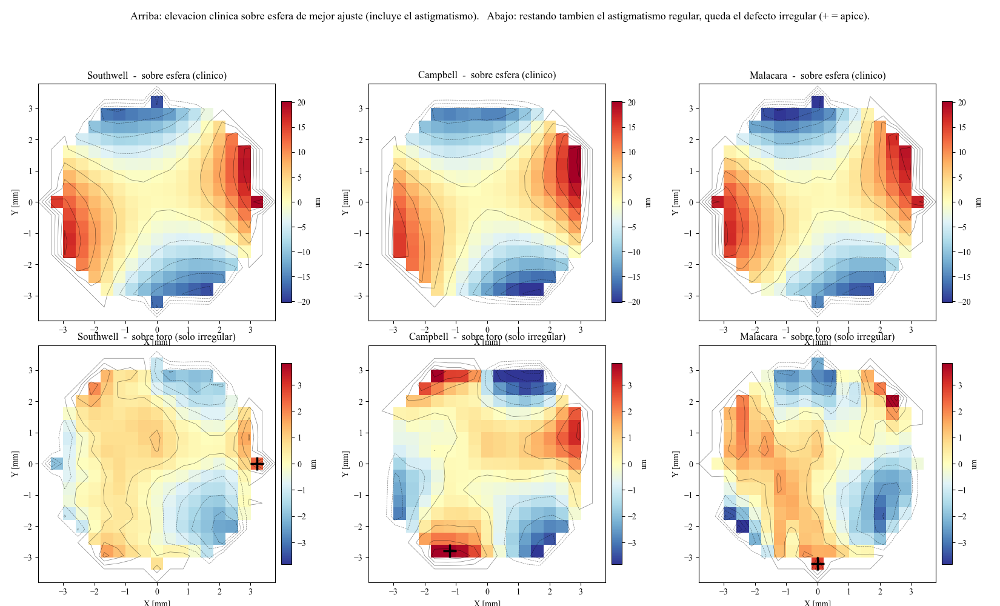

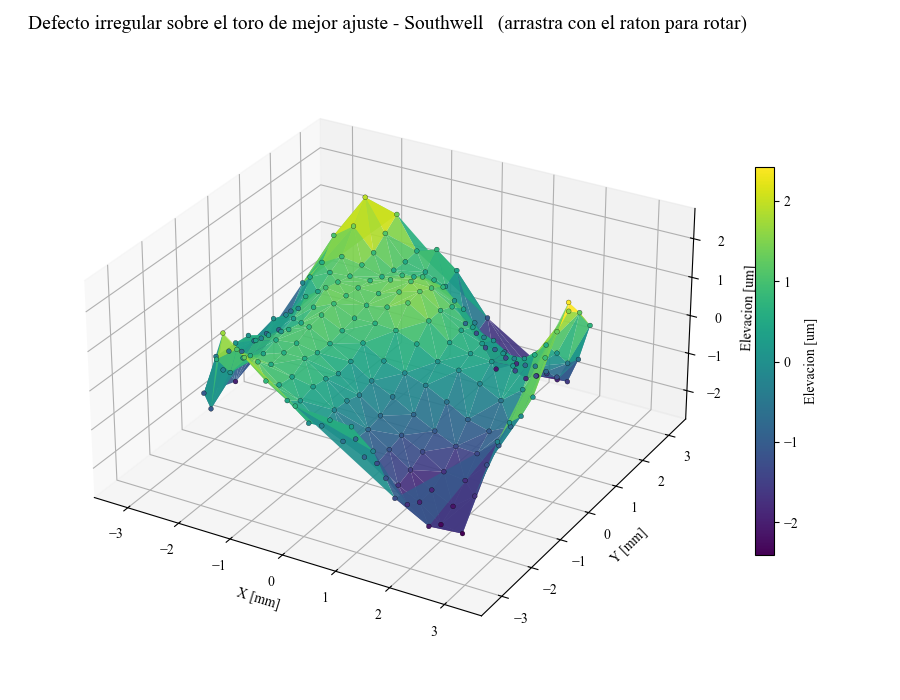

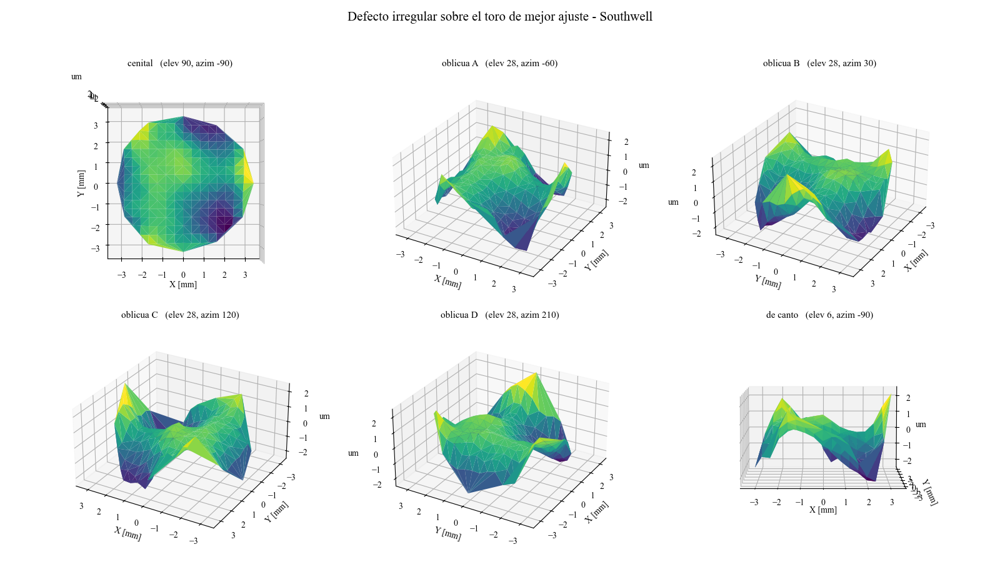

In [97]:
# =========================================================================
#  QUE HAY EXACTAMENTE EN ESTA CORNEA:  Zernike + mapas de elevacion
# =========================================================================
#  Dos preguntas que hay que contestar por separado:
#    (1) CUANTO hay de cada aberracion  -> descomposicion de Zernike
#    (2) DONDE esta el defecto          -> mapa de elevacion sobre mejor ajuste
#
#  El mapa crudo no sirve para ninguna de las dos: esta dominado por la
#  INCLINACION (85 um rms en estos datos = 341 um de los 361 de pico a valle),
#  que es descentramiento lateral entre la captura de referencia y la del
#  paciente, no forma corneal.
# =========================================================================
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['text.usetex'] = False

p, R = 0.4, 7.78
Sx, Sy, M = campo_pendientes(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref, R)
Xc = np.where(M, mat_R_X_hpref, np.nan); Xc = Xc - np.nanmean(Xc)
Yc = np.where(M, mat_R_Y_hpref, np.nan); Yc = Yc - np.nanmean(Yc)

metodos = [('Southwell', recon_southwell),
           ('Campbell',  recon_campbell),
           ('Malacara',  recon_malacara)]

recon = {}
for nombre, fn in metodos:
    Z_m, mk = fn(Sx, Sy, M, p)
    recon[nombre] = (Z_m, mk & M)

# =========================================================================
#  (1) DESCOMPOSICION DE ZERNIKE
# =========================================================================
NOMBRE = {(1, -1): 'inclinacion Y', (1, 1): 'inclinacion X',
          (2, -2): 'astigmatismo oblicuo', (2, 0): 'desenfoque',
          (2, 2): 'astigmatismo 0/90', (3, -3): 'trefoil', (3, -1): 'COMA VERTICAL',
          (3, 1): 'coma horizontal', (3, 3): 'trefoil', (4, 0): 'aberracion esferica'}

Z_sw, m_sw = recon['Southwell']
modos, coef, resid = descomponer_zernike(Z_sw, m_sw, mat_R_X_hpref, mat_R_Y_hpref, n_max=6)

print("DESCOMPOSICION DE ZERNIKE  (Southwell, coeficientes en um)")
print("-" * 62)
for k in np.argsort(-np.abs(coef))[:10]:
    n, mm = modos[k]
    if n == 0:
        continue
    print("   Z(%d,%+d)  %+9.2f   %s" % (n, mm, coef[k], NOMBRE.get((n, mm), '')))
print("-" * 62)
print("   energia por orden radial [um rms]:")
for n in range(1, 7):
    idx = [k for k, (nn, _) in enumerate(modos) if nn == n]
    etq = {1: 'inclinacion (descentramiento de captura)',
           2: 'desenfoque + astigmatismo',
           3: 'coma y trefoil  <- firma del queratocono'}.get(n, 'orden alto')
    print("      orden %d: %6.2f   %s" % (n, np.sqrt((coef[idx]**2).sum()), etq))
print("   residuo no explicado por Zernike-6: %.2f um rms  (ruido de medida)"
      % resid.std())

# comparacion de los ordenes 3+ entre los tres metodos
print("\n   coma vertical Z(3,-1) segun cada metodo [um]:")
k31 = modos.index((3, -1))
for nombre, _ in metodos:
    Zm, mk = recon[nombre]
    _, cf_m, _ = descomponer_zernike(Zm, mk, mat_R_X_hpref, mat_R_Y_hpref, n_max=6)
    print("      %-10s %+7.2f" % (nombre, cf_m[k31]))

# =========================================================================
#  (2) MAPAS DE ELEVACION SOBRE LA SUPERFICIE DE MEJOR AJUSTE
# =========================================================================
residuos = {}
for nombre, _ in metodos:
    Z_m, mk = recon[nombre]
    residuos[nombre] = {
        'esfera': quitar_mejor_ajuste(Z_m, mk, mat_R_X_hpref, mat_R_Y_hpref, 'esfera'),
        'toro':   quitar_mejor_ajuste(Z_m, mk, mat_R_X_hpref, mat_R_Y_hpref, 'toro'),
        'mask':   mk}
    #  el apice se busca SIEMPRE sobre el residuo torico: con 'esfera' el
    #  maximo cae en el lobulo del astigmatismo, en el borde de la apertura,
    #  que no es el defecto irregular que se quiere localizar.
    residuos[nombre]['apice'] = apice_cono(residuos[nombre]['toro'], mk)

print("")
print("ELEVACION SOBRE LA SUPERFICIE DE MEJOR AJUSTE  (anillo exterior excluido)")
print("-" * 86)
print("%-12s %22s %22s   %s" % ("metodo", "esfera: rms / p-v", "toro: rms / p-v",
                                "apice del defecto irregular"))
for nombre, _ in metodos:
    d = residuos[nombre]; inter = mascara_interior(d['mask']); ap = d['apice']
    txt = "-" if ap is None else "%+5.1f um en (%+.2f, %+.2f) mm" % (d['toro'][ap], Xc[ap], Yc[ap])
    print("%-12s %9.1f / %-10.1f %9.1f / %-10.1f   %s"
          % (nombre,
             np.nanstd(d['esfera'][inter]), np.ptp(d['esfera'][inter]),
             np.nanstd(d['toro'][inter]),   np.ptp(d['toro'][inter]), txt))

print("")
print("   concordancia del residuo torico entre metodos:")
nom = [n for n, _ in metodos]
for i in range(len(nom)):
    for j in range(i + 1, len(nom)):
        ra = residuos[nom[i]]['toro']; rb = residuos[nom[j]]['toro']
        mm_ = (residuos[nom[i]]['mask'] & residuos[nom[j]]['mask']
               & np.isfinite(ra) & np.isfinite(rb))
        print("      %-10s vs %-10s  r = %+.4f"
              % (nom[i], nom[j], np.corrcoef(ra[mm_], rb[mm_])[0, 1]))

# --- panel 2x3: arriba convencion clinica, abajo solo ordenes altos --------
ext = (np.nanmin(Xc) - p/2, np.nanmax(Xc) + p/2,
       np.nanmin(Yc) - p/2, np.nanmax(Yc) + p/2)
gx = np.linspace(ext[0], ext[1], M.shape[1])
gy = np.linspace(ext[2], ext[3], M.shape[0])

fig, axes = plt.subplots(2, 3, figsize=(16.5, 10))
for fila, mod in enumerate(['esfera', 'toro']):
    lim = max(escala_robusta(residuos[n][mod], residuos[n]['mask']) for n in nom)
    for col, nombre in enumerate(nom):
        d = residuos[nombre]; ax = axes[fila, col]
        vis = np.where(mascara_interior(d['mask']), d[mod], np.nan)
        im = ax.imshow(vis, origin='lower', extent=ext, cmap='RdYlBu_r',
                       vmin=-lim, vmax=lim)
        ax.contour(gx, gy, np.nan_to_num(vis), levels=10,
                   colors='k', linewidths=0.5, alpha=0.5)
        if mod == 'toro' and d['apice'] is not None:
            ax.plot(Xc[d['apice']], Yc[d['apice']], 'k+',
                    markersize=16, markeredgewidth=2.5)
        ax.set_title('%s  -  %s' % (nombre,
                     'sobre esfera (clinico)' if mod == 'esfera'
                     else 'sobre toro (solo irregular)'), fontsize=12)
        ax.set_xlabel('X [mm]'); ax.set_ylabel('Y [mm]')
        fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02, label='um')
fig.suptitle('Arriba: elevacion clinica sobre esfera de mejor ajuste (incluye el astigmatismo).   '
             'Abajo: restando tambien el astigmatismo regular, queda el defecto irregular (+ = apice).', fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

# --- vista 3D rotable del defecto irregular --------------------------------
d = residuos['Southwell']; inter = mascara_interior(d['mask'])
ver_elevacion(np.nan_to_num(np.where(inter, d['toro'], np.nan)) / 1000.0, inter,
              mat_R_X_hpref, mat_R_Y_hpref,
              'Defecto irregular sobre el toro de mejor ajuste - Southwell',
              micras=True, panel=True)

## <center> <b> Ajuste geometrico tipo Pentacam: esfera y elipsoide torico de mejor ajuste </b></center>

PARAMETROS DE LOS AJUSTES GEOMETRICOS
Southwell   (253 puntos en la zona de ajuste)
   BFS  : R = 7.7677 mm   K = 43.45 D   apice desplazado (-0.015, -0.015) mm
          elevacion sobre BFS : rms 10.19 um   pico-valle  50.4 um
   BFTE : meridiano curvo  R = 7.5718 mm (44.57 D)  Q = +0.000  eje 104.4 deg
          meridiano plano   R = 7.9802 mm (42.29 D)  Q = +0.000  eje  14.4 deg
          astigmatismo corneal = 2.28 D
          elevacion sobre BFTE: rms  1.35 um   pico-valle  10.2 um
------------------------------------------------------------------------------
Campbell   (249 puntos en la zona de ajuste)
   BFS  : R = 7.7668 mm   K = 43.45 D   apice desplazado (+0.002, -0.019) mm
          elevacion sobre BFS : rms 10.46 um   pico-valle  56.7 um
   BFTE : meridiano curvo  R = 7.5616 mm (44.63 D)  Q = +0.000  eje 104.9 deg
          meridiano plano   R = 7.9896 mm (42.24 D)  Q = +0.000  eje  14.9 deg
          astigmatismo corneal = 2.39 D
          elevacion sobre BFTE: rms  2.15 u

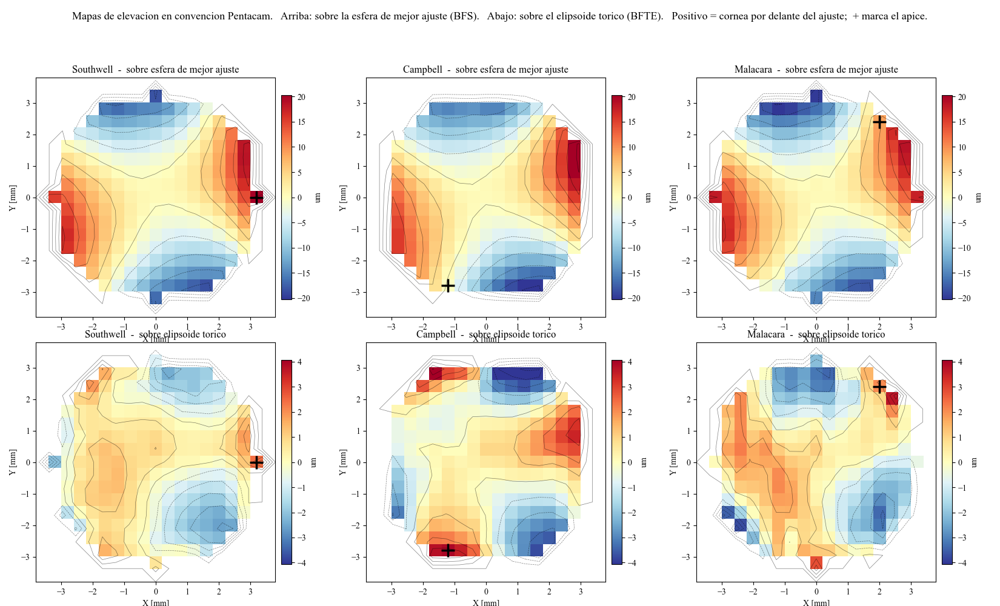

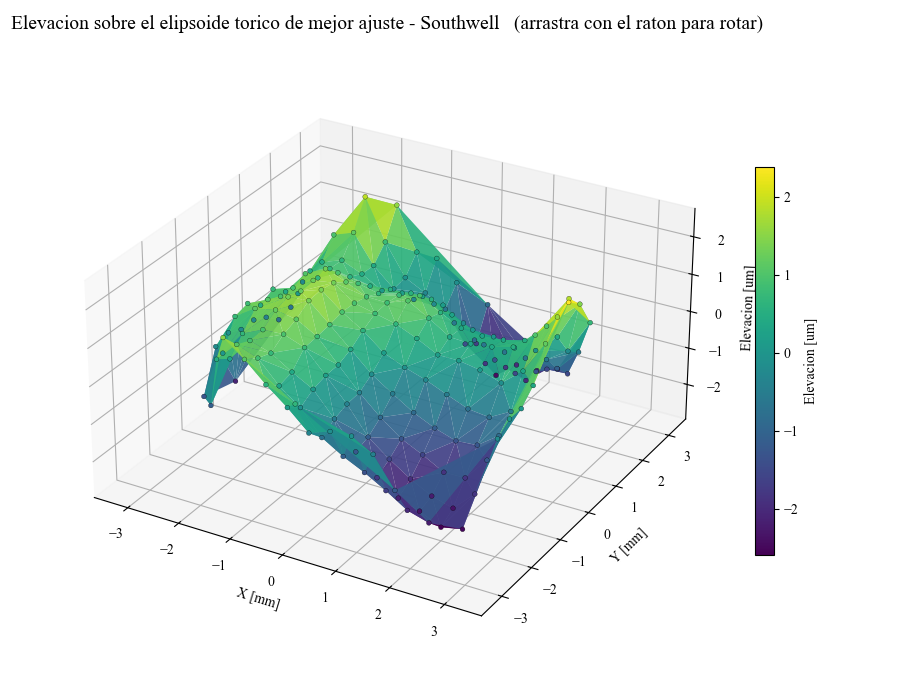

C:\Users\PC\AppData\Local\Temp\ipykernel_9280\3421937280.py:73: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig2 = plt.figure(figsize=(16, 9))


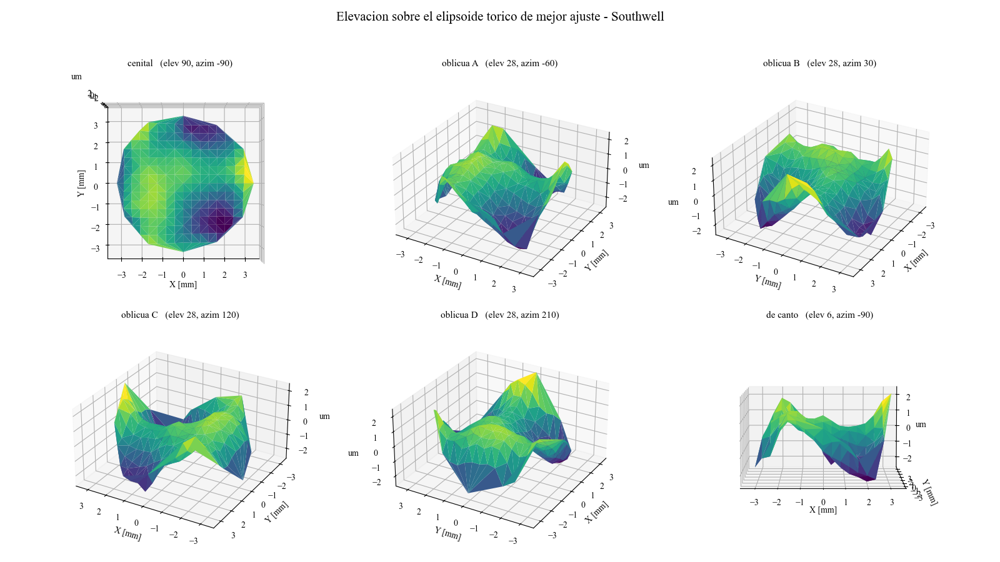

In [98]:
# =========================================================================
#  AJUSTE GEOMETRICO TIPO PENTACAM: Best Fit Sphere y Best Fit Toric Ellipsoid
# =========================================================================
#  A diferencia de la celda de Zernike, aqui NO se descompone en modos ni se
#  decide nada a partir de coeficientes.  Se hace lo que hace el topografo:
#
#    1. Se arma la superficie corneal ABSOLUTA (no la diferencial):
#          sag_cornea(x,y) = sag del casquete de referencia  -  Delta_h
#    2. Se le ajusta una superficie geometrica por minimos cuadrados no
#       lineales: una ESFERA (4 parametros) o un ELIPSOIDE TORICO (8).
#    3. El mapa de elevacion es la diferencia AXIAL punto a punto:
#          elevacion(x,y) = sag_ajuste(x,y) - sag_cornea(x,y)
#       Positivo = la cornea esta por delante del ajuste = protuberancia.
#
#  Ventaja sobre el ajuste polinomico: la esfera se ajusta COMO esfera, no
#  como paraboloide.  Sobre esta apertura (r/R = 0.47) las dos formas difieren
#  55 um en el borde, cuatro veces el rasgo que se busca.
# =========================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

plt.rcParams['text.usetex'] = False

p, R0 = 0.4, 7.78
SIGNO = +1        # +1: Delta_h positivo = cornea mas anterior (menos sag).
                  # Si el defecto sale hundido en vez de protuberante, es
                  # esta constante la que hay que invertir.
ZONA_MM = None    # diametro de la zona de ajuste [mm]; None = toda la apertura.
                  # Pentacam usa 8.0 o 9.0 mm; aqui la apertura mide 7.37 mm.

#  Cuantos parametros tiene el elipsoide torico:
#    'Q_cero'  (6) Rx, Ry, eje + apice.  Asfericidad fija en 0: toro esferico.
#    'Q_comun' (7) ademas una asfericidad Q compartida por los dos meridianos.
#    'Q_libre' (8) una asfericidad por meridiano.
#
#  Por defecto 'Q_cero'.  Sobre un casquete de solo 7.4 mm la asfericidad y la
#  toricidad son casi degeneradas: dejar Q libre mejora el ajuste 0.5 um de 4.5
#  pero cambia el astigmatismo estimado de 1.88 D a 0.55 D y triplica su
#  incertidumbre bootstrap (+-0.19 D frente a +-0.08 D).  Ademas con Q libre el
#  ajuste de Malacara converge al meridiano perpendicular.  El eje, en cambio,
#  sale 73 deg en los tres modos y es estable, asi que lo que esta mal
#  determinado es la magnitud, no la orientacion.
#  Pentacam si ajusta asfericidad, pero sobre 8-9 mm y con mucha mas densidad
#  de puntos y menos ruido: ahi la degeneracion se rompe.
MODO_TORO = 'Q_cero'


# --- 1. AJUSTE DE ESFERA --------------------------------------------------
def ajustar_esfera(x, y, z):
    """Best Fit Sphere minimizando la distancia ortogonal.

    Arranque algebraico (Kasa): para puntos sobre una esfera
        x^2+y^2+z^2 = 2*x0*x + 2*y0*y + 2*z0*z + (Rs^2 - x0^2 - y0^2 - z0^2)
    es LINEAL en (x0, y0, z0, c), asi que sale de un lstsq sin necesidad de
    valor inicial ni de riesgo de minimo local.  Despues se refina con la
    distancia geometrica real, que es la definicion estricta de mejor ajuste.
    """
    A = np.column_stack([2*x, 2*y, 2*z, np.ones_like(x)])
    q, *_ = np.linalg.lstsq(A, x**2 + y**2 + z**2, rcond=None)
    x0, y0, z0 = q[:3]
    Rs = np.sqrt(max(q[3] + x0**2 + y0**2 + z0**2, 1e-9))
    sol = least_squares(
        lambda w: np.sqrt((x-w[0])**2 + (y-w[1])**2 + (z-w[2])**2) - w[3],
        [x0, y0, z0, Rs])
    return sol.x


def sag_esfera(par, x, y, z_ref):
    """Sag de la esfera ajustada, eligiendo la rama que corresponde al casquete."""
    x0, y0, z0, Rs = par
    raiz = np.sqrt(np.maximum(Rs**2 - (x-x0)**2 - (y-y0)**2, 1e-12))
    a, b = z0 - raiz, z0 + raiz
    return a if np.std(z_ref - a) < np.std(z_ref - b) else b


# --- 2. AJUSTE DE ELIPSOIDE TORICO ---------------------------------------
def _desempaquetar(par, modo):
    """Lleva cualquiera de los tres modos a (x0, y0, z0, Rx, Ry, Qx, Qy, phi)."""
    if modo == 'Q_libre':
        return par
    if modo == 'Q_comun':
        x0, y0, z0, Rx, Ry, Q, phi = par
        return x0, y0, z0, Rx, Ry, Q, Q, phi
    x0, y0, z0, Rx, Ry, phi = par
    return x0, y0, z0, Rx, Ry, 0.0, 0.0, phi


def sag_toroide(par, x, y, modo=None):
    """Sag de una superficie biconica (elipsoide torico) con el eje girado.

        sag = (cx*xp^2 + cy*yp^2)
              / (1 + sqrt(1 - (1+Qx)*cx^2*xp^2 - (1+Qy)*cy^2*yp^2))

    Rx, Ry son los radios apicales de los dos meridianos principales y Qx, Qy
    sus asfericidades (Q=0 esfera, Q<0 elipse prolata, Q>0 oblata).  Es la
    parametrizacion estandar en optica oftalmica y esta mucho mejor
    condicionada que dar los semiejes a, b, c del elipsoide: sobre un casquete
    poco profundo los semiejes quedan casi indeterminados, mientras que los
    radios apicales estan bien definidos.
    """
    if modo is not None:
        par = _desempaquetar(par, modo)
    x0, y0, z0, Rx, Ry, Qx, Qy, phi = par
    dx, dy = x - x0, y - y0
    xp = dx*np.cos(phi) + dy*np.sin(phi)
    yp = -dx*np.sin(phi) + dy*np.cos(phi)
    cx, cy = 1.0/Rx, 1.0/Ry
    num = cx*xp**2 + cy*yp**2
    rad = 1 - (1+Qx)*cx**2*xp**2 - (1+Qy)*cy**2*yp**2
    return z0 + num / (1 + np.sqrt(np.maximum(rad, 1e-9)))


_ARRANQUE = {'Q_libre': ([0, 0, 0, R0, R0, 0, 0, 0],
                         ([-1, -1, -1, 4, 4, -3, -3, -np.pi],
                          [1, 1, 1, 12, 12, 3, 3, np.pi])),
             'Q_comun': ([0, 0, 0, R0, R0, 0, 0],
                         ([-1, -1, -1, 4, 4, -3, -np.pi],
                          [1, 1, 1, 12, 12, 3, np.pi])),
             'Q_cero':  ([0, 0, 0, R0, R0, 0],
                         ([-1, -1, -1, 4, 4, -np.pi],
                          [1, 1, 1, 12, 12, np.pi]))}


def ajustar_toroide(x, y, z, modo=None):
    """Best Fit Toric Ellipsoid. Arranca de la esfera de referencia (Q=0).

    Devuelve los 8 parametros desempaquetados, con Rx = meridiano MAS CURVO.
    """
    modo = MODO_TORO if modo is None else modo
    p0, bnd = _ARRANQUE[modo]
    sol = least_squares(lambda w: sag_toroide(w, x, y, modo) - z, p0, bounds=bnd)
    par = list(_desempaquetar(sol.x, modo))
    if par[3] > par[4]:                 # Rx = meridiano MAS CURVO (radio menor)
        par[3], par[4] = par[4], par[3]
        par[5], par[6] = par[6], par[5]
        par[7] += np.pi/2
    return np.array(par)


# --- 3. APLICACION A LOS TRES METODOS ------------------------------------
Sx, Sy, M = campo_pendientes(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref, R0)
Xc = np.where(M, mat_R_X_hpref, np.nan); Xc = Xc - np.nanmean(Xc)
Yc = np.where(M, mat_R_Y_hpref, np.nan); Yc = Yc - np.nanmean(Yc)

metodos = [('Southwell', recon_southwell),
           ('Campbell',  recon_campbell),
           ('Malacara',  recon_malacara)]

resultados = {}
print("PARAMETROS DE LOS AJUSTES GEOMETRICOS")
print("=" * 78)
for nombre, fn in metodos:
    Z_m, mk = fn(Sx, Sy, M, p)
    zona = mk & M
    if ZONA_MM is not None:
        r2_ = np.nan_to_num(Xc, nan=9e9)**2 + np.nan_to_num(Yc, nan=9e9)**2
        zona = zona & (r2_ <= (ZONA_MM/2)**2)

    xs, ys = Xc[zona], Yc[zona]
    # superficie corneal absoluta = casquete de referencia menos la elevacion
    sag_ref = R0 - np.sqrt(np.maximum(R0**2 - xs**2 - ys**2, 1e-12))
    zs = sag_ref - SIGNO * Z_m[zona]

    par_e = ajustar_esfera(xs, ys, zs)
    par_t = ajustar_toroide(xs, ys, zs)

    e_bfs = np.full(M.shape, np.nan)
    e_bfs[zona] = (sag_esfera(par_e, xs, ys, zs) - zs) * 1000
    e_bfte = np.full(M.shape, np.nan)
    e_bfte[zona] = (sag_toroide(par_t, xs, ys) - zs) * 1000
    resultados[nombre] = {'BFS': e_bfs, 'BFTE': e_bfte, 'mask': zona,
                          'par_e': par_e, 'par_t': par_t}

    Rs = par_e[3]
    Rx, Ry, Qx, Qy, phi = par_t[3], par_t[4], par_t[5], par_t[6], par_t[7]
    print("%s   (%d puntos en la zona de ajuste)" % (nombre, zona.sum()))
    print("   BFS  : R = %.4f mm   K = %.2f D   apice desplazado (%+.3f, %+.3f) mm"
          % (Rs, 337.5/Rs, par_e[0], par_e[1]))
    print("          elevacion sobre BFS : rms %5.2f um   pico-valle %5.1f um"
          % (np.nanstd(e_bfs), np.nanmax(e_bfs) - np.nanmin(e_bfs)))
    print("   BFTE : meridiano curvo  R = %.4f mm (%.2f D)  Q = %+.3f  eje %5.1f deg"
          % (Rx, 337.5/Rx, Qx, np.degrees(phi) % 180))
    print("          meridiano plano   R = %.4f mm (%.2f D)  Q = %+.3f  eje %5.1f deg"
          % (Ry, 337.5/Ry, Qy, (np.degrees(phi) + 90) % 180))
    print("          astigmatismo corneal = %.2f D" % abs(337.5/Rx - 337.5/Ry))
    print("          elevacion sobre BFTE: rms %5.2f um   pico-valle %5.1f um"
          % (np.nanstd(e_bfte), np.nanmax(e_bfte) - np.nanmin(e_bfte)))
    print("-" * 78)

# --- apice del defecto y concordancia entre metodos ----------------------
print("")
print("APICE DEL DEFECTO (sobre el elipsoide torico, nodos interiores)")
for nombre, _ in metodos:
    d = resultados[nombre]
    ap = apice_cono(d['BFTE'], d['mask'])
    if ap is None:
        print("   %-10s  -" % nombre)
    else:
        print("   %-10s %+5.1f um  en (%+.2f, %+.2f) mm   descentrado %.2f mm"
              % (nombre, d['BFTE'][ap], Xc[ap], Yc[ap], np.hypot(Xc[ap], Yc[ap])))

print("")
print("CONCORDANCIA ENTRE METODOS")
nom = [n for n, _ in metodos]
for etq in ['BFS', 'BFTE']:
    for i in range(len(nom)):
        for j in range(i+1, len(nom)):
            a_, b_ = resultados[nom[i]][etq], resultados[nom[j]][etq]
            mm_ = np.isfinite(a_) & np.isfinite(b_)
            print("   %-5s %-10s vs %-10s  r = %+.4f"
                  % (etq, nom[i], nom[j], np.corrcoef(a_[mm_], b_[mm_])[0, 1]))

# --- 4. MAPAS -------------------------------------------------------------
ext = (np.nanmin(Xc) - p/2, np.nanmax(Xc) + p/2,
       np.nanmin(Yc) - p/2, np.nanmax(Yc) + p/2)
gx = np.linspace(ext[0], ext[1], M.shape[1])
gy = np.linspace(ext[2], ext[3], M.shape[0])

fig, axes = plt.subplots(2, 3, figsize=(16.5, 10))
for fila, etq in enumerate(['BFS', 'BFTE']):
    lim = max(escala_robusta(resultados[n][etq], resultados[n]['mask']) for n in nom)
    for col, nombre in enumerate(nom):
        d = resultados[nombre]
        ax = axes[fila, col]
        vis = np.where(mascara_interior(d['mask']), d[etq], np.nan)
        im = ax.imshow(vis, origin='lower', extent=ext, cmap='RdYlBu_r',
                       vmin=-lim, vmax=lim)
        ax.contour(gx, gy, np.nan_to_num(vis), levels=10,
                   colors='k', linewidths=0.5, alpha=0.5)
        ap = apice_cono(d['BFTE'], d['mask'])
        if ap is not None:
            ax.plot(Xc[ap], Yc[ap], 'k+', markersize=16, markeredgewidth=2.5)
        ax.set_title('%s  -  sobre %s' % (nombre,
                     'esfera de mejor ajuste' if etq == 'BFS'
                     else 'elipsoide torico'), fontsize=12)
        ax.set_xlabel('X [mm]'); ax.set_ylabel('Y [mm]')
        fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02, label='um')
fig.suptitle('Mapas de elevacion en convencion Pentacam.   Arriba: sobre la esfera de '
             'mejor ajuste (BFS).   Abajo: sobre el elipsoide torico (BFTE).   '
             'Positivo = cornea por delante del ajuste;  + marca el apice.',
             fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

# --- 5. vista 3D rotable --------------------------------------------------
d = resultados['Southwell']
inter = mascara_interior(d['mask'])
ver_elevacion(np.nan_to_num(np.where(inter, d['BFTE'], np.nan)) / 1000.0, inter,
              mat_R_X_hpref, mat_R_Y_hpref,
              'Elevacion sobre el elipsoide torico de mejor ajuste - Southwell',
              micras=True, panel=True)

## <center> <b> Enhanced Best Fit Sphere (Belin / Ambrosio) </b></center>

ENHANCED BEST FIT SPHERE   (exclusion de 3.5 mm, modelo 'esfera')
Southwell   BFS: R = 7.7677 mm   K = 43.45 D
   centro en max. elevacion BFS   (+2.80, +1.20) mm | 214 pts | R_EBFS 7.7117 mm
      elevacion ahi:  BFS  +18.5  ->  EBFS  +32.9 um    INDICE =  +14.4 um
   centro en apice irregular      (-1.60, +2.00) mm | 203 pts | R_EBFS 7.8006 mm
      elevacion ahi:  BFS   -7.6  ->  EBFS  -15.5 um    INDICE =   -7.8 um
------------------------------------------------------------------------------------
Campbell   BFS: R = 7.7668 mm   K = 43.45 D
   centro en max. elevacion BFS   (+2.80, +1.20) mm | 211 pts | R_EBFS 7.7113 mm
      elevacion ahi:  BFS  +21.1  ->  EBFS  +36.4 um    INDICE =  +15.2 um
   centro en apice irregular      (+2.40, +0.80) mm | 200 pts | R_EBFS 7.7186 mm
      elevacion ahi:  BFS  +15.2  ->  EBFS  +28.8 um    INDICE =  +13.6 um
------------------------------------------------------------------------------------
Malacara   BFS: R = 7.7703 mm   K = 43.43 D
   cent

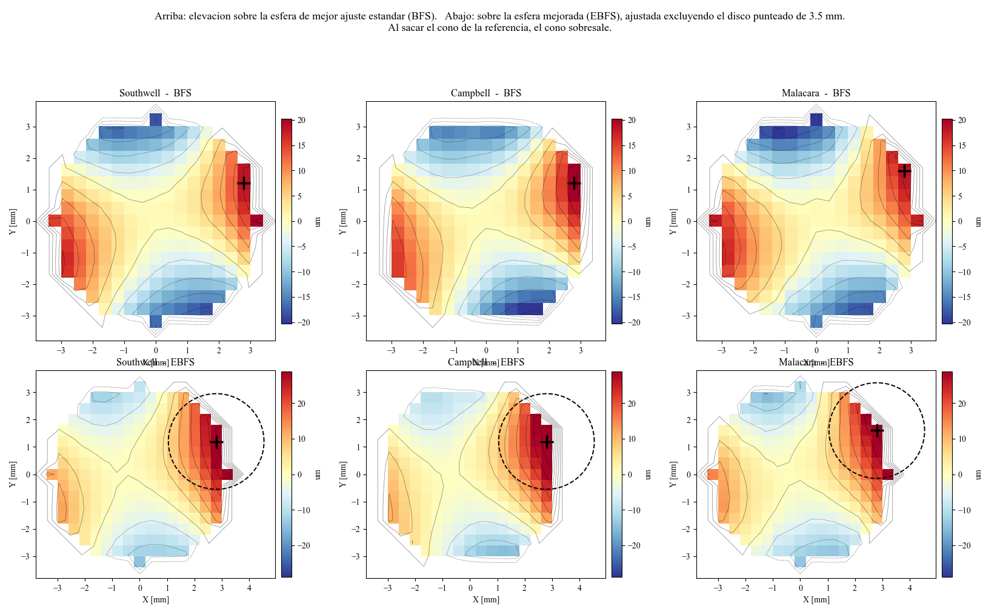


SENSIBILIDAD AL DIAMETRO DE EXCLUSION  (Southwell, centro = max. elevacion BFS)
   diametro n usados     R_EBFS       indice
      2.5 mm      232     7.7349        +7.5 um
      3.0 mm      222     7.7172       +11.8 um
      3.5 mm      214     7.7117       +14.4 um
      4.0 mm      210     7.7089       +15.6 um
      4.5 mm      197     7.7022       +19.5 um


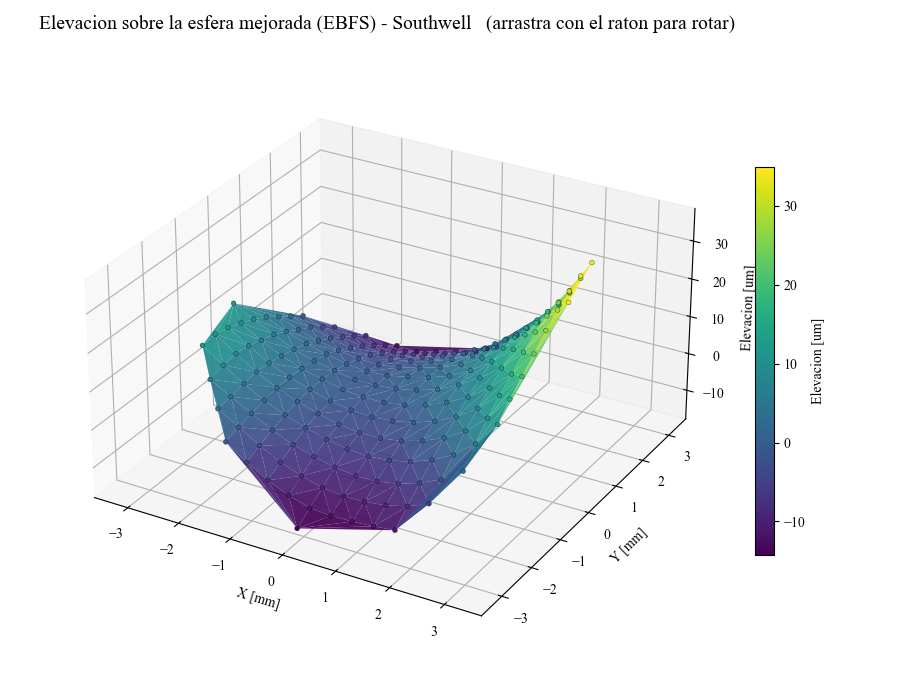

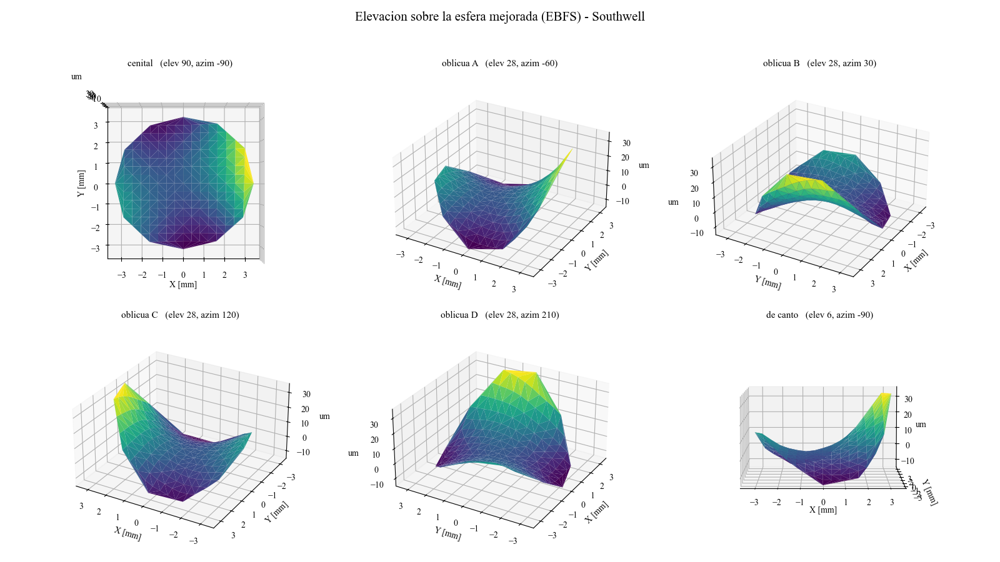

In [99]:
# =========================================================================
#  ENHANCED BEST FIT SPHERE  (metodologia Belin / Ambrosio)
# =========================================================================
#  El problema que resuelve: la BFS estandar se ajusta a TODOS los puntos,
#  incluido el propio cono.  El cono tira del ajuste hacia si mismo y se
#  auto-oculta: cuanto mas pronunciado, mas se lleva la esfera con el.
#
#  La solucion de Belin y Ambrosio:
#    1. Ajustar la BFS estandar.
#    2. EXCLUIR una zona central de 3.5 mm de diametro alrededor del punto
#       mas delgado y reajustar la esfera solo con la periferia sana.
#    3. Medir la elevacion contra esa esfera "mejorada" (EBFS).  El cono ya
#       no forma parte de la referencia, asi que sobresale de verdad.
#    4. El indice diagnostico es la DIFERENCIA de elevacion en ese punto
#       entre el mapa EBFS y el BFS.
#
#  ADVERTENCIA METODOLOGICA IMPORTANTE
#  -----------------------------------
#  Belin/Ambrosio centra la exclusion en el punto mas delgado medido por
#  PAQUIMETRIA, que es un dato independiente del mapa de elevacion.  Ese
#  montaje de Hartmann no mide espesor, asi que aqui hay que sustituirlo por
#  un criterio derivado del propio mapa, y eso es circular.
#
#  La eleccion NO es inocua: sobre estos datos el indice pasa de +11.4 um
#  (centrando en el maximo de la elevacion BFS) a -1.3 um (centrando en el
#  apice del residuo irregular).  Por eso la celda calcula los DOS y los
#  imprime juntos.  Mientras esa dispersion siga ahi, el numero NO es
#  clinicamente citable: sirve para ver el cono, no para graduarlo.
#  Los umbrales publicados (>12 um sospechoso, >15 um patologico) se definen
#  ademas sobre zona de 8 mm; esta apertura mide 7.37 mm.
# =========================================================================
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['text.usetex'] = False

DIAM_EXCLUSION = 3.5     # diametro de la zona excluida [mm] (Belin/Ambrosio)
MODELO_EBFS = 'esfera'   # 'esfera' -> EBFS ; 'toro' -> version mejorada del BFTE


def _ajustar(xs, ys, zs, modelo):
    """Ajusta esfera o toro y devuelve (parametros, funcion de sag)."""
    if modelo == 'esfera':
        par = ajustar_esfera(xs, ys, zs)
        return par, (lambda X, Y, Zref: sag_esfera(par, X, Y, Zref))
    par = ajustar_toroide(xs, ys, zs)
    return par, (lambda X, Y, Zref: sag_toroide(par, X, Y))


def superficie_absoluta(Z_m, zona):
    """sag de la cornea = casquete de referencia - elevacion diferencial."""
    xs, ys = Xc[zona], Yc[zona]
    sag_ref = R0 - np.sqrt(np.maximum(R0**2 - xs**2 - ys**2, 1e-12))
    return xs, ys, sag_ref - SIGNO * Z_m[zona]


def mapa_elevacion(par_sag, xs, ys, zs, zona):
    """Elevacion axial [um] sobre toda la zona, positiva hacia delante."""
    out = np.full(M.shape, np.nan)
    out[zona] = (par_sag(xs, ys, zs) - zs) * 1000
    return out


def enhanced(Z_m, zona, centro, modelo=None, diam=None):
    """Reajusta excluyendo un disco de diametro `diam` centrado en `centro`."""
    modelo = MODELO_EBFS if modelo is None else modelo
    diam = DIAM_EXCLUSION if diam is None else diam
    xs, ys, zs = superficie_absoluta(Z_m, zona)
    fuera = np.hypot(xs - centro[0], ys - centro[1]) > diam/2.0
    if fuera.sum() < 30:
        raise ValueError("quedan %d puntos fuera de la exclusion: insuficiente" % fuera.sum())
    par, sag = _ajustar(xs[fuera], ys[fuera], zs[fuera], modelo)
    return par, mapa_elevacion(sag, xs, ys, zs, zona), fuera.sum()


# =========================================================================
#  APLICACION A LOS TRES METODOS
# =========================================================================
metodos = [('Southwell', recon_southwell),
           ('Campbell',  recon_campbell),
           ('Malacara',  recon_malacara)]

Sx, Sy, M = campo_pendientes(mat_R_X, mat_R_Y, mat_R_X_hpref, mat_R_Y_hpref, R0)
Xc = np.where(M, mat_R_X_hpref, np.nan); Xc = Xc - np.nanmean(Xc)
Yc = np.where(M, mat_R_Y_hpref, np.nan); Yc = Yc - np.nanmean(Yc)

ebfs = {}
print("ENHANCED BEST FIT SPHERE   (exclusion de %.1f mm, modelo '%s')"
      % (DIAM_EXCLUSION, MODELO_EBFS))
print("=" * 84)
for nombre, fn in metodos:
    Z_m, mk = fn(Sx, Sy, M, p)
    zona = mk & M
    xs, ys, zs = superficie_absoluta(Z_m, zona)

    # --- BFS estandar, sobre todos los puntos ---
    par0, sag0 = _ajustar(xs, ys, zs, MODELO_EBFS)
    E_bfs = mapa_elevacion(sag0, xs, ys, zs, zona)

    # --- los dos criterios de centrado, calculados en paralelo ---
    ap_elev = apice_cono(E_bfs, zona)                    # maximo de la elevacion BFS
    A_ = np.column_stack([xs**2 + ys**2, xs**2 - ys**2, xs*ys,
                          xs, ys, np.ones_like(xs)])
    irr = np.full(M.shape, np.nan)
    irr[zona] = -(zs - A_ @ np.linalg.lstsq(A_, zs, rcond=None)[0]) * 1000
    ap_irr = apice_cono(irr, zona)                       # apice del defecto irregular

    fila = {'BFS': E_bfs, 'zona': zona, 'R_bfs': par0[3]}
    print("%s   BFS: R = %.4f mm   K = %.2f D" % (nombre, par0[3], 337.5/par0[3]))
    for etq, ap in [('max. elevacion BFS', ap_elev), ('apice irregular', ap_irr)]:
        if ap is None:
            continue
        centro = (Xc[ap], Yc[ap])
        par, E_e, n_us = enhanced(Z_m, zona, centro)
        indice = E_e[ap] - E_bfs[ap]
        fila['EBFS_' + etq] = E_e
        fila['centro_' + etq] = centro
        print("   centro en %-20s (%+.2f, %+.2f) mm | %3d pts | R_EBFS %.4f mm"
              % (etq, centro[0], centro[1], n_us, par[3]))
        print("      elevacion ahi:  BFS %+6.1f  ->  EBFS %+6.1f um    INDICE = %+6.1f um"
              % (E_bfs[ap], E_e[ap], indice))
    ebfs[nombre] = fila
    print("-" * 84)

print("")
print("Dispersion del indice segun el criterio de centrado: es la razon por la que")
print("este numero no se puede citar como diagnostico sin un dato de paquimetria.")

# =========================================================================
#  MAPAS: BFS frente a EBFS
# =========================================================================
ext = (np.nanmin(Xc) - p/2, np.nanmax(Xc) + p/2,
       np.nanmin(Yc) - p/2, np.nanmax(Yc) + p/2)
gx = np.linspace(ext[0], ext[1], M.shape[1])
gy = np.linspace(ext[2], ext[3], M.shape[0])
clave_e = 'EBFS_max. elevacion BFS'

fig, axes = plt.subplots(2, 3, figsize=(16.5, 10))
nom = [n for n, _ in metodos]
for fila_i, clave in enumerate(['BFS', clave_e]):
    disponibles = [n for n in nom if clave in ebfs[n]]
    lim = max(escala_robusta(ebfs[n][clave], ebfs[n]['zona']) for n in disponibles)
    for col, nombre in enumerate(nom):
        ax = axes[fila_i, col]
        if clave not in ebfs[nombre]:
            ax.axis('off'); continue
        d = ebfs[nombre]
        vis = np.where(mascara_interior(d['zona']), d[clave], np.nan)
        im = ax.imshow(vis, origin='lower', extent=ext, cmap='RdYlBu_r',
                       vmin=-lim, vmax=lim)
        ax.contour(gx, gy, np.nan_to_num(vis), levels=10,
                   colors='k', linewidths=0.5, alpha=0.5)
        c = d.get('centro_max. elevacion BFS')
        if c is not None:
            ax.plot(c[0], c[1], 'k+', markersize=16, markeredgewidth=2.5)
            if fila_i == 1:   # dibujar la zona excluida del ajuste
                th = np.linspace(0, 2*np.pi, 200)
                ax.plot(c[0] + DIAM_EXCLUSION/2*np.cos(th),
                        c[1] + DIAM_EXCLUSION/2*np.sin(th),
                        'k--', linewidth=1.4)
        ax.set_title('%s  -  %s' % (nombre, 'BFS' if fila_i == 0 else 'EBFS'), fontsize=12)
        ax.set_xlabel('X [mm]'); ax.set_ylabel('Y [mm]')
        fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02, label='um')
fig.suptitle('Arriba: elevacion sobre la esfera de mejor ajuste estandar (BFS).   '
             'Abajo: sobre la esfera mejorada (EBFS), ajustada excluyendo el disco '
             'punteado de %.1f mm.\nAl sacar el cono de la referencia, el cono sobresale.'
             % DIAM_EXCLUSION, fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

# --- sensibilidad al diametro de exclusion -------------------------------
print("")
print("SENSIBILIDAD AL DIAMETRO DE EXCLUSION  (Southwell, centro = max. elevacion BFS)")
Z_m, mk = recon_southwell(Sx, Sy, M, p)
zona = mk & M
xs, ys, zs = superficie_absoluta(Z_m, zona)
par0, sag0 = _ajustar(xs, ys, zs, MODELO_EBFS)
E0 = mapa_elevacion(sag0, xs, ys, zs, zona)
ap = apice_cono(E0, zona)
print("   %8s %8s %10s %12s" % ("diametro", "n usados", "R_EBFS", "indice"))
for D in [2.5, 3.0, 3.5, 4.0, 4.5]:
    try:
        par, E_e, n_us = enhanced(Z_m, zona, (Xc[ap], Yc[ap]), diam=D)
        print("   %6.1f mm %8d %10.4f %+11.1f um" % (D, n_us, par[3], E_e[ap] - E0[ap]))
    except ValueError as e:
        print("   %6.1f mm   %s" % (D, e))

# --- vista 3D rotable del mapa EBFS --------------------------------------
d = ebfs['Southwell']
if clave_e in d:
    inter = mascara_interior(d['zona'])
    ver_elevacion(np.nan_to_num(np.where(inter, d[clave_e], np.nan)) / 1000.0, inter,
                  mat_R_X_hpref, mat_R_Y_hpref,
                  'Elevacion sobre la esfera mejorada (EBFS) - Southwell',
                  micras=True, panel=True)